# Stage A: Data Preparation Check

This section verifies that the prepared dataset was generated correctly from the three public data files.  
The purpose is to confirm the sample period, number of quarters, number of tickers, and sector-level coverage before running the baseline stock selection model.

In [ ]:
from pathlib import Path
import os
import sys

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

project_name = "Assignment1_Quanjing He_qh2305"
drive_project = Path("/content/drive/MyDrive/GR5398") / project_name
custom = os.environ.get("GR5398_PROJECT_DIR")
candidates = ([Path(custom)] if custom else []) + [
    Path.cwd(),
    Path.cwd() / project_name,
    drive_project,
]
project_dir = next(
    (p for p in candidates if (p / "prepare_data.py").is_file()
     and (p / "requirements.txt").is_file()),
    None
)
if project_dir is None:
    raise FileNotFoundError(
        "Cannot locate the project. Open Jupyter in the submission folder "
        "or set GR5398_PROJECT_DIR. See README.md for data setup."
    )

os.chdir(project_dir)
%pip install -q -r requirements.txt

print("Working directory:", Path.cwd())
print("Python:", sys.version.split()[0])
print("CPU cores:", os.cpu_count())
for name in [
    "prepared/final_ratios.csv", "prepared/daily.csv",
    "prepared/sector10.xlsx", "data/finrl_trading.db",
    "data/fundamental_data_full.csv",
    "data/sp500_historical_constituents.csv",
    "fundamental_run_model.py", "ml_model.py",
    "requirements.txt"
]:
    print(f"{name}: {'OK' if Path(name).is_file() else 'MISSING'}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working directory: /content/drive/MyDrive/GR5398/Assignment1_Quanjing He_qh2305
Python: 3.13.15
CPU cores: 12
prepared/final_ratios.csv: OK
prepared/daily.csv: OK
prepared/sector10.xlsx: OK
fundamental_run_model.py: OK
ml_model.py: OK
requirements.txt: OK


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

prepared_path = Path("prepared")

final_ratios = pd.read_csv(prepared_path / "final_ratios.csv")
daily = pd.read_csv(prepared_path / "daily.csv")

print("final_ratios shape:", final_ratios.shape)
print("daily shape:", daily.shape)

print("\nfinal_ratios columns:")
print(final_ratios.columns.tolist())

print("\ndaily columns:")
print(daily.columns.tolist())

print("\nFundamental date range:")
print(final_ratios["date"].min(), "to", final_ratios["date"].max())

print("\nDaily price date range:")
print(daily["datadate"].min(), "to", daily["datadate"].max())

print("\nNumber of unique quarters:", final_ratios["date"].nunique())
print("Number of unique tickers in final_ratios:", final_ratios["tic"].nunique())
print("Number of unique tickers in daily:", daily["tic"].nunique())

sector_files = sorted(prepared_path.glob("sector*.xlsx"))
print("\nNumber of sector files:", len(sector_files))
print([p.name for p in sector_files])

final_ratios shape: (19007, 59)
daily shape: (1261325, 11)

final_ratios columns:
['tic', 'date', 'gsector', 'adj_close_q', 'EPS', 'BPS', 'DPS', 'cur_ratio', 'quick_ratio', 'cash_ratio', 'acc_rec_turnover', 'debt_ratio', 'debt_to_equity', 'pe', 'ps', 'pb', 'roe', 'net_income_ratio', 'y_return', 'gross_margin', 'operating_margin', 'ebitda_margin', 'pretax_margin', 'effective_tax_rate', 'ebt_per_ebit', 'asset_turnover', 'fixed_asset_turnover', 'inventory_turnover', 'payables_turnover', 'wc_turnover', 'debt_to_assets', 'debt_to_capital', 'lt_debt_to_capital', 'interest_coverage', 'debt_service_coverage', 'debt_to_mktcap', 'fcf_per_share', 'ocf_per_share', 'cash_per_share', 'capex_per_share', 'fcf_to_ocf', 'ocf_ratio', 'ocf_to_sales', 'ocf_coverage', 'st_ocf_coverage', 'capex_coverage', 'revenue_per_share', 'tangible_bvps', 'interest_debt_per_share', 'peg', 'price_to_fcf', 'price_to_ocf', 'ev_multiple', 'dividend_payout', 'dividend_yield', 'div_capex_coverage', 'solvency_ratio', 'reportdat

# Stage B: Baseline Reproduction

I use the prepared dataset generated by `prepare_data.py` as the input for the baseline stock selection and backtest.

The prepared files are stored under `prepared/`:

- `final_ratios.csv`: quarterly fundamental features and labels
- `sector10.xlsx` to `sector60.xlsx`: sector-level modeling files
- `daily.csv`: daily adjusted price data for backtesting

In [ ]:
from pathlib import Path

data_path = Path("prepared")
results_path = Path("results")
baseline_path = results_path / "baseline"

results_path.mkdir(exist_ok=True)
baseline_path.mkdir(parents=True, exist_ok=True)

print("Prepared data path:", data_path.resolve())
print("Results path:", results_path.resolve())
print("Baseline results path:", baseline_path.resolve())

Prepared data path: /content/drive/MyDrive/GR5398/Assignment1_Quanjing He_qh2305/prepared
Results path: /content/drive/MyDrive/GR5398/Assignment1_Quanjing He_qh2305/results
Baseline results path: /content/drive/MyDrive/GR5398/Assignment1_Quanjing He_qh2305/results/baseline


## Trade Start Index

The prepared data contains 42 quarterly observations from 2015-06-30 to 2025-09-30.  
Based on the output of `prepare_data.py`, I use `first_trade_index = 21`, which starts out-of-sample trading from 2020-09-30.

In [ ]:
quarters = sorted(final_ratios["date"].unique())

first_trade_index = 21

print("Number of quarters:", len(quarters))
print("First quarter:", quarters[0])
print("Last quarter:", quarters[-1])
print("first_trade_index:", first_trade_index)
print("Trading starts at:", quarters[first_trade_index])
print("Number of out-of-sample trading quarters:", len(quarters) - first_trade_index)

Number of quarters: 42
First quarter: 2015-06-30
Last quarter: 2025-09-30
first_trade_index: 21
Trading starts at: 2020-09-30
Number of out-of-sample trading quarters: 21


## Baseline Stock Selection Models

I train the baseline stock selection models across all 11 sectors using XGBoost, LightGBM, and Random Forest. The out-of-sample period starts from 2020-09-30.

In [ ]:
import subprocess

sector_ids = list(range(10, 61, 5))
target_date = pd.Timestamp(quarters[first_trade_index])

expected_files = [
    "df_predict_rf.csv",
    "df_predict_gbm.csv",
    "df_predict_xgb.csv",
    "df_predict_best.csv",
    "df_best_model_name.csv",
    "df_model_score.csv"
]

def is_complete(folder, expected_dates):
    if not all(
        (folder / f).is_file() and (folder / f).stat().st_size > 0
        for f in expected_files
    ):
        return False

    try:
        models = pd.read_csv(folder / "df_best_model_name.csv", index_col=0)
        scores = pd.read_csv(folder / "df_model_score.csv", index_col=0)
        predictions = pd.read_csv(folder / "df_predict_best.csv", index_col=0)

        return (
            pd.DatetimeIndex(pd.to_datetime(models.index)).equals(expected_dates)
            and pd.DatetimeIndex(pd.to_datetime(scores.index)).equals(expected_dates)
            and models["model_name"].notna().all()
            and scores.shape == (len(expected_dates), 3)
            and scores.notna().all().all()
            and predictions.notna().any().any()
        )
    except Exception:
        return False


for sector in sector_ids:
    sector_name = f"sector{sector}"
    sector_file = data_path / f"{sector_name}.xlsx"
    output_dir = results_path / sector_name

    dates = pd.DatetimeIndex(
        pd.to_datetime(
            pd.read_excel(sector_file, usecols=["date"])["date"]
        ).dropna().unique()
    ).sort_values()

    if target_date not in dates:
        raise ValueError(f"{sector_name}: target date not found.")

    sector_start_index = dates.get_loc(target_date)
    expected_dates = dates[sector_start_index:]

    if len(expected_dates) != len(quarters) - first_trade_index:
        raise ValueError(f"{sector_name}: unexpected trading dates.")

    if is_complete(output_dir, expected_dates):
        print(f"{sector_name}: already completed, skipping.", flush=True)
        continue

    output_dir.mkdir(parents=True, exist_ok=True)

    print(
        f"\nRunning {sector_name} "
        f"(first_trade_index={sector_start_index})...",
        flush=True
    )

    cmd = [
        sys.executable, "-u", "fundamental_run_model.py",
        "-sector_name", sector_name,
        "-fundamental", str(data_path / "final_ratios.csv"),
        "-sector", str(sector_file),
        "-first_trade_index", str(sector_start_index)
    ]

    log_path = output_dir / "training.log"
    has_error = False

    with open(log_path, "w", encoding="utf-8") as log:
        process = subprocess.Popen(
            cmd,
            cwd=project_dir,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            errors="replace",
            bufsize=1
        )

        for line in process.stdout:
            log.write(line)
            log.flush()

            if "Traceback" in line:
                has_error = True

            if "Trade Date:" in line or "Time Spent:" in line:
                print(line.strip(), flush=True)

        process.wait()

    if (
        process.returncode != 0
        or has_error
        or not is_complete(output_dir, expected_dates)
    ):
        raise RuntimeError(
            f"{sector_name} failed. Check {log_path}"
        )

    print(f"{sector_name}: completed successfully.", flush=True)

print("\nAll 11 sectors completed successfully!")

sector10: already completed, skipping.

Running sector15 (first_trade_index=20)...
Trade Date:  2020-09-30 00:00:00
Trade Date:  2020-12-31 00:00:00
Trade Date:  2021-03-31 00:00:00
Trade Date:  2021-06-30 00:00:00
Trade Date:  2021-09-30 00:00:00
Trade Date:  2021-12-31 00:00:00
Trade Date:  2022-03-31 00:00:00
Trade Date:  2022-06-30 00:00:00
Trade Date:  2022-09-30 00:00:00
Trade Date:  2022-12-31 00:00:00
Trade Date:  2023-03-31 00:00:00
Trade Date:  2023-06-30 00:00:00
Trade Date:  2023-09-30 00:00:00
Trade Date:  2023-12-31 00:00:00
Trade Date:  2024-03-31 00:00:00
Trade Date:  2024-06-30 00:00:00
Trade Date:  2024-09-30 00:00:00
Trade Date:  2024-12-31 00:00:00
Trade Date:  2025-03-31 00:00:00
Trade Date:  2025-06-30 00:00:00
Trade Date:  2025-09-30 00:00:00
Time Spent: 11.395820 minutes
sector15: completed successfully.

Running sector20 (first_trade_index=21)...
Trade Date:  2020-09-30 00:00:00
Trade Date:  2020-12-31 00:00:00
Trade Date:  2021-03-31 00:00:00
Trade Date:  2021


## Baseline Stock Selection

I combine the predictions from all 11 sectors and select the top 25% of stocks by predicted return. Predictions are updated from each reporting date and carried forward within the quarter.


In [ ]:

def quarter_reportday_ffill(df):
    df = df.copy()
    df.index = pd.to_datetime(df.index)

    full_idx = pd.bdate_range(df.index.min(), df.index.max())
    out = df.reindex(full_idx).sort_index().copy()
    idx = out.index

    for col in out.columns:
        s = out[col]
        if not s.notna().any():
            continue

        dates = s.dropna().index
        for i, t0 in enumerate(dates):
            val = s.at[t0]
            t1 = dates[i + 1] if i + 1 < len(dates) else None
            cap = (t0.to_period("Q") + 1).end_time.normalize()

            mask = (idx > t0) & (
                idx < (t1 if t1 is not None and t1 <= cap
                       else cap + pd.Timedelta("1ns"))
            )
            out.loc[mask, col] = val

    return out


# Combine predictions from all sectors
sector_predictions = []

for sector in sector_ids:
    path = results_path / f"sector{sector}" / "df_predict_best.csv"

    df = pd.read_csv(path, index_col=0)
    df.index = pd.to_datetime(df.index)
    df = quarter_reportday_ffill(df)

    sector_predictions.append(df)

all_predictions = pd.concat(sector_predictions, axis=1)

# Select the top 25% of stocks each day
selected = []

for date, predictions in all_predictions.iterrows():
    predictions = predictions.dropna()

    if predictions.empty:
        continue

    threshold = predictions.quantile(0.75)
    top_stocks = predictions[predictions >= threshold]

    for tic, value in top_stocks.items():
        selected.append((tic, value, date))

stock_selected = pd.DataFrame(
    selected,
    columns=["tic", "predicted_return", "trade_date"]
)

# Save baseline stock selection
output_file = baseline_path / "stock_selected.csv"
stock_selected.to_csv(output_file, index=False)

print("Saved to:", output_file)
print("Shape:", stock_selected.shape)
print("Unique stocks:", stock_selected["tic"].nunique())
print("Unique dates:", stock_selected["trade_date"].nunique())
print("Date range:",
      stock_selected["trade_date"].min(),
      "to",
      stock_selected["trade_date"].max())

display(stock_selected.head())


Saved to: results/baseline/stock_selected.csv
Shape: (166012, 3)
Unique stocks: 429
Unique dates: 1394
Date range: 2020-07-23 00:00:00 to 2025-11-25 00:00:00


,tic,predicted_return,trade_date
0,DHR,0.016777,2020-07-23
1,DHR,0.016777,2020-07-24
2,DHR,0.016777,2020-07-27
3,DHR,0.016777,2020-07-28
4,DHR,0.016777,2020-07-29



## Baseline Equal-Weight Portfolio

I construct an equal-weight portfolio using the selected stocks. Each selected stock receives the same weight on a given signal date.


In [ ]:

# Construct equal-weight portfolio
selected_stocks = pd.read_csv(
    baseline_path / "stock_selected.csv",
    parse_dates=["trade_date"]
)

portfolio_weights = pd.crosstab(
    selected_stocks["trade_date"],
    selected_stocks["tic"]
).astype(float)

portfolio_weights = portfolio_weights.div(
    portfolio_weights.sum(axis=1), axis=0
)

portfolio_weights.index.name = "date"

# Save portfolio weights
weights_file = baseline_path / "portfolio_weights.csv"
portfolio_weights.to_csv(weights_file)

print("Portfolio weights shape:", portfolio_weights.shape)
print("Date range:", portfolio_weights.index.min(),
      "to", portfolio_weights.index.max())
print("Stocks:", portfolio_weights.shape[1])
print("Weight sums:",
      portfolio_weights.sum(axis=1).min(),
      "to",
      portfolio_weights.sum(axis=1).max())

display(portfolio_weights.iloc[:5, :8])


Portfolio weights shape: (1394, 429)
Date range: 2020-07-23 00:00:00 to 2025-11-25 00:00:00
Stocks: 429
Weight sums: 0.9999999999999971 to 1.0000000000000036


tic,A,AAL,AAPL,ABBV,ABC,ABMD,ABT,ACGL
date,,,,,,,,
2020-07-23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2020-07-24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2020-07-27,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2020-07-28,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2020-07-29,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



## Baseline Backtest

I follow the reference backtest with equal weights and a transaction cost of 0.1% of turnover. Missing stock returns are set to zero to reproduce the baseline. This assumption will be revisited when evaluating the strategy.


In [ ]:

# Align baseline intraday returns and portfolio weights

baseline_prices = daily[
    ["tic", "datadate", "open_adj", "close_adj"]
].copy()

baseline_prices["datadate"] = pd.to_datetime(
    baseline_prices["datadate"]
)

baseline_prices["intraday_return"] = (
    baseline_prices["close_adj"] /
    baseline_prices["open_adj"] - 1
)

baseline_prices.loc[
    (baseline_prices["open_adj"] <= 0) |
    (baseline_prices["close_adj"] <= 0),
    "intraday_return"
] = np.nan

return_matrix = baseline_prices.pivot(
    index="datadate",
    columns="tic",
    values="intraday_return"
)

portfolio_weights.index = pd.to_datetime(
    portfolio_weights.index
)

aligned_dates = (
    portfolio_weights.index
    .intersection(return_matrix.index)
    .sort_values()
)

weights_aligned = portfolio_weights.reindex(
    index=aligned_dates,
    fill_value=0
)

returns_aligned = return_matrix.reindex(
    index=aligned_dates,
    columns=weights_aligned.columns
)

assert weights_aligned.index.equals(returns_aligned.index)

print("Baseline trading days:", len(aligned_dates))
print("Missing stock returns:", returns_aligned.isna().sum().sum())


In [ ]:

# Baseline backtest
baseline_returns = returns_aligned.fillna(0.0)

gross_ret = (weights_aligned * baseline_returns).sum(axis=1)
turnover = weights_aligned.diff().abs().sum(axis=1)

fee_rate = 0.001
cost = fee_rate * turnover
cost.iloc[0] = 0.0

net_ret = gross_ret - cost
nav = (1 + net_ret).cumprod()

baseline_backtest = pd.DataFrame({
    "gross_ret": gross_ret,
    "turnover": turnover,
    "cost": cost,
    "net_ret": net_ret,
    "nav": nav
})

initial_date = baseline_backtest.index[0] - pd.Timedelta(days=1)

initial_row = pd.DataFrame({
    "gross_ret": [0.0],
    "turnover": [0.0],
    "cost": [0.0],
    "net_ret": [0.0],
    "nav": [1.0]
}, index=[initial_date])

baseline_backtest = pd.concat(
    [initial_row, baseline_backtest]
)

baseline_backtest.index.name = "date"

output_file = baseline_path / "baseline_backtest.csv"
baseline_backtest.to_csv(output_file)

print("Saved to:", output_file)
print("Shape:", baseline_backtest.shape)
print("Final NAV:", round(baseline_backtest["nav"].iloc[-1], 4))
print("Average daily turnover:", round(turnover.mean(), 4))
print("Total transaction cost:", round(cost.sum(), 4))

display(baseline_backtest.head())
display(baseline_backtest.tail())


Saved to: results/baseline/baseline_backtest.csv
Shape: (1305, 5)
Final NAV: 1.3179
Average daily turnover: 0.0328
Total transaction cost: 0.0428


,gross_ret,turnover,cost,net_ret,nav
date,,,,,
2020-07-22,0.000000,0.0,0.0,0.000000,1.000000
2020-07-23,-0.012029,0.0,0.0,-0.012029,0.987971
2020-07-24,-0.009669,0.0,0.0,-0.009669,0.978418
2020-07-27,0.016248,0.0,0.0,0.016248,0.994316
2020-07-28,0.001590,0.0,0.0,0.001590,0.995896


,gross_ret,turnover,cost,net_ret,nav
date,,,,,
2025-09-24,-0.007012,0.0,0.0,-0.007012,1.311292
2025-09-25,0.000799,0.0,0.0,0.000799,1.312339
2025-09-26,0.004144,0.0,0.0,0.004144,1.317778
2025-09-29,-0.003493,0.0,0.0,-0.003493,1.313175
2025-09-30,0.003562,0.0,0.0,0.003562,1.317853



## Baseline Performance Metrics

I evaluate the baseline using cumulative return, CAGR, annualized volatility, Sharpe ratio, and maximum drawdown. The Sharpe ratio assumes a zero risk-free rate.


In [ ]:

import numpy as np

daily_net_ret = baseline_backtest["net_ret"].iloc[1:]
nav = baseline_backtest["nav"]

final_nav = nav.iloc[-1]
years = (nav.index[-1] - nav.index[0]).days / 365.25

cagr = final_nav ** (1 / years) - 1
volatility = daily_net_ret.std() * np.sqrt(252)
sharpe = daily_net_ret.mean() / daily_net_ret.std() * np.sqrt(252)
max_drawdown = (nav / nav.cummax() - 1).min()

baseline_metrics = pd.DataFrame([{
    "Final NAV": final_nav,
    "Cumulative Return": final_nav - 1,
    "CAGR": cagr,
    "Annualized Volatility": volatility,
    "Sharpe Ratio": sharpe,
    "Max Drawdown": max_drawdown,
    "Average Daily Turnover": baseline_backtest["turnover"].iloc[1:].mean(),
    "Sum of Daily Costs": baseline_backtest["cost"].sum()
}])

baseline_metrics.to_csv(
    baseline_path / "baseline_metrics.csv", index=False
)

display(baseline_metrics.round(4).T)


,0
Final NAV,1.3179
Cumulative Return,0.3179
CAGR,0.0546
Annualized Volatility,0.1493
Sharpe Ratio,0.4313
Max Drawdown,-0.1977
Average Daily Turnover,0.0328
Sum of Daily Costs,0.0428


In [ ]:

import yfinance as yf

start_date = baseline_backtest.index.min()
end_date = baseline_backtest.index.max() + pd.Timedelta(days=1)

benchmark_raw = yf.download(
    ["SPY", "QQQ"],
    start=start_date.strftime("%Y-%m-%d"),
    end=end_date.strftime("%Y-%m-%d"),
    auto_adjust=True,
    progress=False
)

benchmark_prices = benchmark_raw["Close"][["SPY", "QQQ"]].sort_index()

benchmark_file = baseline_path / "benchmark_prices.csv"
benchmark_prices.to_csv(benchmark_file)

print("Saved to:", benchmark_file)
print("Shape:", benchmark_prices.shape)
print("Date range:", benchmark_prices.index.min(),
      "to", benchmark_prices.index.max())
print("\nMissing values:")
print(benchmark_prices.isna().sum())

print("\nFirst 5 rows:")
display(benchmark_prices.head())

print("\nLast 5 rows:")
display(benchmark_prices.tail())


Saved to: results/baseline/benchmark_prices.csv
Shape: (1305, 2)
Date range: 2020-07-22 00:00:00 to 2025-09-30 00:00:00

Missing values:
Ticker
SPY    0
QQQ    0
dtype: int64

First 5 rows:


Ticker,SPY,QQQ
Date,,
2020-07-22,300.264374,255.759323
2020-07-23,296.681641,249.078812
2020-07-24,294.770905,246.713669
2020-07-27,296.920563,251.115814
2020-07-28,295.037384,247.920395



Last 5 rows:


Ticker,SPY,QQQ
Date,,
2025-09-24,654.043701,593.312378
2025-09-25,651.026306,590.754456
2025-09-26,654.756104,593.182861
2025-09-29,656.596252,595.929932
2025-09-30,659.069519,597.562378



## Baseline vs. SPY and QQQ

I compare the baseline portfolio with SPY and QQQ over the same period. All NAV series are normalized to 1 at the starting date. The baseline uses intraday returns, while the benchmarks use adjusted close-to-close returns.


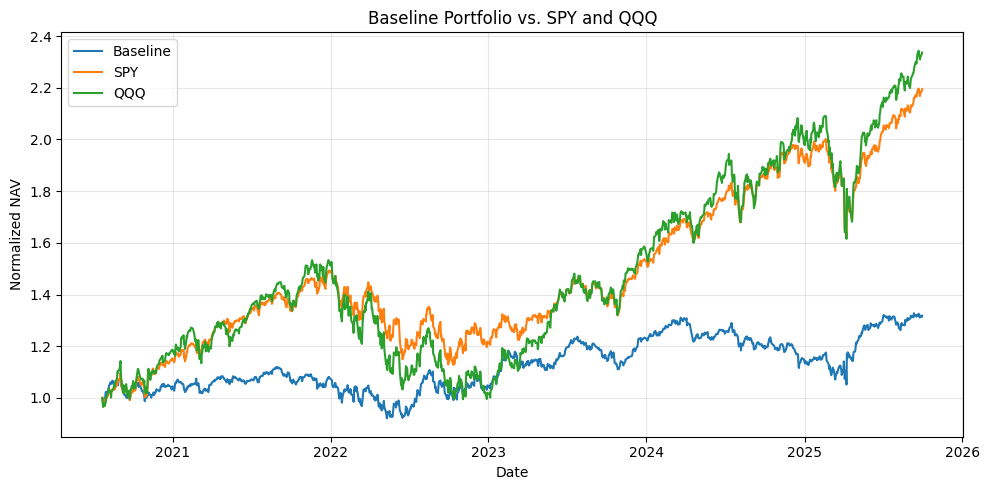

Final NAV:
Baseline    1.3179
SPY         2.1950
QQQ         2.3364
Name: 2025-09-30 00:00:00, dtype: float64


In [ ]:

import matplotlib.pyplot as plt

# Align benchmark prices with the baseline dates
prices = benchmark_prices.reindex(baseline_backtest.index)

if prices.isna().any().any():
    raise ValueError("Missing benchmark prices after date alignment.")

# Normalize NAV to 1
comparison_nav = pd.DataFrame({
    "Baseline": baseline_backtest["nav"],
    "SPY": prices["SPY"] / prices["SPY"].iloc[0],
    "QQQ": prices["QQQ"] / prices["QQQ"].iloc[0]
})

# Save NAV data
comparison_nav.to_csv(baseline_path / "comparison_nav.csv")

# Plot NAV comparison
plt.figure(figsize=(10, 5))

for name in comparison_nav.columns:
    plt.plot(comparison_nav.index, comparison_nav[name], label=name)

plt.title("Baseline Portfolio vs. SPY and QQQ")
plt.xlabel("Date")
plt.ylabel("Normalized NAV")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    baseline_path / "baseline_vs_benchmarks.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Final NAV:")
print(comparison_nav.iloc[-1].round(4))


# Stage C: Baseline Diagnosis

## Model Selection Frequency

I examine how often Random Forest, XGBoost, and LightGBM are selected as the best model across 11 sectors and 21 trading quarters. The best model is selected based on the lowest validation MSE.


In [ ]:

# Count best model selections across sectors
model_names = ["rf", "xgb", "gbm"]
model_counts = []

for sector in sector_ids:
    path = results_path / f"sector{sector}" / "df_best_model_name.csv"
    df = pd.read_csv(path, index_col=0)

    counts = df["model_name"].value_counts().reindex(
        model_names, fill_value=0
    )

    model_counts.append(counts)

model_counts = pd.DataFrame(
    model_counts,
    index=[f"sector{s}" for s in sector_ids]
)

model_counts.columns = ["Random Forest", "XGBoost", "LightGBM"]
model_counts.loc["Total"] = model_counts.sum()

print("Total model selections:", model_counts.loc["Total"].sum())
display(model_counts)

# Overall model selection percentages
model_percent = (
    model_counts.loc["Total"] /
    model_counts.loc["Total"].sum() * 100
)

print("\nOverall model selection percentages:")
display(model_percent.round(2))

model_counts.to_csv(baseline_path / "model_selection_counts.csv")


Total model selections: 231


,Random Forest,XGBoost,LightGBM
sector10,7,10,4
sector15,3,11,7
sector20,9,9,3
sector25,2,11,8
sector30,8,6,7
sector35,7,8,6
sector40,11,4,6
sector45,10,8,3
sector50,5,13,3
sector55,8,4,9



Overall model selection percentages:


,Total
Random Forest,34.63
XGBoost,38.96
LightGBM,26.41



XGBoost was selected most often (38.96%), followed by Random Forest (34.63%) and LightGBM (26.41%). Model selection varies across sectors and quarters, suggesting that no single model consistently achieves the lowest validation MSE.



## Prediction Quality Analysis

I compare the predicted returns with the actual next-quarter returns to evaluate the out-of-sample prediction quality.


In [ ]:
from pathlib import Path
import pandas as pd

data_path = Path("prepared")
results_path = Path("results")
baseline_path = results_path / "baseline"

sector_ids = list(range(10, 61, 5))
final_ratios = pd.read_csv(data_path / "final_ratios.csv")

print("Sectors:", sector_ids)
print("Fundamental data:", final_ratios.shape)
print("Results folder exists:", results_path.is_dir())

In [ ]:

# Collect predictions from all 11 sectors
prediction_tables = []

for sector in sector_ids:
    path = results_path / f"sector{sector}" / "df_predict_best.csv"
    df = pd.read_csv(path, index_col=0)

    df.index = pd.to_datetime(df.index)
    df.index.name = "reportdate"

    long_df = (
    df.stack()
    .rename_axis(["reportdate", "tic"])
    .reset_index(name="predicted_return")
)
    long_df["sector"] = sector
    prediction_tables.append(long_df)

predictions = pd.concat(prediction_tables, ignore_index=True)

# Prepare actual return labels
actual = final_ratios[
    ["tic", "date", "reportdate", "y_return"]
].copy()

actual["date"] = pd.to_datetime(actual["date"])
actual["reportdate"] = pd.to_datetime(actual["reportdate"])

# Check matching keys
print("Total predictions:", len(predictions))
print("Total actual records:", len(actual))

print("\nDuplicate prediction keys:",
      predictions.duplicated(["tic", "reportdate"]).sum())

print("Duplicate actual keys:",
      actual.duplicated(["tic", "reportdate"]).sum())

# Check matching coverage
matched = predictions.merge(
    actual[["tic", "reportdate"]].drop_duplicates(),
    on=["tic", "reportdate"],
    how="left",
    indicator=True
)

print("\nMatched predictions:",
      (matched["_merge"] == "both").sum())

print("Unmatched predictions:",
      (matched["_merge"] == "left_only").sum())

display(predictions.head())


Total predictions: 10328
Total actual records: 19007

Duplicate prediction keys: 0
Duplicate actual keys: 14

Matched predictions: 10328
Unmatched predictions: 0


,reportdate,tic,predicted_return,sector
0,2020-11-05,APA,-0.003269,10
1,2020-11-05,CVX,-0.016687,10
2,2020-11-05,EOG,-0.000886,10
3,2020-11-05,FANG,0.009968,10
4,2020-11-05,HES,-0.017115,10


In [ ]:

# Check duplicate actual return records
keys = ["tic", "reportdate"]

duplicates = actual[
    actual.duplicated(keys, keep=False)
].sort_values(keys + ["date"])

affected = predictions.merge(
    duplicates[keys].drop_duplicates(),
    on=keys,
    how="inner"
)

print("Duplicate actual rows:", len(duplicates))
print("Duplicate actual keys:", duplicates[keys].drop_duplicates().shape[0])
print("Predictions affected:", len(affected))
print("Missing actual returns:", actual["y_return"].isna().sum())

print("\nDuplicate records:")
display(duplicates[["tic", "date", "reportdate", "y_return"]])


Duplicate actual rows: 27
Duplicate actual keys: 13
Predictions affected: 9
Missing actual returns: 0

Duplicate records:


,tic,date,reportdate,y_return
519,ADSK,2024-03-31,2024-06-10,0.201296
520,ADSK,2024-06-30,2024-06-10,0.140253
1074,ALXN,2016-09-30,2017-01-04,0.095303
1075,ALXN,2016-12-31,2017-01-04,-0.288452
2174,BAX,2019-09-30,2020-03-17,0.062964
2175,BAX,2019-12-31,2020-03-17,0.036159
4604,CTLT,2023-06-30,2023-12-08,-0.223393
4605,CTLT,2023-09-30,2023-12-08,0.353757
4875,DAL,2016-12-31,2017-04-12,-0.023395
4876,DAL,2017-03-31,2017-04-12,-0.047868


In [ ]:

# Exclude ambiguous actual return labels
keys = ["tic", "reportdate"]

actual_unique = actual[
    ~actual.duplicated(keys, keep=False)
].copy()

# Match predictions with actual returns
evaluation = predictions.merge(
    actual_unique[keys + ["y_return"]],
    on=keys,
    how="inner",
    validate="one_to_one"
)

# Calculate prediction metrics
y_true = evaluation["y_return"]
y_pred = evaluation["predicted_return"]

mse = ((y_true - y_pred) ** 2).mean()
mae = (y_true - y_pred).abs().mean()
correlation = y_true.corr(y_pred)

prediction_metrics = pd.DataFrame({
    "Metric": ["MSE", "MAE", "Pearson Correlation"],
    "Value": [mse, mae, correlation]
})

print("Total predictions:", len(predictions))
print("Evaluated predictions:", len(evaluation))
print("Excluded predictions:", len(predictions) - len(evaluation))

display(prediction_metrics.round(4))

prediction_metrics.to_csv(
    baseline_path / "prediction_quality_metrics.csv",
    index=False
)


Total predictions: 10328
Evaluated predictions: 10319
Excluded predictions: 9


,Metric,Value
0,MSE,0.0217
1,MAE,0.1110
2,Pearson Correlation,-0.0224



The model shows weak predictive performance. The Pearson correlation between predicted and actual returns is -0.0224, indicating almost no linear relationship. Since the stock selection strategy relies on ranking predicted returns, I also evaluate the rank correlation.


In [ ]:

# Match predictions with actual returns and quarters
evaluation = predictions.merge(
    actual_unique[["tic", "reportdate", "date", "y_return"]],
    on=["tic", "reportdate"],
    how="inner",
    validate="one_to_one"
)

# Calculate Rank IC for each quarter
ic_results = []

for date, group in evaluation.groupby("date"):
    ic = group["predicted_return"].corr(
        group["y_return"], method="spearman"
    )

    ic_results.append({
        "quarter": date,
        "n_stocks": len(group),
        "rank_ic": ic
    })

quarterly_ic = pd.DataFrame(ic_results).set_index("quarter")

print("Overall Spearman correlation:",
      round(evaluation["predicted_return"].corr(
          evaluation["y_return"], method="spearman"
      ), 4))

print("Mean quarterly Rank IC:",
      round(quarterly_ic["rank_ic"].mean(), 4))

print("Positive IC quarters:",
      (quarterly_ic["rank_ic"] > 0).sum(),
      "/", quarterly_ic["rank_ic"].notna().sum())

display(quarterly_ic.round(4))

quarterly_ic.to_csv(
    baseline_path / "quarterly_prediction_ic.csv"
)


Overall Spearman correlation: -0.0223
Mean quarterly Rank IC: 0.0032
Positive IC quarters: 12 / 21


,n_stocks,rank_ic
quarter,,
2020-09-30,493,-0.0284
2020-12-31,491,-0.1478
2021-03-31,472,0.2590
2021-06-30,498,-0.0497
2021-09-30,494,-0.2940
2021-12-31,492,-0.2549
2022-03-31,465,0.0639
2022-06-30,495,0.0558
2022-09-30,494,0.1178



The overall Spearman correlation is -0.0223, and the mean quarterly Rank IC is 0.0032. Only 12 out of 21 quarters have a positive Rank IC. The results suggest that the models have weak and unstable stock-ranking ability, which may contribute to the baseline's underperformance.



## Portfolio Turnover and Transaction Costs

I examine the portfolio's turnover and transaction costs to understand how frequently the baseline changes its holdings.


In [ ]:

# Load saved baseline backtest
backtest = pd.read_csv(
    baseline_path / "baseline_backtest.csv",
    index_col="date",
    parse_dates=True
)

trading_days = backtest.iloc[1:]

turnover = trading_days["turnover"]
cost = trading_days["cost"]

print("Total trading days:", len(trading_days))
print("Days with portfolio changes:", (turnover > 1e-10).sum())
print("Percentage of days with changes:",
      round((turnover > 1e-10).mean() * 100, 2), "%")

print("\nAverage daily turnover:", round(turnover.mean(), 4))
print("Maximum daily turnover:", round(turnover.max(), 4))
print("Total transaction cost:", round(cost.sum(), 4))

print("\nTurnover distribution:")
display(turnover.describe().round(4))

print("\nTop 5 turnover days:")
display(trading_days.nlargest(5, "turnover")[["turnover", "cost"]])


Total trading days: 1304
Days with portfolio changes: 558
Percentage of days with changes: 42.79 %

Average daily turnover: 0.0328
Maximum daily turnover: 2.0
Total transaction cost: 0.0428

Turnover distribution:


,turnover
count,1304.0000
mean,0.0328
std,0.1089
min,0.0000
25%,0.0000
50%,0.0000
75%,0.0317
max,2.0000



Top 5 turnover days:


,turnover,cost
date,,
2020-07-31,2.000000,0.002000
2020-08-04,2.000000,0.002000
2020-08-19,1.333333,0.001333
2020-08-06,1.000000,0.001000
2020-08-18,0.666667,0.000667



The portfolio changes its holdings on 42.79% of trading days, with an average daily turnover of 0.0328. Most daily changes are relatively small, while the largest turnover values occur early in the backtest. The sum of daily transaction costs is 0.0428.


In [ ]:

# Compare portfolio performance with and without transaction costs
gross_nav = (1 + trading_days["gross_ret"]).prod()
net_nav = (1 + trading_days["net_ret"]).prod()

cost_impact = gross_nav - net_nav

print("Final NAV without costs:", round(gross_nav, 4))
print("Final NAV with costs:", round(net_nav, 4))
print("NAV reduction due to costs:", round(cost_impact, 4))
print("Relative NAV reduction:",
      round(cost_impact / gross_nav * 100, 2), "%")


Final NAV without costs: 1.3756
Final NAV with costs: 1.3179
NAV reduction due to costs: 0.0577
Relative NAV reduction: 4.19 %



Without transaction costs, the baseline reaches a final NAV of 1.3756, compared with 1.3179 after costs. Transaction costs reduce final NAV by 4.19% relative to the gross result. However, the baseline still substantially underperforms SPY and QQQ without costs, suggesting that transaction costs are not the main source of underperformance.



## Look-Ahead Bias and Survivorship Bias Audit

I examine whether the baseline uses information that may not have been available at the time of prediction and whether the stock universe reflects historical S&P 500 membership.


In [ ]:

# Check prediction dates against quarter-end dates
date_audit = evaluation.copy()

date_audit["early_signal"] = (
    date_audit["reportdate"] < date_audit["date"]
)

date_audit["days_early"] = (
    date_audit["date"] - date_audit["reportdate"]
).dt.days

early = date_audit[date_audit["early_signal"]]

print("Total evaluated predictions:", len(date_audit))
print("Predictions before quarter end:", len(early))
print("Percentage:",
      round(len(early) / len(date_audit) * 100, 2), "%")

print("\nEarly predictions by quarter:")
display(early.groupby("date").size())

print("\nSample early predictions:")
display(
    early[
        ["tic", "date", "reportdate", "days_early"]
    ].sort_values("days_early", ascending=False).head(10)
)


Total evaluated predictions: 10319
Predictions before quarter end: 1174
Percentage: 11.38 %

Early predictions by quarter:


,0
date,
2020-09-30,49
2020-12-31,48
2021-03-31,52
2021-06-30,80
2021-09-30,74
2021-12-31,49
2022-03-31,55
2022-06-30,82
2022-09-30,65



Sample early predictions:


,tic,date,reportdate,days_early
5124,RVTY,2023-06-30,2023-04-02,89
1426,SNA,2022-09-30,2022-07-21,71
1678,SNA,2023-06-30,2023-04-20,71
4597,DHR,2021-09-30,2021-07-22,70
4872,DHR,2022-06-30,2022-04-21,70
1144,SNA,2021-09-30,2021-07-22,70
1357,SNA,2022-06-30,2022-04-21,70
4436,DHR,2020-09-30,2020-07-23,69
4546,DHR,2021-06-30,2021-04-22,69
1073,SNA,2021-06-30,2021-04-22,69



Among 10,319 evaluated predictions, 1,174 (11.38%) have reporting dates earlier than their corresponding quarter-end dates. These cases appear in all 21 quarters and indicate potential look-ahead bias. The actual availability of the financial information needs further verification.


In [ ]:

import prepare_data

# Load fundamental data before PIT filtering
raw_fund = prepare_data.load_fundamentals(
    "data/fundamental_data_full.csv",
    pd.Timestamp("2015-01-01"),
    pd.Timestamp("2025-09-30")
)

# Apply historical S&P 500 membership filtering
pit_fund = prepare_data.apply_pit_membership(
    raw_fund,
    "data/sp500_historical_constituents.csv"
)

print("\nPIT Membership Audit")
print("Rows before:", len(raw_fund))
print("Rows after:", len(pit_fund))
print("Rows removed:", len(raw_fund) - len(pit_fund))

print("\nTickers before:", raw_fund["tic"].nunique())
print("Tickers after:", pit_fund["tic"].nunique())

removed_tickers = set(raw_fund["tic"]) - set(pit_fund["tic"])
print("Tickers completely removed:", len(removed_tickers))

print("\nPrepared data matches PIT row count:",
      len(pit_fund) == len(final_ratios))


Reading fundamentals: data/fundamental_data_full.csv
  raw: 22,909 rows x 64 columns
  43 rows had no filing date -> quarter end + 45 days
  dropped 1,591 rows with no y_return label
  after 2015-01-01..2025-09-30: 21,299 rows
Applying point-in-time S&P 500 membership: data/sp500_historical_constituents.csv
  kept 19,007 of 21,299 rows (674 tickers, 692 before)

PIT Membership Audit
Rows before: 21299
Rows after: 19007
Rows removed: 2292

Tickers before: 692
Tickers after: 674
Tickers completely removed: 18

Prepared data matches PIT row count: True



Point-in-time S&P 500 membership filtering reduced the sample from 21,299 to 19,007 observations, removing 2,292 rows (10.76%) and 18 tickers entirely. The filtered dataset matches the prepared data. However, historical membership at the signal date still needs to be verified.


## Baseline Diagnosis Summary

The baseline achieves a final NAV of 1.3179, compared with 2.1950 for SPY and 2.3364 for QQQ. The analysis identifies several possible reasons for its underperformance.

- **Prediction quality:** The mean quarterly Rank IC is only 0.0032, suggesting weak and unstable stock-ranking ability.
- **Transaction costs:** Costs reduce the final NAV from 1.3756 to 1.3179, but they do not explain most of the underperformance.
- **Data availability:** 67 selected stocks have no price data, accounting for an average of 10.79% of portfolio weight.
- **Look-ahead bias:** 11.38% of predictions have reporting dates earlier than their assigned quarter-end dates, indicating a potential timing issue.
- **Survivorship bias:** Historical membership filtering removes 2,292 observations and 18 tickers entirely, but 0.66% of selections on trading days do not satisfy same-day S&P 500 membership.
- **Backtest methodology:** The baseline uses intraday returns, while SPY and QQQ use adjusted close-to-close returns, making the comparison imperfect.

These findings suggest that the next stage should focus on improving data alignment, backtest reliability, and stock selection rules before considering more complex models.


# Stage D–E: Strategy Development and Evaluation
## Research Hypothesis

The baseline has weak stock-ranking ability and substantially underperforms SPY and QQQ.

I first address the data alignment and backtest limitations identified in Stage C to establish a more reliable evaluation framework.

My initial hypothesis is that selecting the top 10% of stocks instead of the top 25% may improve portfolio performance by concentrating on stronger predicted returns.

I will first correct the data timing issues and retrain the models. I will then test each strategy modification separately to isolate its effect. I will compare strategies using returns, Sharpe ratio, maximum drawdown, and turnover.



## Initial Strategy Experiments

I test three modifications to the baseline strategy:

1. **Top 10% Selection:** Select the top 10% of stocks by predicted return instead of the top 25%, while keeping equal weights.
2. **Trend Confirmation:** Keep the top 25% selection rule but require the previous closing price to be above its 60-day moving average.
3. **Inverse Volatility Weighting:** Keep the top 25% selection rule and allocate weights inversely proportional to historical volatility.

I will first test each modification separately against a common baseline. All strategies will use the same data availability rules, backtest period, transaction costs, and execution assumptions.

I will evaluate cumulative return, CAGR, Sharpe ratio, maximum drawdown, and turnover.



## Experimental Design and Data Splitting

I use three periods for strategy evaluation:

- Development: 2020-10-02 to 2023-12-31
- Validation: 2024-01-01 to 2024-12-31
- Final Test: 2025-01-01 to 2025-09-30

The first prediction quarter is 2020-09-30, while actual trading begins on 2020-10-02.

I use development and validation results to explore and select strategies. After selecting S9, I keep its rules fixed and evaluate performance through September 2025.

The validation period was used repeatedly, and the baseline's 2025 results were previously observed. Therefore, the final test is not a completely untouched blind evaluation.


In [ ]:

# Define strategy evaluation periods
periods = pd.DataFrame({
    "period": ["Development", "Validation", "Final Test"],
    "start": ["2020-10-02", "2024-01-01", "2025-01-01"],
    "end": ["2023-12-31", "2024-12-31", "2025-09-30"]
})

# Load available trading dates
trading_dates = pd.to_datetime(
    pd.read_csv(
        data_path / "daily.csv",
        usecols=["datadate"]
    )["datadate"].unique()
)

trading_dates = pd.DatetimeIndex(trading_dates).sort_values()

# Check data coverage
for i, row in periods.iterrows():
    dates = trading_dates[
        (trading_dates >= row["start"]) &
        (trading_dates <= row["end"])
    ]

    periods.loc[i, "trading_days"] = len(dates)
    periods.loc[i, "first_trading_day"] = dates.min()
    periods.loc[i, "last_trading_day"] = dates.max()

periods["trading_days"] = periods["trading_days"].astype(int)

display(periods)

# Save experiment configuration
strategy_path = results_path / "strategy"
strategy_path.mkdir(parents=True, exist_ok=True)

periods.to_csv(
    strategy_path / "experiment_periods.csv",
    index=False
)


,period,start,end,trading_days,first_trading_day,last_trading_day
0,Development,2020-09-30,2023-12-31,818,2020-09-30,2023-12-29
1,Validation,2024-01-01,2024-12-31,252,2024-01-02,2024-12-31
2,Final Test,2025-01-01,2025-09-30,186,2025-01-02,2025-09-30



## Point-in-Time Data Alignment

I construct a conservative information availability timeline for the corrected strategy. Financial features are treated as available no earlier than both the reporting date and the assigned quarter-end date. Return labels are available only after their corresponding future trade prices are observed.


In [ ]:

# Build point-in-time feature and label availability dates

raw_label_dates = pd.read_csv(
    "data/fundamental_data_full.csv",
    usecols=["ticker", "datadate", "actual_tradedate"]
).rename(columns={
    "ticker": "tic",
    "datadate": "date"
})

raw_label_dates["date"] = pd.to_datetime(
    raw_label_dates["date"]
)

raw_label_dates["actual_tradedate"] = pd.to_datetime(
    raw_label_dates["actual_tradedate"],
    errors="coerce"
)

raw_label_dates = raw_label_dates.sort_values(
    ["tic", "date"]
).reset_index(drop=True)

assert not raw_label_dates.duplicated(
    ["tic", "date"]
).any()

# The next observation's trading date is when
# the current observation's forward-return label is known
raw_label_dates["label_available_date"] = (
    raw_label_dates.groupby("tic")["actual_tradedate"]
    .shift(-1)
)

pit_timing = final_ratios[
    ["tic", "date", "reportdate"]
].copy()

pit_timing["date"] = pd.to_datetime(pit_timing["date"])
pit_timing["reportdate"] = pd.to_datetime(
    pit_timing["reportdate"]
)

pit_timing = pit_timing.merge(
    raw_label_dates[
        ["tic", "date", "label_available_date"]
    ],
    on=["tic", "date"],
    how="left",
    validate="one_to_one"
)

pit_timing["feature_available_date"] = pit_timing[
    ["date", "reportdate"]
].max(axis=1)

assert not pit_timing.duplicated(
    ["tic", "date"]
).any()

assert pit_timing[
    ["feature_available_date", "label_available_date"]
].notna().all().all()

assert len(pit_timing) == len(final_ratios)

strategy_path = results_path / "strategy"
strategy_path.mkdir(parents=True, exist_ok=True)

pit_timing.to_csv(
    strategy_path / "pit_timing.csv",
    index=False
)

print("Total records:", len(pit_timing))
print(
    "Early report dates adjusted:",
    (pit_timing["reportdate"] < pit_timing["date"]).sum()
)

display(
    pit_timing[
        (pit_timing["tic"] == "DHR") &
        (pit_timing["date"] == "2020-09-30")
    ]
)


Total records: 19007
Missing dates: 0
Early reporting dates adjusted: 2194


,tic,date,reportdate,label_available_date,feature_available_date
5172,DHR,2020-09-30,2020-07-23,2021-03-01,2020-09-30



## Corrected Model Input

I prepare the corrected model dataset by excluding the quarterly adjusted closing price from the features. I also retain feature and label availability dates to control information timing during rolling training and validation.


In [ ]:

# Prepare corrected model data
pit_model_data = final_ratios.copy()

pit_model_data["date"] = pd.to_datetime(pit_model_data["date"])
pit_model_data["reportdate"] = pd.to_datetime(pit_model_data["reportdate"])

pit_model_data = pit_model_data.merge(
    pit_timing[
        ["tic", "date", "feature_available_date", "label_available_date"]
    ],
    on=["tic", "date"],
    how="left",
    validate="one_to_one"
)

# Remove the quarterly price feature
pit_model_data = pit_model_data.drop(columns=["adj_close_q"])

# Select financial features only
feature_cols = [
    col for col in pit_model_data.columns
    if pd.api.types.is_numeric_dtype(pit_model_data[col])
    and col not in ["gsector", "y_return"]
]

# Check data integrity
assert len(feature_cols) == 52
assert pit_model_data[
    ["feature_available_date", "label_available_date"]
].notna().all().all()

# Save corrected model input
pit_data_path = Path("prepared_pit")
pit_data_path.mkdir(exist_ok=True)

pit_model_data.to_csv(
    pit_data_path / "pit_model_data.csv",
    index=False
)

print("Dataset shape:", pit_model_data.shape)
print("Number of model features:", len(feature_cols))
print("Number of sectors:", pit_model_data["gsector"].nunique())
print("Missing availability dates:",
      pit_model_data[
          ["feature_available_date", "label_available_date"]
      ].isna().sum().sum())

print("Saved to:", pit_data_path / "pit_model_data.csv")


Dataset shape: (19007, 60)
Number of model features: 52
Number of sectors: 11
Missing availability dates: 0
Saved to: prepared_pit/pit_model_data.csv



## Point-in-Time Rolling Training and Validation

I use an expanding training window and a four-quarter validation window. Only observations with available features and realized return labels are used for model training and validation.


In [ ]:

def prepare_pit_split(df, quarter, decision_date, validation_window=4):
    dates = sorted(df["date"].unique())
    i = dates.index(pd.Timestamp(quarter))

    val_start = dates[i - validation_window]

    known = (
        (df["feature_available_date"] < decision_date) &
        (df["label_available_date"] < decision_date)
    )

    train = df[
        (df["date"] < val_start) & known
    ].copy()

    validation = df[
        (df["date"] >= val_start) &
        (df["date"] < quarter) & known
    ].copy()

    prediction = df[
        (df["date"] == quarter) &
        (df["feature_available_date"] < decision_date)
    ].copy()

    return train, validation, prediction


# Test the first prediction quarter for Sector 35
sector35 = pit_model_data[
    pit_model_data["gsector"] == 35
].copy()

quarter = pd.Timestamp("2020-09-30")
decision_date = pd.Timestamp("2020-10-01")

train, validation, prediction = prepare_pit_split(
    sector35, quarter, decision_date
)

print("Training observations:", len(train))
print("Validation observations:", len(validation))
print("Available prediction observations:", len(prediction))

print("\nTraining date range:",
      train["date"].min(), "to", train["date"].max())

print("Validation date range:",
      validation["date"].min(), "to", validation["date"].max())

print("\nLatest training label availability:",
      train["label_available_date"].max())

print("Latest validation label availability:",
      validation["label_available_date"].max())

print("Decision date:", decision_date)

Training observations: 868
Validation observations: 177
Available prediction observations: 6

Training date range: 2015-06-30 00:00:00 to 2019-06-30 00:00:00
Validation date range: 2019-09-30 00:00:00 to 2020-03-31 00:00:00

Latest training label availability: 2019-12-02 00:00:00
Latest validation label availability: 2020-09-01 00:00:00
Decision date: 2020-10-01 00:00:00



## Corrected Rolling Model Training

I retrain Random Forest, XGBoost, and LightGBM at the beginning of each quarter using only available training and validation labels. I select the model with the lowest validation MSE and generate predictions as financial information becomes available.


In [ ]:

import time
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

def make_pit_models():
    return {
        "rf": RandomForestRegressor(
            n_estimators=150,
            max_features="sqrt",
            min_samples_leaf=5,
            n_jobs=2,
            random_state=42
        ),
        "xgb": XGBRegressor(
            n_estimators=150,
            max_depth=3,
            learning_rate=0.05,
            n_jobs=2,
            random_state=42,
            tree_method="hist"
        ),
        "gbm": LGBMRegressor(
            n_estimators=150,
            learning_rate=0.05,
            num_leaves=15,
            n_jobs=2,
            random_state=42,
            verbose=-1
        )
    }


def run_pit_sector(sector):
    df = pit_model_data[
        pit_model_data["gsector"] == sector
    ].copy()

    sector_quarters = sorted(
        df.loc[
            df["date"] >= pd.Timestamp("2020-09-30"),
            "date"
        ].unique()
    )

    all_predictions = []
    all_scores = []

    for quarter in sector_quarters:
        quarter = pd.Timestamp(quarter)
        decision_date = quarter + pd.Timedelta(days=1)
        start_time = time.perf_counter()

        train, val, _ = prepare_pit_split(
            df, quarter, decision_date
        )

        if train.empty or val.empty:
            raise ValueError(
                f"sector{sector}: insufficient data for {quarter.date()}"
            )

        # Verify information availability
        for sample in [train, val]:
            assert (sample["feature_available_date"] < decision_date).all()
            assert (sample["label_available_date"] < decision_date).all()

        models = make_pit_models()
        scores = {}

        for name, model in models.items():
            model.fit(train[feature_cols], train["y_return"])

            val_pred = model.predict(val[feature_cols])
            scores[name] = mean_squared_error(
                val["y_return"], val_pred
            )

        best_name = min(scores, key=scores.get)

        # Predict the entire quarter using the model
        # fitted at the beginning of the quarter
        pred = df[df["date"] == quarter].copy()

        pred["predicted_return"] = models[best_name].predict(
            pred[feature_cols]
        )

        pred["model_name"] = best_name

        pred["signal_ready_date"] = pred[
            "feature_available_date"
        ].where(
            pred["feature_available_date"] > decision_date,
            decision_date
        )

        # Earliest execution is the next market trading day
        trade_idx = trading_dates.searchsorted(
            pred["signal_ready_date"], side="right"
        )

        pred["execution_date"] = pd.NaT
        valid = trade_idx < len(trading_dates)

        pred.loc[valid, "execution_date"] = (
            trading_dates[trade_idx[valid]].to_numpy()
        )

        all_predictions.append(
            pred[[
                "tic", "date", "reportdate",
                "feature_available_date",
                "signal_ready_date",
                "execution_date",
                "predicted_return", "model_name"
            ]]
        )

        all_scores.append({
            "quarter": quarter,
            "rf_mse": scores["rf"],
            "xgb_mse": scores["xgb"],
            "gbm_mse": scores["gbm"],
            "best_model": best_name,
            "train_size": len(train),
            "validation_size": len(val)
        })

        elapsed = time.perf_counter() - start_time

        print(
            f"sector{sector} | {quarter.date()} | "
            f"{best_name} | {elapsed:.1f}s",
            flush=True
        )

    predictions = pd.concat(
        all_predictions, ignore_index=True
    )

    model_scores = pd.DataFrame(all_scores)

    output_dir = strategy_path / f"sector{sector}"
    output_dir.mkdir(parents=True, exist_ok=True)

    predictions.to_csv(
        output_dir / "predictions.csv", index=False
    )

    model_scores.to_csv(
        output_dir / "model_scores.csv", index=False
    )

    return predictions, model_scores


# Run Sector 35
start_time = time.perf_counter()

pit_predictions_35, pit_scores_35 = run_pit_sector(35)

print("\nTotal quarters:", len(pit_scores_35))
print("Total predictions:", len(pit_predictions_35))
print(
    "Predictions with execution dates:",
    pit_predictions_35["execution_date"].notna().sum()
)
print(
    "Total time (minutes):",
    round((time.perf_counter() - start_time) / 60, 2)
)

print("\nBest model counts:")
print(pit_scores_35["best_model"].value_counts())


sector35 | 2020-09-30 | rf | 1.1s
sector35 | 2020-12-31 | rf | 1.1s
sector35 | 2021-03-31 | rf | 1.1s
sector35 | 2021-06-30 | rf | 1.1s
sector35 | 2021-09-30 | rf | 1.2s
sector35 | 2021-12-31 | rf | 1.2s
sector35 | 2022-03-31 | xgb | 1.3s
sector35 | 2022-06-30 | xgb | 1.3s
sector35 | 2022-09-30 | xgb | 1.3s
sector35 | 2022-12-31 | rf | 1.5s
sector35 | 2023-03-31 | rf | 1.6s
sector35 | 2023-06-30 | rf | 1.6s
sector35 | 2023-09-30 | rf | 1.6s
sector35 | 2023-12-31 | rf | 1.7s
sector35 | 2024-03-31 | rf | 1.8s
sector35 | 2024-06-30 | rf | 1.9s
sector35 | 2024-09-30 | xgb | 1.9s
sector35 | 2024-12-31 | rf | 2.0s
sector35 | 2025-03-31 | rf | 2.0s
sector35 | 2025-06-30 | xgb | 2.1s
sector35 | 2025-09-30 | rf | 2.2s

Total quarters: 21
Total predictions: 1311
Predictions with execution dates: 1251
Total time (minutes): 0.55

Best model counts:
best_model
rf     16
xgb     5
Name: count, dtype: int64


In [ ]:

# Train the remaining sectors
def pit_sector_complete(sector):
    folder = strategy_path / f"sector{sector}"
    pred_file = folder / "predictions.csv"
    score_file = folder / "model_scores.csv"

    if not pred_file.is_file() or not score_file.is_file():
        return False

    try:
        pred = pd.read_csv(pred_file)
        scores = pd.read_csv(score_file)

        return (
            len(scores) == 21
            and scores["quarter"].nunique() == 21
            and scores[["rf_mse", "xgb_mse", "gbm_mse"]].notna().all().all()
            and not pred.empty
            and pred["predicted_return"].notna().all()
            and not pred.duplicated(["tic", "date"]).any()
        )
    except Exception:
        return False


for sector in sector_ids:
    if pit_sector_complete(sector):
        print(f"sector{sector}: already completed, skipping.")
        continue

    print(f"\nRunning sector{sector}...", flush=True)

    run_pit_sector(sector)

    if not pit_sector_complete(sector):
        raise RuntimeError(f"sector{sector}: incomplete results.")

    print(f"sector{sector}: completed successfully.", flush=True)

print("\nAll 11 corrected sectors completed successfully!")



Running sector10...
sector10 | 2020-09-30 | rf | 0.6s
sector10 | 2020-12-31 | rf | 0.7s
sector10 | 2021-03-31 | rf | 0.7s
sector10 | 2021-06-30 | xgb | 0.7s
sector10 | 2021-09-30 | gbm | 0.7s
sector10 | 2021-12-31 | rf | 0.7s
sector10 | 2022-03-31 | rf | 0.8s
sector10 | 2022-06-30 | rf | 0.8s
sector10 | 2022-09-30 | xgb | 0.8s
sector10 | 2022-12-31 | gbm | 0.8s
sector10 | 2023-03-31 | xgb | 0.8s
sector10 | 2023-06-30 | xgb | 0.8s
sector10 | 2023-09-30 | rf | 0.9s
sector10 | 2023-12-31 | rf | 0.9s
sector10 | 2024-03-31 | rf | 0.9s
sector10 | 2024-06-30 | rf | 0.9s
sector10 | 2024-09-30 | xgb | 0.9s
sector10 | 2024-12-31 | rf | 1.0s
sector10 | 2025-03-31 | rf | 1.0s
sector10 | 2025-06-30 | rf | 1.0s
sector10 | 2025-09-30 | xgb | 1.0s
sector10: completed successfully.

Running sector15...
sector15 | 2020-09-30 | rf | 0.5s
sector15 | 2020-12-31 | rf | 0.5s
sector15 | 2021-03-31 | xgb | 0.5s
sector15 | 2021-06-30 | rf | 0.5s
sector15 | 2021-09-30 | rf | 0.5s
sector15 | 2021-12-31 | rf | 0.

In [ ]:

# Combine and filter corrected predictions
all_predictions = []

for sector in sector_ids:
    path = strategy_path / f"sector{sector}" / "predictions.csv"

    df = pd.read_csv(
        path,
        parse_dates=[
            "date", "feature_available_date",
            "signal_ready_date", "execution_date"
        ]
    )

    df["sector"] = sector
    all_predictions.append(df)

all_predictions = pd.concat(
    all_predictions, ignore_index=True
)

# Signals expire at the end of the following quarter
all_predictions["expiry_date"] = (
    all_predictions["date"] + pd.offsets.QuarterEnd(1)
)

valid_signals = (
    all_predictions["execution_date"].notna()
    & (all_predictions["execution_date"] > all_predictions["signal_ready_date"])
    & (all_predictions["execution_date"] <= all_predictions["expiry_date"])
)

eligible_predictions = all_predictions.loc[
    valid_signals
].copy()

# Save eligible predictions
output_file = strategy_path / "eligible_predictions.csv"
eligible_predictions.to_csv(output_file, index=False)

print("Total predictions:", len(all_predictions))
print("Eligible predictions:", len(eligible_predictions))
print("Excluded predictions:",
      len(all_predictions) - len(eligible_predictions))

print("\nUnique stocks:",
      eligible_predictions["tic"].nunique())

print("Execution date range:",
      eligible_predictions["execution_date"].min(),
      "to",
      eligible_predictions["execution_date"].max())

print("Duplicate ticker-quarter pairs:",
      eligible_predictions.duplicated(["tic", "date"]).sum())

display(eligible_predictions.head())


Total predictions: 10338
Eligible predictions: 9820
Excluded predictions: 518

Unique stocks: 588
Execution date range: 2020-10-02 00:00:00 to 2025-08-29 00:00:00
Duplicate ticker-quarter pairs: 0


,tic,date,reportdate,feature_available_date,signal_ready_date,execution_date,predicted_return,model_name,sector,expiry_date
0,APA,2020-09-30,2020-11-05,2020-11-05,2020-11-05,2020-11-06,-0.002255,rf,10,2020-12-31
1,BKR,2020-09-30,2020-10-23,2020-10-23,2020-10-23,2020-10-26,0.011384,rf,10,2020-12-31
2,COG,2020-09-30,2020-10-30,2020-10-30,2020-10-30,2020-11-02,-0.017206,rf,10,2020-12-31
3,COP,2020-09-30,2020-11-03,2020-11-03,2020-11-03,2020-11-04,0.020238,rf,10,2020-12-31
4,CVX,2020-09-30,2020-11-05,2020-11-05,2020-11-05,2020-11-06,0.021279,rf,10,2020-12-31



## Trading Eligibility Audit

I check S&P 500 membership at each signal's execution date rather than the financial quarter-end date. I also require valid adjusted opening and closing prices. Only signals passing both checks are eligible for portfolio construction.


In [ ]:

# Check point-in-time membership at execution
members = pd.read_csv(
    "data/sp500_historical_constituents.csv",
    usecols=["date", "tickers"],
    parse_dates=["date"]
).sort_values("date").drop_duplicates("date")

member_dates = members["date"].to_numpy()

member_sets = [
    set(t.strip() for t in str(value).split(",") if t.strip())
    for value in members["tickers"]
]

audit_predictions = eligible_predictions.copy()

member_idx = np.searchsorted(
    member_dates,
    audit_predictions["execution_date"].to_numpy(),
    side="right"
) - 1

audit_predictions["member_at_execution"] = [
    i >= 0 and tic in member_sets[i]
    for i, tic in zip(member_idx, audit_predictions["tic"])
]

# Check valid prices on execution dates
prices = pd.read_csv(
    data_path / "daily.csv",
    usecols=["tic", "datadate", "open_adj", "close_adj"],
    parse_dates=["datadate"]
)

valid_prices = prices[
    (prices["open_adj"] > 0) &
    (prices["close_adj"] > 0) &
    np.isfinite(prices["open_adj"]) &
    np.isfinite(prices["close_adj"])
].copy()

price_index = pd.MultiIndex.from_frame(
    valid_prices[
        ["tic", "datadate"]
    ].rename(columns={"datadate": "execution_date"})
    .drop_duplicates()
)

prediction_index = pd.MultiIndex.from_frame(
    audit_predictions[["tic", "execution_date"]]
)

audit_predictions["has_execution_price"] = (
    prediction_index.isin(price_index)
)

# Retain signals that satisfy both requirements
tradable_predictions = audit_predictions[
    audit_predictions["member_at_execution"] &
    audit_predictions["has_execution_price"]
].copy()

audit_predictions.to_csv(
    strategy_path / "trading_eligibility_audit.csv",
    index=False
)

tradable_predictions.to_csv(
    strategy_path / "tradable_predictions.csv",
    index=False
)

print("Previously eligible predictions:", len(audit_predictions))
print("S&P 500 members at execution:",
      audit_predictions["member_at_execution"].sum())
print("Valid execution prices:",
      audit_predictions["has_execution_price"].sum())
print("Tradable predictions:", len(tradable_predictions))
print("Excluded at this stage:",
      len(audit_predictions) - len(tradable_predictions))
print("Unique tradable stocks:",
      tradable_predictions["tic"].nunique())

print("\nSignals failing both checks:",
      (
          ~audit_predictions["member_at_execution"] &
          ~audit_predictions["has_execution_price"]
      ).sum())


Previously eligible predictions: 9820
S&P 500 members at execution: 9812
Valid execution prices: 8912
Tradable predictions: 8912
Excluded at this stage: 908
Unique tradable stocks: 493

Signals failing both checks: 8


In [ ]:

# Diagnose missing execution prices
missing = audit_predictions[
    ~audit_predictions["has_execution_price"]
].copy()

price_tickers = set(prices["tic"].dropna())

price_pairs = pd.MultiIndex.from_frame(
    prices[["tic", "datadate"]].drop_duplicates()
)

missing_pairs = pd.MultiIndex.from_frame(
    missing[["tic", "execution_date"]].rename(
        columns={"execution_date": "datadate"}
    )
)

ticker_exists = missing["tic"].isin(price_tickers)
date_exists = missing_pairs.isin(price_pairs)

missing["reason"] = np.where(
    ~ticker_exists,
    "Ticker absent from daily.csv",
    np.where(
        ~date_exists,
        "Execution-day record absent",
        "Invalid execution prices"
    )
)

print("Missing-price predictions:", len(missing))
print("Affected tickers:", missing["tic"].nunique())
print("Tickers completely excluded:",
      len(set(eligible_predictions["tic"]) -
          set(tradable_predictions["tic"])))

print("\nMissing-price reasons:")
display(missing["reason"].value_counts().to_frame("count"))

print("\nMost affected tickers:")
display(
    missing.groupby(["tic", "reason"])
    .size()
    .sort_values(ascending=False)
    .head(15)
    .to_frame("missing_predictions")
)

print("\nDuplicate ticker-date rows in daily.csv:",
      prices.duplicated(["tic", "datadate"]).sum())


Missing-price predictions: 908
Affected tickers: 95
Tickers completely excluded: 95

Missing-price reasons:


,count
reason,
Ticker absent from daily.csv,908



Most affected tickers:


,,missing_predictions
tic,reason,
BF.B,Ticker absent from daily.csv,20
BRK.B,Ticker absent from daily.csv,20
CE,Ticker absent from daily.csv,19
WBA,Ticker absent from daily.csv,19
MKTX,Ticker absent from daily.csv,19
ANSS,Ticker absent from daily.csv,18
BWA,Ticker absent from daily.csv,18
FMC,Ticker absent from daily.csv,18
JNPR,Ticker absent from daily.csv,18



Duplicate ticker-date rows in daily.csv: 0


In [ ]:

# Audit missing tickers against the original SQLite price database
import sqlite3

with sqlite3.connect("data/finrl_trading.db") as conn:
    raw_tickers = set(
        pd.read_sql_query(
            "SELECT DISTINCT ticker FROM price_data", conn
        )["ticker"].dropna().astype(str)
    )

def normalize_ticker(ticker):
    return (
        ticker.upper()
        .replace(".", "")
        .replace("-", "")
        .replace("/", "")
        .replace(" ", "")
    )

normalized_raw = {}

for ticker in raw_tickers:
    key = normalize_ticker(ticker)
    normalized_raw.setdefault(key, []).append(ticker)

ticker_audit = pd.DataFrame({
    "tic": sorted(missing["tic"].unique())
})

ticker_audit["raw_exact_match"] = ticker_audit["tic"].isin(
    raw_tickers
)

ticker_audit["possible_alias"] = ticker_audit["tic"].apply(
    lambda tic: ", ".join(
        t for t in normalized_raw.get(normalize_ticker(tic), [])
        if t != tic
    )
)

ticker_audit["status"] = np.select(
    [
        ticker_audit["raw_exact_match"],
        ticker_audit["possible_alias"].ne("")
    ],
    [
        "Exact match in raw database",
        "Possible ticker-format mismatch"
    ],
    default="Absent from raw price database"
)

ticker_audit["affected_predictions"] = (
    ticker_audit["tic"]
    .map(missing["tic"].value_counts())
)

print("Tickers in original price database:", len(raw_tickers))
print("Tickers in exported daily.csv:", prices["tic"].nunique())

print("\nMissing ticker categories:")
display(
    ticker_audit.groupby("status").agg(
        tickers=("tic", "size"),
        affected_predictions=("affected_predictions", "sum")
    )
)

print("\nPossible ticker aliases:")
display(
    ticker_audit[
        ticker_audit["possible_alias"] != ""
    ]
)

ticker_audit.to_csv(
    strategy_path / "missing_ticker_audit.csv",
    index=False
)


Tickers in original price database: 506
Tickers in exported daily.csv: 501

Missing ticker categories:


,tickers,affected_predictions
status,,
Absent from raw price database,93,868
Possible ticker-format mismatch,2,40



Possible ticker aliases:


,tic,raw_exact_match,possible_alias,status,affected_predictions
12,BF.B,False,BF-B,Possible ticker-format mismatch,20
15,BRK.B,False,BRK-B,Possible ticker-format mismatch,20



## Ticker Alias Recovery

I identified two ticker-format mismatches between the fundamental and price datasets: BF.B/BF-B and BRK.B/BRK-B. I recover their historical prices from the original SQLite database using the same price-adjustment method as the provided preprocessing script. I keep the original daily price file unchanged.


In [ ]:

# Recover prices for verified ticker-format aliases
alias_map = {"BF-B": "BF.B", "BRK-B": "BRK.B"}

start_date = prices["datadate"].min().strftime("%Y-%m-%d")
end_date = prices["datadate"].max().strftime("%Y-%m-%d")

with sqlite3.connect("data/finrl_trading.db") as conn:
    alias_raw = pd.read_sql_query(
        """
        SELECT ticker, date, open, high, low, close, adj_close, volume
        FROM price_data
        WHERE ticker IN (?, ?)
          AND date BETWEEN ? AND ?
        """,
        conn,
        params=("BF-B", "BRK-B", start_date, end_date)
    )

alias_raw["tic"] = alias_raw["ticker"].map(alias_map)
alias_raw["date"] = pd.to_datetime(alias_raw["date"])

for col in ["open", "close", "adj_close"]:
    alias_raw[col] = pd.to_numeric(alias_raw[col], errors="coerce")

alias_raw = alias_raw[
    (alias_raw["open"] > 0) &
    (alias_raw["close"] > 0) &
    (alias_raw["adj_close"] > 0)
].copy()

# Match the price adjustments in prepare_data.py
alias_raw["ajexdi"] = alias_raw["close"] / alias_raw["adj_close"]
alias_raw["open_adj"] = alias_raw["open"] / alias_raw["ajexdi"]
alias_raw["close_adj"] = alias_raw["adj_close"]

alias_prices = alias_raw.rename(columns={
    "date": "datadate",
    "open": "prcod",
    "close": "prccd",
    "high": "prchd",
    "low": "prcld"
})

alias_prices = alias_prices[
    ["tic", "datadate", "prcod", "prccd", "prchd",
     "prcld", "ajexdi", "adj_close", "volume",
     "open_adj", "close_adj"]
].sort_values(["tic", "datadate"])

assert not alias_prices.duplicated(["tic", "datadate"]).any()

# Check how many previously missing signals are recovered
alias_signals = missing[
    missing["tic"].isin(alias_map.values())
].copy()

signal_pairs = pd.MultiIndex.from_frame(
    alias_signals[["tic", "execution_date"]].rename(
        columns={"execution_date": "datadate"}
    )
)

price_pairs = pd.MultiIndex.from_frame(
    alias_prices[["tic", "datadate"]]
)

recovered = signal_pairs.isin(price_pairs)

alias_prices.to_csv(
    strategy_path / "alias_prices.csv", index=False
)

print("Recovered price rows:", len(alias_prices))
print("Recovered tickers:", alias_prices["tic"].nunique())
print("Previously missing alias signals:", len(alias_signals))
print("Signals with valid recovered prices:", recovered.sum())
print("Alias signals still missing prices:", (~recovered).sum())

display(
    alias_prices.groupby("tic").agg(
        price_days=("datadate", "size"),
        first_date=("datadate", "min"),
        last_date=("datadate", "max")
    )
)


Recovered price rows: 5180
Recovered tickers: 2
Previously missing alias signals: 40
Signals with valid recovered prices: 40
Alias signals still missing prices: 0


,price_days,first_date,last_date
tic,,,
BF.B,2590,2015-06-15,2025-09-30
BRK.B,2590,2015-06-15,2025-09-30



## Corrected Price Coverage

I combine the original daily prices with the recovered ticker-alias prices. I then repeat the execution-price and historical index-membership checks. Stocks without available price data remain excluded, and I document this coverage limitation.


In [ ]:

# Combine original and recovered daily prices
price_cols = ["tic", "datadate", "open_adj", "close_adj"]

base_daily = pd.read_csv(
    data_path / "daily.csv",
    usecols=price_cols,
    parse_dates=["datadate"]
)

recovered_daily = pd.read_csv(
    strategy_path / "alias_prices.csv",
    usecols=price_cols,
    parse_dates=["datadate"]
)

corrected_daily = pd.concat(
    [base_daily, recovered_daily],
    ignore_index=True
)

assert not corrected_daily.duplicated(
    ["tic", "datadate"]
).any()

# Identify valid trading prices
valid_price_rows = (
    (corrected_daily["open_adj"] > 0) &
    (corrected_daily["close_adj"] > 0) &
    np.isfinite(corrected_daily["open_adj"]) &
    np.isfinite(corrected_daily["close_adj"])
)

valid_price_index = pd.MultiIndex.from_frame(
    corrected_daily.loc[
        valid_price_rows, ["tic", "datadate"]
    ].rename(columns={"datadate": "execution_date"})
)

# Repeat trading eligibility checks
updated_audit = audit_predictions.copy()

prediction_index = pd.MultiIndex.from_frame(
    updated_audit[["tic", "execution_date"]]
)

updated_audit["has_execution_price"] = (
    prediction_index.isin(valid_price_index)
)

tradable_predictions = updated_audit[
    updated_audit["member_at_execution"] &
    updated_audit["has_execution_price"]
].copy()

# Update strategy files
updated_audit.to_csv(
    strategy_path / "trading_eligibility_audit.csv",
    index=False
)

tradable_predictions.to_csv(
    strategy_path / "tradable_predictions.csv",
    index=False
)

print("Daily price rows:", len(corrected_daily))
print("Price-covered stocks:", corrected_daily["tic"].nunique())
print("Tradable predictions:", len(tradable_predictions))
print("Unique tradable stocks:", tradable_predictions["tic"].nunique())

print("\nRecovered alias signals passing all checks:",
      tradable_predictions["tic"].isin(["BF.B", "BRK.B"]).sum())

print("Predictions still excluded:",
      len(updated_audit) - len(tradable_predictions))

print("Duplicate tradable predictions:",
      tradable_predictions.duplicated(["tic", "date"]).sum())


Daily price rows: 1266505
Price-covered stocks: 503
Tradable predictions: 8952
Unique tradable stocks: 495

Recovered alias signals passing all checks: 40
Predictions still excluded: 868
Duplicate tradable predictions: 0



## Daily Signal Construction

I construct daily active signals using their execution and expiry dates. When multiple signals are available for the same stock, I retain the prediction from the most recent financial quarter. This ensures that portfolio decisions use only signals available at each trading date.


In [ ]:

# Construct daily active prediction signals
trading_calendar = pd.DatetimeIndex(
    corrected_daily["datadate"].dropna().unique()
).sort_values()

trading_calendar = trading_calendar[
    (trading_calendar >= tradable_predictions["execution_date"].min()) &
    (trading_calendar <= pd.Timestamp("2025-09-30"))
]

signals = eligible_predictions.copy()

for col in ["date", "execution_date", "expiry_date"]:
    signals[col] = pd.to_datetime(signals[col])

# Find the trading-day interval for each signal
start_idx = trading_calendar.searchsorted(
    signals["execution_date"].to_numpy()
)

end_idx = trading_calendar.searchsorted(
    signals["expiry_date"].to_numpy(),
    side="right"
)

duration = np.maximum(end_idx - start_idx, 0)
keep = duration > 0

signals = signals.loc[keep].reset_index(drop=True)
start_idx = start_idx[keep]
duration = duration[keep]

# Expand quarterly signals into daily active signals
row_idx = np.repeat(np.arange(len(signals)), duration)

offset = (
    np.arange(duration.sum()) -
    np.repeat(np.cumsum(duration) - duration, duration)
)

day_idx = np.repeat(start_idx, duration) + offset

active_signals = signals.iloc[row_idx].copy()
active_signals["datadate"] = trading_calendar.take(
    day_idx
).to_numpy()

# Keep the most recent available quarter for each stock
active_signals = (
    active_signals
    .sort_values(["datadate", "tic", "date", "execution_date"])
    .drop_duplicates(["datadate", "tic"], keep="last")
    .reset_index(drop=True)
)

# Verify timing and uniqueness
assert (
    active_signals["execution_date"] <= active_signals["datadate"]
).all()

assert (
    active_signals["datadate"] <= active_signals["expiry_date"]
).all()

assert not active_signals.duplicated(
    ["datadate", "tic"]
).any()

daily_counts = active_signals.groupby("datadate")["tic"].nunique()

print("Trading days:", len(trading_calendar))
print("Days with active signals:", len(daily_counts))
print("Total daily stock-signals:", len(active_signals))
print("Average active stocks per day:", round(daily_counts.mean(), 2))
print("Minimum active stocks:", daily_counts.min())
print("Maximum active stocks:", daily_counts.max())

print("\nFirst active date:", active_signals["datadate"].min())
print("Last active date:", active_signals["datadate"].max())
print("Duplicate stock-day records:",
      active_signals.duplicated(["datadate", "tic"]).sum())


Trading days: 1254
Days with active signals: 1244
Total daily stock-signals: 406855
Average active stocks per day: 327.05
Minimum active stocks: 45
Maximum active stocks: 500

First active date: 2020-10-02 00:00:00
Last active date: 2025-09-30 00:00:00
Duplicate stock-day records: 0



## Daily Top 25% Portfolio Construction

I apply the original top 25% selection rule across all sectors using only active predictions. I check historical S&P 500 membership and valid opening prices on each trading day, then assign equal weights to the selected stocks.


In [ ]:

# Check daily trading eligibility
daily_signals = active_signals[
    ["tic", "datadate", "date", "predicted_return",
     "execution_date", "expiry_date"]
].copy()

member_dates = members["date"].to_numpy()

member_idx = np.searchsorted(
    member_dates,
    daily_signals["datadate"].to_numpy(),
    side="right"
) - 1

daily_signals["member_today"] = [
    i >= 0 and tic in member_sets[i]
    for i, tic in zip(member_idx, daily_signals["tic"])
]

# Match daily opening prices
open_prices = corrected_daily[
    ["tic", "datadate", "open_adj"]
].copy()

daily_signals = daily_signals.merge(
    open_prices,
    on=["tic", "datadate"],
    how="left",
    validate="one_to_one"
)

daily_eligible = daily_signals[
    daily_signals["member_today"] &
    (daily_signals["open_adj"] > 0) &
    np.isfinite(daily_signals["open_adj"])
].copy()

# Select the top 25% across all sectors each day
daily_eligible["cutoff"] = (
    daily_eligible.groupby("datadate")["predicted_return"]
    .transform(lambda x: x.quantile(0.75))
)

selected_daily = daily_eligible[
    daily_eligible["predicted_return"] >= daily_eligible["cutoff"]
].copy()

# Equal-weight allocation
selected_daily["n_selected"] = (
    selected_daily.groupby("datadate")["tic"].transform("size")
)

selected_daily["weight"] = 1.0 / selected_daily["n_selected"]

# Verify portfolio weights
weight_sums = selected_daily.groupby("datadate")["weight"].sum()

assert np.allclose(weight_sums, 1.0)
assert not selected_daily.duplicated(["datadate", "tic"]).any()
assert (selected_daily["execution_date"] <= selected_daily["datadate"]).all()

# Save daily portfolio
selected_daily.to_csv(
    strategy_path / "corrected_baseline_holdings.csv",
    index=False
)

daily_holdings_count = selected_daily.groupby("datadate")["tic"].size()

print("Active stock-signals:", len(daily_signals))
print("Daily eligible signals:", len(daily_eligible))
print("Selected stock-days:", len(selected_daily))
print("Portfolio trading days:", len(daily_holdings_count))

print("\nAverage holdings per day:",
      round(daily_holdings_count.mean(), 2))
print("Minimum holdings:", daily_holdings_count.min())
print("Maximum holdings:", daily_holdings_count.max())

print("\nUnique selected stocks:", selected_daily["tic"].nunique())
print("Minimum daily weight sum:", weight_sums.min())
print("Maximum daily weight sum:", weight_sums.max())

display(selected_daily.head(10))


Active stock-signals: 406855
Daily eligible signals: 371997
Selected stock-days: 93422
Portfolio trading days: 1244

Average holdings per day: 75.1
Minimum holdings: 11
Maximum holdings: 124

Unique selected stocks: 425
Minimum daily weight sum: 0.9999999999999999
Maximum daily weight sum: 1.0


,tic,datadate,date,predicted_return,execution_date,expiry_date,member_today,open_adj,cutoff,n_selected,weight
0,A,2020-10-02,2020-09-30,0.052225,2020-10-02,2020-12-31,True,96.672941,0.042153,12,0.083333
3,ADI,2020-10-02,2020-09-30,0.066080,2020-10-02,2020-12-31,True,106.659679,0.042153,12,0.083333
5,AMAT,2020-10-02,2020-09-30,0.066200,2020-10-02,2020-12-31,True,56.531903,0.042153,12,0.083333
6,AVGO,2020-10-02,2020-09-30,0.078912,2020-10-02,2020-12-31,True,32.297085,0.042153,12,0.083333
11,CPRT,2020-10-02,2020-09-30,0.048025,2020-10-02,2020-12-31,True,26.420000,0.042153,12,0.083333
23,HPE,2020-10-02,2020-09-30,0.056431,2020-10-02,2020-12-31,True,7.772240,0.042153,12,0.083333
27,KEYS,2020-10-02,2020-09-30,0.046538,2020-10-02,2020-12-31,True,95.999997,0.042153,12,0.083333
37,NUE,2020-10-02,2020-09-30,0.042236,2020-10-02,2020-12-31,True,40.833981,0.042153,12,0.083333
38,NVDA,2020-10-02,2020-09-30,0.082788,2020-10-02,2020-12-31,True,13.189479,0.042153,12,0.083333
39,ORCL,2020-10-02,2020-09-30,0.045808,2020-10-02,2020-12-31,True,54.548506,0.042153,12,0.083333



## Next-Open Price Coverage Audit

I check whether each selected position has a valid adjusted opening price on the next trading day. I use this check to identify missing return data without changing portfolio selection based on future price availability.


In [ ]:

# Check next-day opening price coverage
next_day_map = pd.Series(
    trading_calendar[1:],
    index=trading_calendar[:-1]
)

next_open_audit = selected_daily[
    ["tic", "datadate", "weight", "open_adj"]
].copy()

next_open_audit["next_trading_day"] = (
    next_open_audit["datadate"].map(next_day_map)
)

next_prices = corrected_daily[
    ["tic", "datadate", "open_adj"]
].rename(columns={
    "datadate": "next_trading_day",
    "open_adj": "next_open_adj"
})

next_open_audit = next_open_audit.merge(
    next_prices,
    on=["tic", "next_trading_day"],
    how="left",
    validate="many_to_one"
)

# Separate the final dataset day from missing stock prices
next_open_audit["last_dataset_day"] = (
    next_open_audit["next_trading_day"].isna()
)

valid_next_open = (
    (next_open_audit["next_open_adj"] > 0) &
    np.isfinite(next_open_audit["next_open_adj"])
)

next_open_audit["missing_next_open"] = (
    ~next_open_audit["last_dataset_day"] &
    ~valid_next_open
)

missing_weight = (
    next_open_audit.loc[
        next_open_audit["missing_next_open"]
    ]
    .groupby("datadate")["weight"]
    .sum()
)

print("Selected stock-days:", len(next_open_audit))
print("Final dataset day records:",
      next_open_audit["last_dataset_day"].sum())
print("Missing next-day prices:",
      next_open_audit["missing_next_open"].sum())
print("Affected stocks:",
      next_open_audit.loc[
          next_open_audit["missing_next_open"], "tic"
      ].nunique())
print("Affected trading days:", len(missing_weight))
print("Maximum affected portfolio weight:",
      round(missing_weight.max(), 6) if len(missing_weight) else 0)

print("\nMost affected stocks:")
display(
    next_open_audit.loc[
        next_open_audit["missing_next_open"], "tic"
    ].value_counts().head(10)
)

next_open_audit.to_csv(
    strategy_path / "next_open_coverage_audit.csv",
    index=False
)


Selected stock-days: 93422
Final dataset day records: 124
Missing next-day prices: 0
Affected stocks: 0
Affected trading days: 0
Maximum affected portfolio weight: 0

Most affected stocks:


,count
tic,



## Corrected Baseline Backtest

I evaluate the corrected top 25% equal-weight strategy using adjusted open-to-open returns. I rebalance at each trading day's opening price and charge 0.1% transaction costs on absolute changes in portfolio weights. Turnover accounts for portfolio weight drift caused by previous price movements. Days without signals are held in cash.


In [ ]:

# Backtest corrected baseline with weight drift and transaction costs
cost_rate = 0.001

daily_groups = {
    day: group
    for day, group in next_open_audit[
        ~next_open_audit["last_dataset_day"]
    ].groupby("datadate")
}

nav_net = 1.0
nav_gross = 1.0
pre_trade_weights = {}
backtest_rows = []

for day in trading_calendar[:-1]:
    group = daily_groups.get(day)

    if group is None:
        target_weights = {}
        stock_returns = {}
    else:
        target_weights = dict(zip(group["tic"], group["weight"]))
        stock_returns = dict(zip(
            group["tic"],
            group["next_open_adj"] / group["open_adj"] - 1
        ))

    # Compare target weights with drifted pre-trade weights
    all_tickers = set(target_weights) | set(pre_trade_weights)

    turnover = sum(
        abs(target_weights.get(tic, 0.0) -
            pre_trade_weights.get(tic, 0.0))
        for tic in all_tickers
    )

    transaction_cost = cost_rate * turnover

    # Open-to-next-open portfolio return
    gross_return = sum(
        weight * stock_returns[tic]
        for tic, weight in target_weights.items()
    )

    net_return = (
        (1 - transaction_cost) * (1 + gross_return) - 1
    )

    nav_gross *= (1 + gross_return)
    nav_net *= (1 + net_return)

    # Update weights after price movements for the next rebalance
    if target_weights:
        pre_trade_weights = {
            tic: weight * (1 + stock_returns[tic]) / (1 + gross_return)
            for tic, weight in target_weights.items()
        }
    else:
        pre_trade_weights = {}

    backtest_rows.append({
        "datadate": day,
        "next_trading_day": next_day_map.loc[day],
        "n_holdings": len(target_weights),
        "gross_return": gross_return,
        "net_return": net_return,
        "turnover": turnover,
        "transaction_cost": transaction_cost,
        "nav_gross": nav_gross,
        "nav_net": nav_net
    })

corrected_backtest = pd.DataFrame(backtest_rows)

assert len(corrected_backtest) == len(trading_calendar) - 1
assert np.isfinite(
    corrected_backtest[["gross_return", "net_return", "nav_net"]]
).all().all()

corrected_backtest.to_csv(
    strategy_path / "corrected_baseline_backtest.csv",
    index=False
)

# Performance metrics
returns = corrected_backtest["net_return"]
nav = corrected_backtest["nav_net"]

years = (
    trading_calendar[-1] - trading_calendar[0]
).days / 365.25

cagr = nav.iloc[-1] ** (1 / years) - 1
annual_vol = returns.std() * np.sqrt(252)
sharpe = (
    returns.mean() / returns.std() * np.sqrt(252)
    if returns.std() > 0 else np.nan
)

nav_with_initial = pd.Series(
    np.r_[1.0, nav.to_numpy()]
)

max_drawdown = (
    nav_with_initial / nav_with_initial.cummax() - 1
).min()

print("Corrected Baseline Performance")
print("------------------------------")
print(f"Trading intervals: {len(corrected_backtest)}")
print(f"Cash days: {(corrected_backtest['n_holdings'] == 0).sum()}")
print(f"Final NAV (gross): {corrected_backtest['nav_gross'].iloc[-1]:.4f}")
print(f"Final NAV (net): {nav.iloc[-1]:.4f}")
print(f"CAGR: {cagr:.2%}")
print(f"Annualized Volatility: {annual_vol:.2%}")
print(f"Sharpe Ratio (rf=0): {sharpe:.4f}")
print(f"Maximum Drawdown: {max_drawdown:.2%}")
print(f"Average Daily Turnover: {corrected_backtest['turnover'].mean():.4f}")
print(f"Sum of Daily Cost Rates: {corrected_backtest['transaction_cost'].sum():.4f}")


Corrected Baseline Performance
------------------------------
Trading intervals: 1253
Cash days: 10
Final NAV (gross): 2.2346
Final NAV (net): 1.9482
CAGR: 14.29%
Annualized Volatility: 19.61%
Sharpe Ratio (rf=0): 0.7821
Maximum Drawdown: -32.54%
Average Daily Turnover: 0.1094
Sum of Daily Cost Rates: 0.1371



## Aligned Benchmark Comparison

I compare the corrected baseline with SPY and QQQ over the same trading intervals using adjusted open-to-open returns. This provides a consistent comparison of investment performance. Benchmark returns exclude trading costs, which are assumed negligible for buy-and-hold positions in this comparison.


In [ ]:

# Download and align SPY and QQQ benchmarks
import yfinance as yf

benchmark_prices = yf.download(
    ["SPY", "QQQ"],
    start="2020-09-25",
    end="2025-10-02",
    auto_adjust=True,
    progress=False,
    threads=False
)

benchmark_open = benchmark_prices["Open"][["SPY", "QQQ"]].copy()
benchmark_open.index = pd.to_datetime(benchmark_open.index)

# Match the exact corrected baseline trading calendar
benchmark_open = benchmark_open.reindex(trading_calendar)

assert benchmark_open.notna().all().all(), (
    "Missing benchmark prices on the trading calendar."
)
assert (benchmark_open > 0).all().all()

benchmark_returns = (
    benchmark_open.shift(-1)
    .div(benchmark_open)
    .sub(1)
    .iloc[:-1]
)

aligned_comparison = corrected_backtest[
    ["datadate", "next_trading_day", "net_return", "nav_net"]
].copy()

aligned_comparison["SPY_return"] = benchmark_returns["SPY"].to_numpy()
aligned_comparison["QQQ_return"] = benchmark_returns["QQQ"].to_numpy()

aligned_comparison["SPY_nav"] = (
    1 + aligned_comparison["SPY_return"]
).cumprod()

aligned_comparison["QQQ_nav"] = (
    1 + aligned_comparison["QQQ_return"]
).cumprod()

# Calculate comparable performance statistics
def performance_summary(daily_returns, initial_nav=1.0):
    daily_returns = pd.Series(daily_returns).reset_index(drop=True)
    nav = initial_nav * (1 + daily_returns).cumprod()
    curve = pd.concat(
        [pd.Series([initial_nav]), nav],
        ignore_index=True
    )

    years = (
        trading_calendar[-1] - trading_calendar[0]
    ).days / 365.25

    return {
        "Final NAV": nav.iloc[-1],
        "CAGR": nav.iloc[-1] ** (1 / years) - 1,
        "Annual Volatility": daily_returns.std() * np.sqrt(252),
        "Sharpe (rf=0)": (
            daily_returns.mean() / daily_returns.std() * np.sqrt(252)
            if daily_returns.std() > 0 else np.nan
        ),
        "Max Drawdown": (curve / curve.cummax() - 1).min()
    }

comparison = pd.DataFrame({
    "Corrected Baseline": performance_summary(
        aligned_comparison["net_return"]
    ),
    "SPY": performance_summary(
        aligned_comparison["SPY_return"]
    ),
    "QQQ": performance_summary(
        aligned_comparison["QQQ_return"]
    )
}).T

aligned_comparison.to_csv(
    strategy_path / "aligned_benchmark_backtest.csv",
    index=False
)

display(comparison.round(4))

print("\nBaseline beats SPY (Final NAV):",
      comparison.loc["Corrected Baseline", "Final NAV"] >
      comparison.loc["SPY", "Final NAV"])

print("Baseline beats QQQ (Final NAV):",
      comparison.loc["Corrected Baseline", "Final NAV"] >
      comparison.loc["QQQ", "Final NAV"])


,Final NAV,CAGR,Annual Volatility,Sharpe (rf=0),Max Drawdown
Corrected Baseline,1.9482,0.1429,0.1961,0.7821,-0.3254
SPY,2.1438,0.1650,0.1748,0.9652,-0.2629
QQQ,2.2353,0.1748,0.2297,0.8193,-0.3669



Baseline beats SPY (Final NAV): False
Baseline beats QQQ (Final NAV): False



## Development and Validation Performance

I evaluate the corrected baseline and benchmarks separately in the development and validation periods. I use these periods to compare candidate strategies, keeping 2025 out of the strategy selection process.


In [ ]:

# Evaluate baseline and benchmarks by period
period_ranges = {
    "Development": ("2020-10-02", "2023-12-31"),
    "Validation": ("2024-01-01", "2024-12-31")
}

return_columns = {
    "Corrected Baseline": "net_return",
    "SPY": "SPY_return",
    "QQQ": "QQQ_return"
}

period_results = []

for period, (start, end) in period_ranges.items():
    # Exclude return intervals crossing period boundaries
    sample = aligned_comparison[
        (aligned_comparison["datadate"] >= pd.Timestamp(start)) &
        (aligned_comparison["next_trading_day"] <= pd.Timestamp(end))
    ].copy()

    years = (
        sample["next_trading_day"].iloc[-1] -
        sample["datadate"].iloc[0]
    ).days / 365.25

    for name, column in return_columns.items():
        r = sample[column]
        nav = (1 + r).cumprod()

        nav_path = np.r_[1.0, nav.to_numpy()]
        drawdown = (
            nav_path / np.maximum.accumulate(nav_path) - 1
        ).min()

        period_results.append({
            "Period": period,
            "Strategy": name,
            "Final NAV": nav.iloc[-1],
            "CAGR": nav.iloc[-1] ** (1 / years) - 1,
            "Sharpe": r.mean() / r.std() * np.sqrt(252),
            "Max Drawdown": drawdown,
            "Trading Intervals": len(r)
        })

period_comparison = pd.DataFrame(period_results)

display(period_comparison.round(4))

period_comparison.to_csv(
    strategy_path / "period_baseline_benchmarks.csv",
    index=False
)


,Period,Strategy,Final NAV,CAGR,Sharpe,Max Drawdown,Trading Intervals
0,Development,Corrected Baseline,1.4917,0.1314,0.6980,-0.3254,815
1,Development,SPY,1.5082,0.1353,0.8128,-0.2629,815
2,Development,QQQ,1.5214,0.1383,0.6694,-0.3669,815
3,Validation,Corrected Baseline,1.1539,0.1545,1.2029,-0.0747,251
4,Validation,SPY,1.2654,0.2664,1.9351,-0.0910,251
5,Validation,QQQ,1.2812,0.2823,1.4894,-0.1558,251



## Strategy Experiments

### S1: Top 10% Selection

I test whether a more selective portfolio improves performance. I change the selection threshold from the top 25% to the top 10% while keeping the same predictions, trading universe, equal-weight allocation, and transaction cost assumptions.


In [ ]:

# S1: Select the top 10% of predicted returns
s1_daily = daily_eligible.copy()

s1_daily["cutoff"] = (
    s1_daily.groupby("datadate")["predicted_return"]
    .transform(lambda x: x.quantile(0.90))
)

s1_holdings = s1_daily[
    s1_daily["predicted_return"] >= s1_daily["cutoff"]
].copy()

# Equal-weight allocation
s1_holdings["n_selected"] = (
    s1_holdings.groupby("datadate")["tic"].transform("size")
)

s1_holdings["weight"] = 1.0 / s1_holdings["n_selected"]

# Verify weights and stock selection
s1_weight_sums = s1_holdings.groupby("datadate")["weight"].sum()
s1_counts = s1_holdings.groupby("datadate")["tic"].size()

assert np.allclose(s1_weight_sums, 1.0)
assert not s1_holdings.duplicated(["datadate", "tic"]).any()

# Save holdings
s1_holdings.to_csv(
    strategy_path / "s1_top10_holdings.csv",
    index=False
)

print("S1: Top 10% Selection")
print("Selected stock-days:", len(s1_holdings))
print("Portfolio trading days:", len(s1_counts))
print("Average holdings per day:", round(s1_counts.mean(), 2))
print("Minimum holdings:", s1_counts.min())
print("Maximum holdings:", s1_counts.max())
print("Unique selected stocks:", s1_holdings["tic"].nunique())

print("\nBaseline average holdings:",
      round(daily_holdings_count.mean(), 2))
print("S1 average holdings:",
      round(s1_counts.mean(), 2))

print("Minimum weight sum:", s1_weight_sums.min())
print("Maximum weight sum:", s1_weight_sums.max())


S1: Top 10% Selection
Selected stock-days: 37860
Portfolio trading days: 1244
Average holdings per day: 30.43
Minimum holdings: 5
Maximum holdings: 50
Unique selected stocks: 314

Baseline average holdings: 75.1
S1 average holdings: 30.43
Minimum weight sum: 0.9999999999999999
Maximum weight sum: 1.0



### Shared Backtest Function

I use the same adjusted open-to-open backtest and transaction cost assumptions for all strategies. Before evaluating the candidate strategies, I verify that the shared function reproduces the corrected baseline results.


In [ ]:

# Shared open-to-open portfolio backtest
def run_portfolio_backtest(holdings, price_data, calendar, cost_rate=0.001):
    calendar = pd.DatetimeIndex(calendar).sort_values()

    positions = holdings[["tic", "datadate", "weight"]].copy()
    positions["datadate"] = pd.to_datetime(positions["datadate"])

    assert not positions.duplicated(["tic", "datadate"]).any()

    # Allow partial stock exposure; remaining weight is cash
    daily_weight_sums = positions.groupby("datadate")["weight"].sum()

    assert np.isfinite(positions["weight"]).all()
    assert (positions["weight"] >= 0).all()
    assert (daily_weight_sums <= 1 + 1e-10).all()



    # Map each trading day to the next trading day
    next_days = pd.Series(calendar[1:], index=calendar[:-1])

    positions = positions[
        positions["datadate"] < calendar[-1]
    ].copy()

    positions["next_trading_day"] = (
        positions["datadate"].map(next_days)
    )

    # Match current and next-day opening prices
    price_lookup = price_data[
        ["tic", "datadate", "open_adj"]
    ].copy()

    assert not price_lookup.duplicated(
        ["tic", "datadate"]
    ).any()

    positions = positions.merge(
        price_lookup,
        on=["tic", "datadate"],
        how="left",
        validate="one_to_one"
    )

    next_prices = price_lookup.rename(columns={
        "datadate": "next_trading_day",
        "open_adj": "next_open_adj"
    })

    positions = positions.merge(
        next_prices,
        on=["tic", "next_trading_day"],
        how="left",
        validate="one_to_one"
    )

    # Never replace missing returns with zero
    assert (
        (positions["open_adj"] > 0) &
        (positions["next_open_adj"] > 0) &
        np.isfinite(positions["open_adj"]) &
        np.isfinite(positions["next_open_adj"])
    ).all()

    positions["stock_return"] = (
        positions["next_open_adj"] / positions["open_adj"] - 1
    )

    daily_groups = {
        day: group
        for day, group in positions.groupby("datadate")
    }

    nav_net = 1.0
    nav_gross = 1.0
    pre_trade_weights = {}
    rows = []

    for day in calendar[:-1]:
        group = daily_groups.get(day)

        if group is None:
            target_weights = {}
            stock_returns = {}
        else:
            target_weights = dict(zip(
                group["tic"], group["weight"]
            ))

            stock_returns = dict(zip(
                group["tic"], group["stock_return"]
            ))

        # Turnover using drifted portfolio weights
        tickers = set(target_weights) | set(pre_trade_weights)

        turnover = sum(
            abs(
                target_weights.get(tic, 0.0) -
                pre_trade_weights.get(tic, 0.0)
            )
            for tic in tickers
        )

        transaction_cost = cost_rate * turnover

        gross_return = sum(
            weight * stock_returns[tic]
            for tic, weight in target_weights.items()
        )

        net_return = (
            (1 - transaction_cost) * (1 + gross_return) - 1
        )

        nav_gross *= 1 + gross_return
        nav_net *= 1 + net_return

        if target_weights:
            pre_trade_weights = {
                tic: weight * (1 + stock_returns[tic]) /
                (1 + gross_return)
                for tic, weight in target_weights.items()
            }
        else:
            pre_trade_weights = {}

        rows.append({
            "datadate": day,
            "next_trading_day": next_days.loc[day],
            "n_holdings": len(target_weights),
            "gross_return": gross_return,
            "net_return": net_return,
            "turnover": turnover,
            "transaction_cost": transaction_cost,
            "nav_gross": nav_gross,
            "nav_net": nav_net
        })

    return pd.DataFrame(rows)


# Verify the shared function against the corrected baseline
baseline_check = run_portfolio_backtest(
    selected_daily,
    corrected_daily,
    trading_calendar,
    cost_rate=0.001
)

check_cols = [
    "gross_return", "net_return",
    "turnover", "transaction_cost",
    "nav_gross", "nav_net"
]

max_difference = (
    baseline_check[check_cols] -
    corrected_backtest[check_cols]
).abs().max()

assert np.allclose(
    baseline_check[check_cols].to_numpy(),
    corrected_backtest[check_cols].to_numpy(),
    rtol=1e-10,
    atol=1e-10
)

print("Original Baseline NAV:",
      round(corrected_backtest["nav_net"].iloc[-1], 6))

print("Shared Function NAV:",
      round(baseline_check["nav_net"].iloc[-1], 6))

print("\nMaximum differences:")
print(max_difference)

print("\nBaseline reproduction: PASSED")


Original Baseline NAV: 1.948199
Shared Function NAV: 1.948199

Maximum differences:
gross_return        0.0
net_return          0.0
turnover            0.0
transaction_cost    0.0
nav_gross           0.0
nav_net             0.0
dtype: float64

Baseline reproduction: PASSED



### S1 Performance Evaluation

I evaluate the top 10% strategy using the same backtest function as the corrected baseline. I compare performance during the development and validation periods before making any strategy selection.


In [ ]:

# Backtest S1 using the shared function
s1_backtest = run_portfolio_backtest(
    s1_holdings,
    corrected_daily,
    trading_calendar,
    cost_rate=0.001
)

assert s1_backtest[
    ["datadate", "next_trading_day"]
].equals(
    corrected_backtest[["datadate", "next_trading_day"]]
)

s1_backtest.to_csv(
    strategy_path / "s1_top10_backtest.csv",
    index=False
)

# Evaluate S1 on Development and Validation only
s1_period_results = []

for period, (start, end) in period_ranges.items():
    sample = s1_backtest[
        (s1_backtest["datadate"] >= pd.Timestamp(start)) &
        (s1_backtest["next_trading_day"] <= pd.Timestamp(end))
    ].copy()

    r = sample["net_return"]
    nav = (1 + r).cumprod()

    years = (
        sample["next_trading_day"].iloc[-1] -
        sample["datadate"].iloc[0]
    ).days / 365.25

    nav_path = np.r_[1.0, nav.to_numpy()]
    max_dd = (
        nav_path / np.maximum.accumulate(nav_path) - 1
    ).min()

    s1_period_results.append({
        "Period": period,
        "Strategy": "S1 Top 10%",
        "Final NAV": nav.iloc[-1],
        "CAGR": nav.iloc[-1] ** (1 / years) - 1,
        "Sharpe": r.mean() / r.std() * np.sqrt(252),
        "Max Drawdown": max_dd,
        "Trading Intervals": len(r)
    })

s1_period_results = pd.DataFrame(s1_period_results)

# Compare S1 with the existing baseline and benchmarks
s1_comparison = pd.concat(
    [period_comparison, s1_period_results],
    ignore_index=True
)

display(
    s1_comparison[
        ["Period", "Strategy", "Final NAV",
         "CAGR", "Sharpe", "Max Drawdown"]
    ].round(4)
)

# Compare turnover and costs with the baseline
turnover_rows = []

for period, (start, end) in period_ranges.items():
    for name, backtest in [
        ("Corrected Baseline", corrected_backtest),
        ("S1 Top 10%", s1_backtest)
    ]:
        sample = backtest[
            (backtest["datadate"] >= pd.Timestamp(start)) &
            (backtest["next_trading_day"] <= pd.Timestamp(end))
        ]

        turnover_rows.append({
            "Period": period,
            "Strategy": name,
            "Average Daily Turnover": sample["turnover"].mean(),
            "Sum of Daily Cost Rates": sample["transaction_cost"].sum()
        })

s1_turnover_comparison = pd.DataFrame(turnover_rows)

print("\nTurnover and transaction costs:")
display(s1_turnover_comparison.round(4))

# Save the period comparisons
s1_comparison.to_csv(
    strategy_path / "s1_period_comparison.csv",
    index=False
)


,Period,Strategy,Final NAV,CAGR,Sharpe,Max Drawdown
0,Development,Corrected Baseline,1.4917,0.1314,0.6980,-0.3254
1,Development,SPY,1.5082,0.1353,0.8128,-0.2629
2,Development,QQQ,1.5214,0.1383,0.6694,-0.3669
3,Validation,Corrected Baseline,1.1539,0.1545,1.2029,-0.0747
4,Validation,SPY,1.2654,0.2664,1.9351,-0.0910
5,Validation,QQQ,1.2812,0.2823,1.4894,-0.1558
6,Development,S1 Top 10%,1.4968,0.1326,0.6420,-0.4041
7,Validation,S1 Top 10%,1.1293,0.1298,0.8650,-0.0934



Turnover and transaction costs:


,Period,Strategy,Average Daily Turnover,Sum of Daily Cost Rates
0,Development,Corrected Baseline,0.1070,0.0872
1,Development,S1 Top 10%,0.1115,0.0909
2,Validation,Corrected Baseline,0.1137,0.0285
3,Validation,S1 Top 10%,0.1295,0.0325



### S2: Trend Confirmation

I apply a 60-day moving average filter to the baseline top 25% portfolio. A stock is held only when its previous closing price is above the 60-day moving average calculated using information available before the trading day. Positions failing the filter remain in cash.


In [ ]:

# S2: Top 25% with a 60-day trend filter
trend_history = corrected_daily[
    ["tic", "datadate", "close_adj"]
].sort_values(["tic", "datadate"]).copy()

# Exclude invalid closing prices
valid_close = (
    (trend_history["close_adj"] > 0) &
    np.isfinite(trend_history["close_adj"])
)

trend_history.loc[~valid_close, "close_adj"] = np.nan

# Use only information available before today's open
grouped_close = trend_history.groupby("tic")["close_adj"]

trend_history["prev_close"] = grouped_close.shift(1)

trend_history["ma60_prev"] = grouped_close.transform(
    lambda x: x.rolling(60, min_periods=60).mean().shift(1)
)

trend_history["prev_price_date"] = (
    trend_history.groupby("tic")["datadate"].shift(1)
)

# Verify the previous price comes from the previous market session
full_calendar = pd.DatetimeIndex(
    corrected_daily["datadate"].dropna().unique()
).sort_values()

previous_day_map = pd.Series(
    full_calendar[:-1],
    index=full_calendar[1:]
)

# Apply trend filter AFTER the baseline top 25% selection
s2_candidates = selected_daily.merge(
    trend_history[
        ["tic", "datadate", "prev_close",
         "ma60_prev", "prev_price_date"]
    ],
    on=["tic", "datadate"],
    how="left",
    validate="one_to_one"
)

s2_candidates["trend_pass"] = (
    (s2_candidates["prev_close"] > s2_candidates["ma60_prev"]) &
    (s2_candidates["prev_price_date"] ==
     s2_candidates["datadate"].map(previous_day_map))
)

s2_holdings = s2_candidates[
    s2_candidates["trend_pass"]
].copy()

# Keep original baseline weights; uninvested weight is cash
s2_exposure = (
    s2_holdings.groupby("datadate")["weight"]
    .sum()
    .reindex(
        pd.DatetimeIndex(selected_daily["datadate"].unique()).sort_values(),
        fill_value=0
    )
)

assert (s2_exposure >= 0).all()
assert (s2_exposure <= 1 + 1e-10).all()
assert not s2_holdings.duplicated(["datadate", "tic"]).any()

s2_holdings.to_csv(
    strategy_path / "s2_trend_holdings.csv",
    index=False
)

print("Baseline selected stock-days:", len(selected_daily))
print("S2 selected stock-days:", len(s2_holdings))
print("Trend pass rate:",
      f"{s2_candidates['trend_pass'].mean():.2%}")

print("\nDays with S2 holdings:",
      (s2_exposure > 0).sum())
print("Average S2 stock exposure:",
      f"{s2_exposure.mean():.2%}")
print("Average cash allocation:",
      f"{(1 - s2_exposure).mean():.2%}")

print("\nMinimum stock exposure:",
      f"{s2_exposure.min():.2%}")
print("Maximum stock exposure:",
      f"{s2_exposure.max():.2%}")

print("Unique selected stocks:", s2_holdings["tic"].nunique())


Baseline selected stock-days: 93422
S2 selected stock-days: 54832
Trend pass rate: 58.69%

Days with S2 holdings: 1228
Average S2 stock exposure: 58.21%
Average cash allocation: 41.79%

Minimum stock exposure: 0.00%
Maximum stock exposure: 100.00%
Unique selected stocks: 415



### S2 Performance Evaluation

I evaluate the 60-day trend filter using the shared backtest function. Positions that fail the trend condition remain in cash with zero interest. I compare returns, risk, turnover, and transaction costs during the development and validation periods.


In [ ]:

# Backtest S2 through the end of validation only
research_calendar = trading_calendar[
    trading_calendar <= pd.Timestamp("2024-12-31")
]

s2_backtest = run_portfolio_backtest(
    s2_holdings,
    corrected_daily,
    research_calendar,
    cost_rate=0.001
)

s2_backtest.to_csv(
    strategy_path / "s2_trend_backtest_dev_val.csv",
    index=False
)

# Evaluate Development and Validation
s2_period_results = []
s2_turnover_rows = []

for period, (start, end) in period_ranges.items():
    sample = s2_backtest[
        (s2_backtest["datadate"] >= pd.Timestamp(start)) &
        (s2_backtest["next_trading_day"] <= pd.Timestamp(end))
    ].copy()

    r = sample["net_return"]
    nav = (1 + r).cumprod()

    years = (
        sample["next_trading_day"].iloc[-1] -
        sample["datadate"].iloc[0]
    ).days / 365.25

    nav_path = np.r_[1.0, nav.to_numpy()]
    max_dd = (
        nav_path / np.maximum.accumulate(nav_path) - 1
    ).min()

    s2_period_results.append({
        "Period": period,
        "Strategy": "S2 Trend Filter",
        "Final NAV": nav.iloc[-1],
        "CAGR": nav.iloc[-1] ** (1 / years) - 1,
        "Sharpe": r.mean() / r.std() * np.sqrt(252),
        "Max Drawdown": max_dd,
        "Trading Intervals": len(r)
    })

    for name, backtest in [
        ("Corrected Baseline", corrected_backtest),
        ("S2 Trend Filter", s2_backtest)
    ]:
        sub = backtest[
            (backtest["datadate"] >= pd.Timestamp(start)) &
            (backtest["next_trading_day"] <= pd.Timestamp(end))
        ]

        s2_turnover_rows.append({
            "Period": period,
            "Strategy": name,
            "Average Daily Turnover": sub["turnover"].mean(),
            "Sum of Daily Cost Rates": sub["transaction_cost"].sum(),
            "Average Stock Exposure": (
                s2_exposure.reindex(
                    sub["datadate"], fill_value=0
                ).mean()
                if name == "S2 Trend Filter" else
                (sub["n_holdings"] > 0).mean()
            )
        })

s2_period_results = pd.DataFrame(s2_period_results)

# Compare against existing baseline and benchmarks
s2_comparison = pd.concat(
    [period_comparison, s2_period_results],
    ignore_index=True
)

print("S2 Performance Comparison:")
display(
    s2_comparison[
        ["Period", "Strategy", "Final NAV",
         "CAGR", "Sharpe", "Max Drawdown"]
    ].round(4)
)

print("\nTurnover, Costs, and Exposure:")
s2_turnover_comparison = pd.DataFrame(s2_turnover_rows)
display(s2_turnover_comparison.round(4))

s2_comparison.to_csv(
    strategy_path / "s2_period_comparison.csv",
    index=False
)


S2 Performance Comparison:


,Period,Strategy,Final NAV,CAGR,Sharpe,Max Drawdown
0,Development,Corrected Baseline,1.4917,0.1314,0.6980,-0.3254
1,Development,SPY,1.5082,0.1353,0.8128,-0.2629
2,Development,QQQ,1.5214,0.1383,0.6694,-0.3669
3,Validation,Corrected Baseline,1.1539,0.1545,1.2029,-0.0747
4,Validation,SPY,1.2654,0.2664,1.9351,-0.0910
5,Validation,QQQ,1.2812,0.2823,1.4894,-0.1558
6,Development,S2 Trend Filter,1.0768,0.0231,0.2655,-0.2050
7,Validation,S2 Trend Filter,1.0302,0.0303,0.3961,-0.0614



Turnover, Costs, and Exposure:


,Period,Strategy,Average Daily Turnover,Sum of Daily Cost Rates,Average Stock Exposure
0,Development,Corrected Baseline,0.1070,0.0872,0.9939
1,Development,S2 Trend Filter,0.1190,0.0970,0.5568
2,Validation,Corrected Baseline,0.1137,0.0285,0.9880
3,Validation,S2 Trend Filter,0.1303,0.0327,0.6760



### S3: Inverse Volatility Weighting

I keep the original top 25% stock selection and replace equal weights with inverse volatility weights. I estimate volatility using the previous 60 trading days of adjusted close-to-close returns, excluding information from the current trading day. Stocks without sufficient history receive the cross-sectional median volatility estimate.


In [ ]:

# S3: Inverse volatility weighting

# Build historical adjusted closing price panel
close_panel = corrected_daily.pivot(
    index="datadate",
    columns="tic",
    values="close_adj"
).sort_index()

# Daily close-to-close returns
daily_stock_returns = close_panel.pct_change(fill_method=None)

# Past 60-day volatility, excluding today's close
vol60 = (
    daily_stock_returns
    .rolling(60, min_periods=60)
    .std()
    .shift(1)
)

vol_long = (
    vol60.stack()
    .rename("vol60")
    .reset_index()
)

# Keep exactly the baseline stock selection
s3_holdings = selected_daily.merge(
    vol_long,
    on=["tic", "datadate"],
    how="left",
    validate="one_to_one"
)

# Handle insufficient volatility history without future data
s3_holdings.loc[
    ~np.isfinite(s3_holdings["vol60"]) |
    (s3_holdings["vol60"] <= 0),
    "vol60"
] = np.nan

missing_vol = s3_holdings["vol60"].isna().sum()

daily_median_vol = (
    s3_holdings.groupby("datadate")["vol60"]
    .transform("median")
)

s3_holdings["vol60"] = (
    s3_holdings["vol60"]
    .fillna(daily_median_vol)
    .fillna(1.0)
)

# Calculate inverse volatility weights
s3_holdings["inv_vol"] = 1.0 / s3_holdings["vol60"]

s3_holdings["weight"] = (
    s3_holdings["inv_vol"] /
    s3_holdings.groupby("datadate")["inv_vol"].transform("sum")
)

# Verify the same stocks are selected
assert len(s3_holdings) == len(selected_daily)

assert np.allclose(
    s3_holdings.groupby("datadate")["weight"].sum(), 1.0
)

assert np.isfinite(s3_holdings["weight"]).all()

assert not s3_holdings.duplicated(
    ["datadate", "tic"]
).any()

# Save S3 holdings
s3_holdings.to_csv(
    strategy_path / "s3_inverse_vol_holdings.csv",
    index=False
)

print("S3: Inverse Volatility Weighting")
print("Selected stock-days:", len(s3_holdings))
print("Missing volatility estimates:", missing_vol)

print("\nPortfolio trading days:",
      s3_holdings["datadate"].nunique())

print("Average holdings per day:",
      round(s3_holdings.groupby("datadate")["tic"].size().mean(), 2))

print("Average position weight:",
      round(s3_holdings["weight"].mean(), 6))

print("Maximum position weight:",
      round(s3_holdings["weight"].max(), 6))

print("Minimum daily weight sum:",
      s3_holdings.groupby("datadate")["weight"].sum().min())

print("Maximum daily weight sum:",
      s3_holdings.groupby("datadate")["weight"].sum().max())


S3: Inverse Volatility Weighting
Selected stock-days: 93422
Missing volatility estimates: 0

Portfolio trading days: 1244
Average holdings per day: 75.1
Average position weight: 0.013316
Maximum position weight: 0.157532
Minimum daily weight sum: 0.9999999999999999
Maximum daily weight sum: 1.0000000000000002



### S3 Performance Evaluation

I evaluate inverse volatility weighting using the same backtest assumptions as the other strategies. I compare all three candidate strategies with the corrected baseline, SPY, and QQQ during the development and validation periods. The final test period is excluded from strategy selection.


In [ ]:

# S3: Backtest and compare all candidate strategies

# Verify S3 uses the same selected stocks as the baseline
baseline_pairs = pd.MultiIndex.from_frame(
    selected_daily[["tic", "datadate"]]
)
s3_pairs = pd.MultiIndex.from_frame(
    s3_holdings[["tic", "datadate"]]
)

assert len(s3_pairs) == len(baseline_pairs)
assert s3_pairs.isin(baseline_pairs).all()

# Backtest through the end of validation only
research_calendar = trading_calendar[
    trading_calendar <= pd.Timestamp("2024-12-31")
]

s3_backtest = run_portfolio_backtest(
    s3_holdings,
    corrected_daily,
    research_calendar,
    cost_rate=0.001
)

s3_backtest.to_csv(
    strategy_path / "s3_inverse_vol_backtest_dev_val.csv",
    index=False
)

# Collect all strategies
strategy_backtests = {
    "Corrected Baseline": corrected_backtest,
    "S1 Top 10%": s1_backtest,
    "S2 Trend Filter": s2_backtest,
    "S3 Inverse Volatility": s3_backtest
}

# Evaluate development and validation periods
strategy_results = []
cost_results = []

for period, (start, end) in period_ranges.items():
    for name, backtest in strategy_backtests.items():

        sample = backtest[
            (backtest["datadate"] >= pd.Timestamp(start)) &
            (backtest["next_trading_day"] <= pd.Timestamp(end))
        ].copy()

        r = sample["net_return"]
        nav = (1 + r).cumprod()

        years = (
            sample["next_trading_day"].iloc[-1] -
            sample["datadate"].iloc[0]
        ).days / 365.25

        nav_path = np.r_[1.0, nav.to_numpy()]
        max_dd = (
            nav_path / np.maximum.accumulate(nav_path) - 1
        ).min()

        strategy_results.append({
            "Period": period,
            "Strategy": name,
            "Final NAV": nav.iloc[-1],
            "CAGR": nav.iloc[-1] ** (1 / years) - 1,
            "Sharpe": r.mean() / r.std() * np.sqrt(252),
            "Max Drawdown": max_dd
        })

        cost_results.append({
            "Period": period,
            "Strategy": name,
            "Average Daily Turnover": sample["turnover"].mean(),
            "Sum of Daily Cost Rates": sample["transaction_cost"].sum()
        })

strategy_results = pd.DataFrame(strategy_results)
cost_results = pd.DataFrame(cost_results)

# Add SPY and QQQ benchmark results
benchmark_results = period_comparison[
    period_comparison["Strategy"].isin(["SPY", "QQQ"])
][
    ["Period", "Strategy", "Final NAV",
     "CAGR", "Sharpe", "Max Drawdown"]
].copy()

all_strategy_comparison = pd.concat(
    [strategy_results, benchmark_results],
    ignore_index=True
)

order = {
    "Corrected Baseline": 0,
    "S1 Top 10%": 1,
    "S2 Trend Filter": 2,
    "S3 Inverse Volatility": 3,
    "SPY": 4,
    "QQQ": 5
}

all_strategy_comparison["sort_order"] = (
    all_strategy_comparison["Strategy"].map(order)
)

all_strategy_comparison = (
    all_strategy_comparison
    .sort_values(["Period", "sort_order"])
    .drop(columns="sort_order")
    .reset_index(drop=True)
)

# Display results
print("All Strategies: Development and Validation")
display(all_strategy_comparison.round(4))

print("\nStrategy Turnover and Costs:")
display(cost_results.round(4))

# Save results
all_strategy_comparison.to_csv(
    strategy_path / "all_strategy_dev_val_comparison.csv",
    index=False
)

cost_results.to_csv(
    strategy_path / "all_strategy_dev_val_costs.csv",
    index=False
)

print("\nS3 evaluation completed.")
print("Results saved successfully.")


All Strategies: Development and Validation


,Period,Strategy,Final NAV,CAGR,Sharpe,Max Drawdown
0,Development,Corrected Baseline,1.4917,0.1314,0.6980,-0.3254
1,Development,S1 Top 10%,1.4968,0.1326,0.6420,-0.4041
2,Development,S2 Trend Filter,1.0768,0.0231,0.2655,-0.2050
3,Development,S3 Inverse Volatility,1.3887,0.1067,0.6190,-0.3183
4,Development,SPY,1.5082,0.1353,0.8128,-0.2629
5,Development,QQQ,1.5214,0.1383,0.6694,-0.3669
6,Validation,Corrected Baseline,1.1539,0.1545,1.2029,-0.0747
7,Validation,S1 Top 10%,1.1293,0.1298,0.8650,-0.0934
8,Validation,S2 Trend Filter,1.0302,0.0303,0.3961,-0.0614
9,Validation,S3 Inverse Volatility,1.1400,0.1405,1.2121,-0.0710



Strategy Turnover and Costs:


,Period,Strategy,Average Daily Turnover,Sum of Daily Cost Rates
0,Development,Corrected Baseline,0.1070,0.0872
1,Development,S1 Top 10%,0.1115,0.0909
2,Development,S2 Trend Filter,0.1190,0.0970
3,Development,S3 Inverse Volatility,0.1122,0.0914
4,Validation,Corrected Baseline,0.1137,0.0285
5,Validation,S1 Top 10%,0.1295,0.0325
6,Validation,S2 Trend Filter,0.1303,0.0327
7,Validation,S3 Inverse Volatility,0.1201,0.0301



S3 evaluation completed.
Results saved successfully.



### S4: Weekly Rebalancing

I test whether reducing the rebalancing frequency from daily to weekly improves net performance. I keep the original top 25% selection, equal weighting, and transaction cost rate. Between weekly rebalances, portfolio weights drift with stock returns. Positions that become ineligible are liquidated into cash.

I evaluate this as an exploratory strategy using the development and validation periods only.


In [ ]:

# S4: Weekly rebalancing with daily eligibility checks

research_calendar = trading_calendar[
    trading_calendar <= pd.Timestamp("2024-12-31")
]

open_panel = corrected_daily.pivot(
    index="datadate",
    columns="tic",
    values="open_adj"
).sort_index()

baseline_by_day = {
    day: group
    for day, group in selected_daily.groupby("datadate")
}

eligible_by_day = {
    day: set(group["tic"])
    for day, group in daily_eligible.groupby("datadate")
}

weekly_rows = []
previous_weights = {}
previous_day = None
previous_week = None
rebalance_dates = []

for day in research_calendar:

    # Drift existing weights using prices known at today's open
    if previous_day is not None and previous_weights:
        tickers = list(previous_weights)

        old_prices = open_panel.loc[previous_day, tickers]
        new_prices = open_panel.loc[day, tickers]

        if (
            old_prices.isna().any()
            or new_prices.isna().any()
            or (old_prices <= 0).any()
            or (new_prices <= 0).any()
        ):
            raise ValueError(
                f"Missing or invalid holding prices on {day.date()}"
            )

        grown_weights = {
            tic: previous_weights[tic] *
            new_prices[tic] / old_prices[tic]
            for tic in tickers
        }

        cash_weight = max(
            0.0, 1.0 - sum(previous_weights.values())
        )

        total_value = cash_weight + sum(grown_weights.values())

        current_weights = {
            tic: value / total_value
            for tic, value in grown_weights.items()
        }
    else:
        current_weights = {}

    # Sell stocks that no longer satisfy daily eligibility
    allowed = eligible_by_day.get(day, set())

    current_weights = {
        tic: weight
        for tic, weight in current_weights.items()
        if tic in allowed
    }

    # Rebalance on the first available trading day of each week
    week = (day.isocalendar().year, day.isocalendar().week)

    if week != previous_week:
        rebalance_dates.append(day)

        group = baseline_by_day.get(day)

        if group is None:
            current_weights = {}
        else:
            current_weights = dict(
                zip(group["tic"], group["weight"])
            )

    for tic, weight in current_weights.items():
        weekly_rows.append({
            "tic": tic,
            "datadate": day,
            "weight": weight
        })

    previous_weights = current_weights
    previous_day = day
    previous_week = week

s4_holdings = pd.DataFrame(weekly_rows)

# Verify portfolio construction
assert not s4_holdings.duplicated(
    ["tic", "datadate"]
).any()

s4_weight_sums = s4_holdings.groupby("datadate")["weight"].sum()

assert (s4_weight_sums <= 1 + 1e-10).all()
assert (s4_weight_sums >= 0).all()
assert np.isfinite(s4_holdings["weight"]).all()

s4_holdings.to_csv(
    strategy_path / "s4_weekly_holdings_dev_val.csv",
    index=False
)

print("S4 Holdings")
print("Weekly rebalance dates:", len(rebalance_dates))
print("Stock-days:", len(s4_holdings))
print("Trading days with holdings:",
      s4_holdings["datadate"].nunique())
print("Average stock exposure:",
      round(s4_weight_sums.reindex(
          research_calendar, fill_value=0
      ).mean(), 4))

# Backtest using the existing shared function
s4_backtest = run_portfolio_backtest(
    s4_holdings,
    corrected_daily,
    research_calendar,
    cost_rate=0.001
)

s4_backtest.to_csv(
    strategy_path / "s4_weekly_backtest_dev_val.csv",
    index=False
)

# Compare S4 with all earlier strategies and benchmarks
s4_results = []
cost_diagnostics = []

for period, (start, end) in period_ranges.items():

    for name, backtest in [
        ("Corrected Baseline", corrected_backtest),
        ("S4 Weekly Rebalance", s4_backtest)
    ]:
        sample = backtest[
            (backtest["datadate"] >= pd.Timestamp(start)) &
            (backtest["next_trading_day"] <= pd.Timestamp(end))
        ].copy()

        gross_r = sample["gross_return"]
        net_r = sample["net_return"]

        gross_nav = (1 + gross_r).cumprod()
        net_nav = (1 + net_r).cumprod()

        years = (
            sample["next_trading_day"].iloc[-1] -
            sample["datadate"].iloc[0]
        ).days / 365.25

        net_path = np.r_[1.0, net_nav.to_numpy()]
        max_dd = (
            net_path / np.maximum.accumulate(net_path) - 1
        ).min()

        if name == "S4 Weekly Rebalance":
            s4_results.append({
                "Period": period,
                "Strategy": name,
                "Final NAV": net_nav.iloc[-1],
                "CAGR": net_nav.iloc[-1] ** (1 / years) - 1,
                "Sharpe": (
                    net_r.mean() / net_r.std() * np.sqrt(252)
                ),
                "Max Drawdown": max_dd
            })

        cost_diagnostics.append({
            "Period": period,
            "Strategy": name,
            "Gross CAGR": gross_nav.iloc[-1] ** (1 / years) - 1,
            "Net CAGR": net_nav.iloc[-1] ** (1 / years) - 1,
            "Average Daily Turnover": sample["turnover"].mean(),
            "Sum of Daily Cost Rates":
                sample["transaction_cost"].sum()
        })

s4_results = pd.DataFrame(s4_results)
cost_diagnostics = pd.DataFrame(cost_diagnostics)

all_strategy_comparison_s4 = pd.concat(
    [all_strategy_comparison, s4_results],
    ignore_index=True
)

print("\nAll Strategies: Development and Validation")
display(
    all_strategy_comparison_s4.sort_values(
        ["Period", "Strategy"]
    ).round(4)
)

print("\nS4 vs Baseline: Gross/Net Performance and Costs")
display(cost_diagnostics.round(4))

# Save comparison tables
all_strategy_comparison_s4.to_csv(
    strategy_path / "all_strategy_with_s4_dev_val.csv",
    index=False
)

cost_diagnostics.to_csv(
    strategy_path / "s4_cost_diagnostics.csv",
    index=False
)

print("\nS4 evaluation completed.")


S4 Holdings
Weekly rebalance dates: 223
Stock-days: 75922
Trading days with holdings: 1049
Average stock exposure: 0.9822

All Strategies: Development and Validation


,Period,Strategy,Final NAV,CAGR,Sharpe,Max Drawdown
0,Development,Corrected Baseline,1.4917,0.1314,0.6980,-0.3254
5,Development,QQQ,1.5214,0.1383,0.6694,-0.3669
1,Development,S1 Top 10%,1.4968,0.1326,0.6420,-0.4041
2,Development,S2 Trend Filter,1.0768,0.0231,0.2655,-0.2050
3,Development,S3 Inverse Volatility,1.3887,0.1067,0.6190,-0.3183
12,Development,S4 Weekly Rebalance,1.4866,0.1302,0.6908,-0.3342
4,Development,SPY,1.5082,0.1353,0.8128,-0.2629
6,Validation,Corrected Baseline,1.1539,0.1545,1.2029,-0.0747
11,Validation,QQQ,1.2812,0.2823,1.4894,-0.1558
7,Validation,S1 Top 10%,1.1293,0.1298,0.8650,-0.0934



S4 vs Baseline: Gross/Net Performance and Costs


,Period,Strategy,Gross CAGR,Net CAGR,Average Daily Turnover,Sum of Daily Cost Rates
0,Development,Corrected Baseline,0.1623,0.1314,0.1070,0.0872
1,Development,S4 Weekly Rebalance,0.1547,0.1302,0.0852,0.0694
2,Validation,Corrected Baseline,0.1881,0.1545,0.1137,0.0285
3,Validation,S4 Weekly Rebalance,0.2015,0.1746,0.0900,0.0226



S4 evaluation completed.



### S5: Monthly Rebalancing

I test whether monthly rebalancing improves net performance compared with daily and weekly rebalancing. I keep the same top 25% stock selection, equal-weight targets, daily eligibility checks, and transaction cost rate. Between monthly rebalances, portfolio weights drift with returns, and ineligible positions are liquidated into cash.

This is an exploratory experiment evaluated on the development and validation periods only.


In [ ]:

# S5: Monthly rebalancing and performance evaluation

research_calendar = trading_calendar[
    trading_calendar <= pd.Timestamp("2024-12-31")
]

open_panel = corrected_daily.pivot(
    index="datadate",
    columns="tic",
    values="open_adj"
).sort_index()

baseline_by_day = {
    day: group
    for day, group in selected_daily.groupby("datadate")
}

eligible_by_day = {
    day: set(group["tic"])
    for day, group in daily_eligible.groupby("datadate")
}

# Construct monthly rebalanced holdings
monthly_rows = []
previous_weights = {}
previous_day = None
previous_month = None
rebalance_dates = []

for day in research_calendar:

    # Drift weights to today's open
    if previous_day is not None and previous_weights:
        tickers = list(previous_weights)

        old_prices = open_panel.loc[previous_day, tickers]
        new_prices = open_panel.loc[day, tickers]

        valid_prices = (
            old_prices.notna().all()
            and new_prices.notna().all()
            and np.isfinite(old_prices).all()
            and np.isfinite(new_prices).all()
            and (old_prices > 0).all()
            and (new_prices > 0).all()
        )

        if not valid_prices:
            raise ValueError(
                f"Missing holding prices on {day.date()}. "
                "Check delisting or missing price records."
            )

        grown_weights = {
            tic: previous_weights[tic] *
            new_prices[tic] / old_prices[tic]
            for tic in tickers
        }

        cash_weight = max(
            0.0, 1.0 - sum(previous_weights.values())
        )

        total_value = cash_weight + sum(grown_weights.values())

        current_weights = {
            tic: value / total_value
            for tic, value in grown_weights.items()
        }
    else:
        current_weights = {}

    # Remove stocks that are no longer eligible
    allowed = eligible_by_day.get(day, set())

    current_weights = {
        tic: weight
        for tic, weight in current_weights.items()
        if tic in allowed
    }

    # Rebalance on the first trading day of each month
    month = (day.year, day.month)

    if month != previous_month:
        rebalance_dates.append(day)
        group = baseline_by_day.get(day)

        if group is None:
            current_weights = {}
        else:
            current_weights = dict(
                zip(group["tic"], group["weight"])
            )

    for tic, weight in current_weights.items():
        monthly_rows.append({
            "tic": tic,
            "datadate": day,
            "weight": weight
        })

    previous_weights = current_weights
    previous_day = day
    previous_month = month

s5_holdings = pd.DataFrame(monthly_rows)

# Validate holdings
assert not s5_holdings.duplicated(
    ["tic", "datadate"]
).any()

s5_weight_sums = (
    s5_holdings.groupby("datadate")["weight"].sum()
    .reindex(research_calendar, fill_value=0)
)

assert np.isfinite(s5_holdings["weight"]).all()
assert (s5_holdings["weight"] >= 0).all()
assert (s5_weight_sums <= 1 + 1e-10).all()

s5_holdings.to_csv(
    strategy_path / "s5_monthly_holdings_dev_val.csv",
    index=False
)

print("S5 Holdings")
print("Monthly rebalance dates:", len(rebalance_dates))
print("Selected stock-days:", len(s5_holdings))
print("Trading days with holdings:",
      s5_holdings["datadate"].nunique())
print("Average stock exposure:",
      round(s5_weight_sums.mean(), 4))

# Backtest S5 using the shared function
s5_backtest = run_portfolio_backtest(
    s5_holdings,
    corrected_daily,
    research_calendar,
    cost_rate=0.001
)

assert s5_backtest[
    ["datadate", "next_trading_day"]
].equals(
    s4_backtest[["datadate", "next_trading_day"]]
)

s5_backtest.to_csv(
    strategy_path / "s5_monthly_backtest_dev_val.csv",
    index=False
)

# Calculate S5 performance by period
s5_results = []
cost_rows = []

for period, (start, end) in period_ranges.items():
    for name, backtest in [
        ("Corrected Baseline", corrected_backtest),
        ("S4 Weekly Rebalance", s4_backtest),
        ("S5 Monthly Rebalance", s5_backtest)
    ]:
        sample = backtest[
            (backtest["datadate"] >= pd.Timestamp(start)) &
            (backtest["next_trading_day"] <= pd.Timestamp(end))
        ].copy()

        gross_r = sample["gross_return"]
        net_r = sample["net_return"]

        gross_nav = (1 + gross_r).cumprod()
        net_nav = (1 + net_r).cumprod()

        years = (
            sample["next_trading_day"].iloc[-1] -
            sample["datadate"].iloc[0]
        ).days / 365.25

        nav_path = np.r_[1.0, net_nav.to_numpy()]
        max_dd = (
            nav_path / np.maximum.accumulate(nav_path) - 1
        ).min()

        if name == "S5 Monthly Rebalance":
            s5_results.append({
                "Period": period,
                "Strategy": name,
                "Final NAV": net_nav.iloc[-1],
                "CAGR": net_nav.iloc[-1] ** (1 / years) - 1,
                "Sharpe": (
                    net_r.mean() / net_r.std() * np.sqrt(252)
                ),
                "Max Drawdown": max_dd
            })

        cost_rows.append({
            "Period": period,
            "Strategy": name,
            "Gross CAGR": gross_nav.iloc[-1] ** (1 / years) - 1,
            "Net CAGR": net_nav.iloc[-1] ** (1 / years) - 1,
            "Average Daily Turnover": sample["turnover"].mean(),
            "Sum of Daily Cost Rates":
                sample["transaction_cost"].sum()
        })

s5_results = pd.DataFrame(s5_results)
s5_cost_comparison = pd.DataFrame(cost_rows)

# Combine all strategies and benchmarks
all_strategy_comparison_s5 = pd.concat(
    [all_strategy_comparison_s4, s5_results],
    ignore_index=True
)

strategy_order = [
    "Corrected Baseline",
    "S1 Top 10%",
    "S2 Trend Filter",
    "S3 Inverse Volatility",
    "S4 Weekly Rebalance",
    "S5 Monthly Rebalance",
    "SPY",
    "QQQ"
]

all_strategy_comparison_s5["Strategy"] = pd.Categorical(
    all_strategy_comparison_s5["Strategy"],
    categories=strategy_order,
    ordered=True
)

all_strategy_comparison_s5 = (
    all_strategy_comparison_s5
    .sort_values(["Period", "Strategy"])
    .reset_index(drop=True)
)

print("\nAll Strategies vs SPY and QQQ:")
display(all_strategy_comparison_s5.round(4))

print("\nBaseline vs S4 vs S5: Costs and Returns")
display(s5_cost_comparison.round(4))

# Save final comparison tables
all_strategy_comparison_s5.to_csv(
    strategy_path / "all_strategy_with_s5_dev_val.csv",
    index=False
)

s5_cost_comparison.to_csv(
    strategy_path / "s5_cost_comparison.csv",
    index=False
)

print("\nS5 evaluation completed.")


S5 Holdings
Monthly rebalance dates: 51
Selected stock-days: 59791
Trading days with holdings: 898
Average stock exposure: 0.8408

All Strategies vs SPY and QQQ:


,Period,Strategy,Final NAV,CAGR,Sharpe,Max Drawdown
0,Development,Corrected Baseline,1.4917,0.1314,0.6980,-0.3254
1,Development,S1 Top 10%,1.4968,0.1326,0.6420,-0.4041
2,Development,S2 Trend Filter,1.0768,0.0231,0.2655,-0.2050
3,Development,S3 Inverse Volatility,1.3887,0.1067,0.6190,-0.3183
4,Development,S4 Weekly Rebalance,1.4866,0.1302,0.6908,-0.3342
5,Development,S5 Monthly Rebalance,1.3019,0.0849,0.5051,-0.3674
6,Development,SPY,1.5082,0.1353,0.8128,-0.2629
7,Development,QQQ,1.5214,0.1383,0.6694,-0.3669
8,Validation,Corrected Baseline,1.1539,0.1545,1.2029,-0.0747
9,Validation,S1 Top 10%,1.1293,0.1298,0.8650,-0.0934



Baseline vs S4 vs S5: Costs and Returns


,Period,Strategy,Gross CAGR,Net CAGR,Average Daily Turnover,Sum of Daily Cost Rates
0,Development,Corrected Baseline,0.1623,0.1314,0.1070,0.0872
1,Development,S4 Weekly Rebalance,0.1547,0.1302,0.0852,0.0694
2,Development,S5 Monthly Rebalance,0.1015,0.0849,0.0604,0.0492
3,Validation,Corrected Baseline,0.1881,0.1545,0.1137,0.0285
4,Validation,S4 Weekly Rebalance,0.2015,0.1746,0.0900,0.0226
5,Validation,S5 Monthly Rebalance,0.1844,0.1687,0.0528,0.0133



S5 evaluation completed.



### S6: Hybrid ML and Momentum Selection

I combine the model prediction rank with six-month price momentum using equal weights. Momentum is calculated from adjusted closing prices available before the trading day. I keep the same top 25% selection, equal weighting, weekly rebalancing, and transaction cost assumptions as S4.

This is an exploratory experiment evaluated on the development and validation periods only.


In [ ]:

# S6: Hybrid ML and momentum with weekly rebalancing

research_calendar = trading_calendar[
    trading_calendar <= pd.Timestamp("2024-12-31")
]

# Calculate past 126-day momentum using only prior closing prices
close_panel = corrected_daily.pivot(
    index="datadate",
    columns="tic",
    values="close_adj"
).sort_index()

momentum126 = (
    close_panel.shift(1) / close_panel.shift(127) - 1
)

momentum_long = (
    momentum126.stack()
    .rename("momentum126")
    .reset_index()
)

# Add momentum to the original eligible stock universe
s6_candidates = daily_eligible[
    daily_eligible["datadate"] <= pd.Timestamp("2024-12-31")
].copy()

s6_candidates = s6_candidates.merge(
    momentum_long,
    on=["tic", "datadate"],
    how="left",
    validate="one_to_one"
)

missing_momentum = s6_candidates["momentum126"].isna().sum()

# Cross-sectional ranks on each trading day
s6_candidates["ml_rank"] = (
    s6_candidates.groupby("datadate")["predicted_return"]
    .rank(pct=True)
)

s6_candidates["momentum_rank"] = (
    s6_candidates.groupby("datadate")["momentum126"]
    .rank(pct=True)
    .fillna(0.5)
)

# Fixed 50/50 hybrid signal
s6_candidates["hybrid_score"] = (
    0.5 * s6_candidates["ml_rank"] +
    0.5 * s6_candidates["momentum_rank"]
)

assert s6_candidates["hybrid_score"].notna().all()

s6_by_day = {
    day: group
    for day, group in s6_candidates.groupby("datadate")
}

eligible_sets = {
    day: set(group["tic"])
    for day, group in s6_candidates.groupby("datadate")
}

open_panel = corrected_daily.pivot(
    index="datadate",
    columns="tic",
    values="open_adj"
).sort_index()

# Construct weekly portfolio
s6_rows = []
s6_previous_weights = {}
s6_previous_day = None
s6_previous_week = None
s6_rebalance_dates = []

for day in research_calendar:

    # Let existing holdings drift to today's opening prices
    if s6_previous_day is not None and s6_previous_weights:
        tickers = list(s6_previous_weights)

        old_prices = open_panel.loc[s6_previous_day, tickers]
        new_prices = open_panel.loc[day, tickers]

        valid = (
            old_prices.notna().all()
            and new_prices.notna().all()
            and np.isfinite(old_prices).all()
            and np.isfinite(new_prices).all()
            and (old_prices > 0).all()
            and (new_prices > 0).all()
        )

        if not valid:
            raise ValueError(
                f"Missing holding prices on {day.date()}"
            )

        grown_weights = {
            tic: s6_previous_weights[tic] *
            new_prices[tic] / old_prices[tic]
            for tic in tickers
        }

        cash_weight = max(
            0.0, 1.0 - sum(s6_previous_weights.values())
        )

        total_value = cash_weight + sum(grown_weights.values())

        current_weights = {
            tic: value / total_value
            for tic, value in grown_weights.items()
        }
    else:
        current_weights = {}

    # Liquidate positions that become ineligible
    allowed = eligible_sets.get(day, set())

    current_weights = {
        tic: weight
        for tic, weight in current_weights.items()
        if tic in allowed
    }

    # Rebalance on the first trading day of each week
    week = (day.isocalendar().year, day.isocalendar().week)

    if week != s6_previous_week:
        s6_rebalance_dates.append(day)

        group = s6_by_day.get(day)

        if group is None or group.empty:
            current_weights = {}
        else:
            cutoff = group["hybrid_score"].quantile(0.75)

            chosen = group[
                group["hybrid_score"] >= cutoff
            ]

            weight = 1.0 / len(chosen)

            current_weights = {
                tic: weight
                for tic in chosen["tic"]
            }

    for tic, weight in current_weights.items():
        s6_rows.append({
            "tic": tic,
            "datadate": day,
            "weight": weight
        })

    s6_previous_weights = current_weights
    s6_previous_day = day
    s6_previous_week = week

s6_holdings = pd.DataFrame(s6_rows)

# Validate portfolio weights
assert not s6_holdings.duplicated(
    ["tic", "datadate"]
).any()

s6_weight_sums = (
    s6_holdings.groupby("datadate")["weight"].sum()
    .reindex(research_calendar, fill_value=0)
)

assert np.isfinite(s6_holdings["weight"]).all()
assert (s6_holdings["weight"] >= 0).all()
assert (s6_weight_sums <= 1 + 1e-10).all()

s6_holdings.to_csv(
    strategy_path / "s6_hybrid_holdings_dev_val.csv",
    index=False
)

print("S6 Portfolio Construction")
print("Weekly rebalance dates:", len(s6_rebalance_dates))
print("Stock-days:", len(s6_holdings))
print("Missing momentum estimates:", missing_momentum)
print("Average stock exposure:", round(s6_weight_sums.mean(), 4))

# Run the same backtest
s6_backtest = run_portfolio_backtest(
    s6_holdings,
    corrected_daily,
    research_calendar,
    cost_rate=0.001
)

assert s6_backtest[
    ["datadate", "next_trading_day"]
].equals(
    s4_backtest[["datadate", "next_trading_day"]]
)

s6_backtest.to_csv(
    strategy_path / "s6_hybrid_backtest_dev_val.csv",
    index=False
)

# Calculate development and validation performance
s6_results = []
s6_cost_rows = []

for period, (start, end) in period_ranges.items():

    for name, backtest in [
        ("S4 Weekly Rebalance", s4_backtest),
        ("S6 Hybrid Momentum", s6_backtest)
    ]:
        sample = backtest[
            (backtest["datadate"] >= pd.Timestamp(start)) &
            (backtest["next_trading_day"] <= pd.Timestamp(end))
        ].copy()

        net_r = sample["net_return"]
        gross_r = sample["gross_return"]

        net_nav = (1 + net_r).cumprod()
        gross_nav = (1 + gross_r).cumprod()

        years = (
            sample["next_trading_day"].iloc[-1] -
            sample["datadate"].iloc[0]
        ).days / 365.25

        net_path = np.r_[1.0, net_nav.to_numpy()]

        max_dd = (
            net_path / np.maximum.accumulate(net_path) - 1
        ).min()

        if name == "S6 Hybrid Momentum":
            s6_results.append({
                "Period": period,
                "Strategy": name,
                "Final NAV": net_nav.iloc[-1],
                "CAGR": net_nav.iloc[-1] ** (1 / years) - 1,
                "Sharpe": net_r.mean() / net_r.std() * np.sqrt(252),
                "Max Drawdown": max_dd
            })

        s6_cost_rows.append({
            "Period": period,
            "Strategy": name,
            "Gross CAGR": gross_nav.iloc[-1] ** (1 / years) - 1,
            "Net CAGR": net_nav.iloc[-1] ** (1 / years) - 1,
            "Average Daily Turnover": sample["turnover"].mean(),
            "Sum of Daily Cost Rates": sample["transaction_cost"].sum()
        })

s6_results = pd.DataFrame(s6_results)
s6_cost_comparison = pd.DataFrame(s6_cost_rows)

# Compare all strategies and market benchmarks
all_strategy_comparison_s6 = pd.concat(
    [all_strategy_comparison_s5, s6_results],
    ignore_index=True
)

strategy_order_s6 = [
    "Corrected Baseline",
    "S1 Top 10%",
    "S2 Trend Filter",
    "S3 Inverse Volatility",
    "S4 Weekly Rebalance",
    "S5 Monthly Rebalance",
    "S6 Hybrid Momentum",
    "SPY",
    "QQQ"
]

all_strategy_comparison_s6["Strategy"] = pd.Categorical(
    all_strategy_comparison_s6["Strategy"],
    categories=strategy_order_s6,
    ordered=True
)

all_strategy_comparison_s6 = (
    all_strategy_comparison_s6
    .sort_values(["Period", "Strategy"])
    .reset_index(drop=True)
)

print("\nAll Strategies vs SPY and QQQ:")
display(all_strategy_comparison_s6.round(4))

print("\nS4 vs S6: Returns and Transaction Costs")
display(s6_cost_comparison.round(4))

# Save comparison results
all_strategy_comparison_s6.to_csv(
    strategy_path / "all_strategy_with_s6_dev_val.csv",
    index=False
)

s6_cost_comparison.to_csv(
    strategy_path / "s6_cost_comparison.csv",
    index=False
)

print("\nS6 evaluation completed.")


S6 Portfolio Construction
Weekly rebalance dates: 223
Stock-days: 76199
Missing momentum estimates: 209
Average stock exposure: 0.9822

All Strategies vs SPY and QQQ:


,Period,Strategy,Final NAV,CAGR,Sharpe,Max Drawdown
0,Development,Corrected Baseline,1.4917,0.1314,0.6980,-0.3254
1,Development,S1 Top 10%,1.4968,0.1326,0.6420,-0.4041
2,Development,S2 Trend Filter,1.0768,0.0231,0.2655,-0.2050
3,Development,S3 Inverse Volatility,1.3887,0.1067,0.6190,-0.3183
4,Development,S4 Weekly Rebalance,1.4866,0.1302,0.6908,-0.3342
5,Development,S5 Monthly Rebalance,1.3019,0.0849,0.5051,-0.3674
6,Development,S6 Hybrid Momentum,1.2591,0.0737,0.4705,-0.3092
7,Development,SPY,1.5082,0.1353,0.8128,-0.2629
8,Development,QQQ,1.5214,0.1383,0.6694,-0.3669
9,Validation,Corrected Baseline,1.1539,0.1545,1.2029,-0.0747



S4 vs S6: Returns and Transaction Costs


,Period,Strategy,Gross CAGR,Net CAGR,Average Daily Turnover,Sum of Daily Cost Rates
0,Development,S4 Weekly Rebalance,0.1547,0.1302,0.0852,0.0694
1,Development,S6 Hybrid Momentum,0.1050,0.0737,0.1140,0.0929
2,Validation,S4 Weekly Rebalance,0.2015,0.1746,0.0900,0.0226
3,Validation,S6 Hybrid Momentum,0.1847,0.1503,0.1170,0.0294



S6 evaluation completed.



## Model Signal Quality Diagnostics

I evaluate whether higher ML predictions correspond to higher future stock returns. I calculate cross-sectional Rank IC and the forward return spread between the top 25% of predicted stocks and the remaining stocks, using 21-day and 63-day forward adjusted open-to-open returns.

I restrict the analysis to outcomes observable by the end of 2024. This is a diagnostic of signal quality, not a trading backtest. Overlapping forward-return windows are not independent.


In [ ]:

# Diagnose ML signal quality using future realized stock returns

research_end = pd.Timestamp("2024-12-31")

open_panel = corrected_daily.pivot(
    index="datadate",
    columns="tic",
    values="open_adj"
).sort_index()

price_calendar = open_panel.index

signal_sample = daily_eligible[
    ["tic", "datadate", "predicted_return"]
].copy()

diagnostic_rows = []
coverage_rows = []

for horizon in [21, 63]:

    # Future prices are used only to evaluate predictions
    forward_returns = (
        open_panel.shift(-horizon) / open_panel - 1
    )

    forward_long = (
        forward_returns.stack()
        .rename("forward_return")
        .reset_index()
    )

    # Ensure the entire forward window ends before 2025
    outcome_dates = pd.Series(
        price_calendar[horizon:],
        index=price_calendar[:-horizon]
    )

    sample = signal_sample.copy()
    sample["outcome_date"] = sample["datadate"].map(
        outcome_dates
    )

    sample = sample[
        sample["outcome_date"].notna() &
        (sample["outcome_date"] <= research_end)
    ].copy()

    sample = sample.merge(
        forward_long,
        on=["tic", "datadate"],
        how="left",
        validate="one_to_one"
    )

    for period, (start, end) in period_ranges.items():

        period_sample = sample[
            (sample["datadate"] >= pd.Timestamp(start)) &
            (sample["datadate"] <= pd.Timestamp(end))
        ].copy()

        coverage_rows.append({
            "Horizon": horizon,
            "Period": period,
            "Signal observations": len(period_sample),
            "Return coverage": (
                period_sample["forward_return"].notna().mean()
            )
        })

        period_sample = period_sample.dropna(
            subset=["predicted_return", "forward_return"]
        )

        # Calculate ranking quality independently for each day
        for day, group in period_sample.groupby("datadate"):

            if len(group) < 20:
                continue

            rank_ic = group["predicted_return"].corr(
                group["forward_return"],
                method="spearman"
            )

            cutoff = group["predicted_return"].quantile(0.75)

            top = group[
                group["predicted_return"] >= cutoff
            ]["forward_return"]

            rest = group[
                group["predicted_return"] < cutoff
            ]["forward_return"]

            if top.empty or rest.empty:
                continue

            diagnostic_rows.append({
                "Horizon": horizon,
                "Period": period,
                "Date": day,
                "Stocks": len(group),
                "Rank IC": rank_ic,
                "Top 25% minus Rest": top.mean() - rest.mean()
            })

daily_signal_diagnostics = pd.DataFrame(diagnostic_rows)

signal_quality_summary = (
    daily_signal_diagnostics
    .groupby(["Horizon", "Period"])
    .agg(
        Trading_Days=("Date", "size"),
        Average_Stocks=("Stocks", "mean"),
        Mean_Rank_IC=("Rank IC", "mean"),
        Median_Rank_IC=("Rank IC", "median"),
        Positive_IC_Rate=("Rank IC", lambda x: (x > 0).mean()),
        Mean_Top_Spread=("Top 25% minus Rest", "mean")
    )
    .reset_index()
)

signal_coverage = pd.DataFrame(coverage_rows)

print("ML Signal Quality:")
display(signal_quality_summary.round(4))

print("\nForward Return Coverage:")
display(signal_coverage.round(4))

# Save diagnostic results
daily_signal_diagnostics.to_csv(
    strategy_path / "ml_signal_diagnostics_daily.csv",
    index=False
)

signal_quality_summary.to_csv(
    strategy_path / "ml_signal_quality_summary.csv",
    index=False
)

signal_coverage.to_csv(
    strategy_path / "ml_signal_coverage.csv",
    index=False
)

print("\nModel signal diagnostics completed.")


ML Signal Quality:


,Horizon,Period,Trading_Days,Average_Stocks,Mean_Rank_IC,Median_Rank_IC,Positive_IC_Rate,Mean_Top_Spread
0,21,Development,811,290.1159,0.0160,0.0332,0.5931,0.0022
1,21,Validation,228,297.5219,0.0333,0.0283,0.6272,0.0057
2,63,Development,811,290.1159,0.0158,0.0424,0.6350,0.0067
3,63,Validation,186,307.1237,0.0447,0.0030,0.5161,0.0151



Forward Return Coverage:


,Horizon,Period,Signal observations,Return coverage
0,21,Development,235284,1.0
1,21,Validation,67835,1.0
2,63,Development,235284,1.0
3,63,Validation,57125,1.0



Model signal diagnostics completed.



## ML Stock Selection Value

I compare the corrected ML top 25% portfolio with an equal-weight portfolio of all eligible stocks. Both portfolios use the same historical membership rules, daily opening prices, transaction costs, and backtest function.

This comparison helps determine whether ML-based stock selection adds value beyond holding the available stock universe. I evaluate development and validation periods only.


In [ ]:

# Compare ML selection against the eligible stock universe

research_calendar = trading_calendar[
    trading_calendar <= pd.Timestamp("2024-12-31")
]

# Equal-weight all eligible stocks each day
universe_holdings = daily_eligible[
    daily_eligible["datadate"].isin(research_calendar)
][["tic", "datadate"]].copy()

universe_holdings["n_stocks"] = (
    universe_holdings.groupby("datadate")["tic"]
    .transform("size")
)

universe_holdings["weight"] = (
    1.0 / universe_holdings["n_stocks"]
)

# Check stock-day uniqueness and weights
assert not universe_holdings.duplicated(
    ["tic", "datadate"]
).any()

assert np.allclose(
    universe_holdings.groupby("datadate")["weight"].sum(),
    1.0
)

# Check future price coverage without changing holdings
next_day_lookup = pd.Series(
    research_calendar[1:],
    index=research_calendar[:-1]
)

coverage_check = universe_holdings[
    universe_holdings["datadate"] < research_calendar[-1]
].copy()

coverage_check["next_day"] = (
    coverage_check["datadate"].map(next_day_lookup)
)

next_open_lookup = corrected_daily[
    ["tic", "datadate", "open_adj"]
].rename(columns={
    "datadate": "next_day",
    "open_adj": "next_open"
})

coverage_check = coverage_check.merge(
    next_open_lookup,
    on=["tic", "next_day"],
    how="left",
    validate="one_to_one"
)

missing_next = (
    coverage_check["next_open"].isna() |
    (coverage_check["next_open"] <= 0) |
    ~np.isfinite(coverage_check["next_open"])
)

print("Universe stock-days:", len(universe_holdings))
print("Average universe size:",
      round(universe_holdings.groupby("datadate")["tic"].size().mean(), 2))
print("Missing next-open observations:", missing_next.sum())

if missing_next.any():
    display(
        coverage_check.loc[
            missing_next, ["tic", "datadate", "next_day"]
        ].head(20)
    )
    raise ValueError(
        "Missing forward prices. Review these observations "
        "before running the equal-weight universe backtest."
    )

# Run the same backtest
universe_backtest = run_portfolio_backtest(
    universe_holdings,
    corrected_daily,
    research_calendar,
    cost_rate=0.001
)

universe_holdings.to_csv(
    strategy_path / "eligible_universe_holdings_dev_val.csv",
    index=False
)

universe_backtest.to_csv(
    strategy_path / "eligible_universe_backtest_dev_val.csv",
    index=False
)

# Evaluate both portfolios on identical periods
selection_results = []
selection_costs = []

for period, (start, end) in period_ranges.items():

    for name, backtest in [
        ("Eligible Universe Equal Weight", universe_backtest),
        ("Corrected Baseline", corrected_backtest),
        ("S4 Weekly Rebalance", s4_backtest)
    ]:

        sample = backtest[
            (backtest["datadate"] >= pd.Timestamp(start)) &
            (backtest["next_trading_day"] <= pd.Timestamp(end))
        ].copy()

        r = sample["net_return"]
        nav = (1 + r).cumprod()

        years = (
            sample["next_trading_day"].iloc[-1] -
            sample["datadate"].iloc[0]
        ).days / 365.25

        nav_path = np.r_[1.0, nav.to_numpy()]

        selection_results.append({
            "Period": period,
            "Strategy": name,
            "Final NAV": nav.iloc[-1],
            "CAGR": nav.iloc[-1] ** (1 / years) - 1,
            "Sharpe": (
                r.mean() / r.std() * np.sqrt(252)
                if r.std() > 0 else np.nan
            ),
            "Max Drawdown": (
                nav_path / np.maximum.accumulate(nav_path) - 1
            ).min()
        })

        selection_costs.append({
            "Period": period,
            "Strategy": name,
            "Average Daily Turnover": sample["turnover"].mean(),
            "Sum of Daily Cost Rates":
                sample["transaction_cost"].sum()
        })

selection_results = pd.DataFrame(selection_results)
selection_costs = pd.DataFrame(selection_costs)

# Include benchmark results
benchmark_subset = period_comparison[
    period_comparison["Strategy"].isin(["SPY", "QQQ"])
][[
    "Period", "Strategy", "Final NAV",
    "CAGR", "Sharpe", "Max Drawdown"
]]

selection_comparison = pd.concat(
    [selection_results, benchmark_subset],
    ignore_index=True
)

print("\nML Selection Value: Development and Validation")
display(
    selection_comparison.sort_values(
        ["Period", "Strategy"]
    ).round(4)
)

print("\nTurnover and Transaction Costs")
display(selection_costs.round(4))

selection_comparison.to_csv(
    strategy_path / "ml_selection_value_comparison.csv",
    index=False
)

selection_costs.to_csv(
    strategy_path / "ml_selection_value_costs.csv",
    index=False
)

print("\nML selection value analysis completed.")


Universe stock-days: 313283
Average universe size: 295.55
Missing next-open observations: 0

ML Selection Value: Development and Validation


,Period,Strategy,Final NAV,CAGR,Sharpe,Max Drawdown
1,Development,Corrected Baseline,1.4917,0.1314,0.6980,-0.3254
0,Development,Eligible Universe Equal Weight,1.4837,0.1295,0.7885,-0.2161
7,Development,QQQ,1.5214,0.1383,0.6694,-0.3669
2,Development,S4 Weekly Rebalance,1.4866,0.1302,0.6908,-0.3342
6,Development,SPY,1.5082,0.1353,0.8128,-0.2629
4,Validation,Corrected Baseline,1.1539,0.1545,1.2029,-0.0747
3,Validation,Eligible Universe Equal Weight,1.1293,0.1297,1.1420,-0.0739
9,Validation,QQQ,1.2812,0.2823,1.4894,-0.1558
5,Validation,S4 Weekly Rebalance,1.1739,0.1746,1.3966,-0.0745
8,Validation,SPY,1.2654,0.2664,1.9351,-0.0910



Turnover and Transaction Costs


,Period,Strategy,Average Daily Turnover,Sum of Daily Cost Rates
0,Development,Eligible Universe Equal Weight,0.0960,0.0782
1,Development,Corrected Baseline,0.1070,0.0872
2,Development,S4 Weekly Rebalance,0.0852,0.0694
3,Validation,Eligible Universe Equal Weight,0.1041,0.0261
4,Validation,Corrected Baseline,0.1137,0.0285
5,Validation,S4 Weekly Rebalance,0.0900,0.0226



ML selection value analysis completed.



### S7: Sector-Relative ML Selection

I test whether ranking stocks within each sector improves the ML portfolio. Since the predictive models are trained separately by sector, their raw prediction scales may not be directly comparable.

I select the top 25% of eligible stocks within each sector and assign equal weights across all selected stocks. I keep weekly rebalancing and the same transaction cost assumptions as S4. This is an exploratory experiment using development and validation data only.


In [ ]:

# S7: Sector-relative selection with weekly rebalancing

research_calendar = trading_calendar[
    trading_calendar <= pd.Timestamp("2024-12-31")
]

# Attach sector information to the daily eligible universe
sector_lookup = active_signals[
    ["tic", "datadate", "sector"]
].drop_duplicates()

assert not sector_lookup.duplicated(
    ["tic", "datadate"]
).any()

s7_candidates = daily_eligible[
    ["tic", "datadate", "predicted_return"]
].merge(
    sector_lookup,
    on=["tic", "datadate"],
    how="left",
    validate="one_to_one"
)

s7_candidates = s7_candidates[
    s7_candidates["datadate"].isin(research_calendar)
].copy()

assert s7_candidates["sector"].notna().all()

# Rank predictions within each sector
s7_candidates = s7_candidates.sort_values(
    ["datadate", "sector", "tic"]
)

sector_groups = s7_candidates.groupby(
    ["datadate", "sector"]
)

s7_candidates["sector_rank"] = (
    sector_groups["predicted_return"]
    .rank(method="first", ascending=False)
)

s7_candidates["sector_n"] = (
    sector_groups["tic"].transform("size")
)

s7_candidates["sector_top_n"] = np.ceil(
    0.25 * s7_candidates["sector_n"]
)

s7_selection = s7_candidates[
    s7_candidates["sector_rank"] <=
    s7_candidates["sector_top_n"]
].copy()

# Build daily eligibility and weekly selection lookups
eligible_sets = {
    day: set(group["tic"])
    for day, group in s7_candidates.groupby("datadate")
}

selection_by_day = {
    day: group
    for day, group in s7_selection.groupby("datadate")
}

open_panel = corrected_daily.pivot(
    index="datadate",
    columns="tic",
    values="open_adj"
).sort_index()

# Construct weekly holdings
s7_rows = []
previous_weights = {}
previous_day = None
previous_week = None
rebalance_count = 0

for day in research_calendar:

    # Let holdings drift to the current opening price
    if previous_day is not None and previous_weights:
        tickers = list(previous_weights)

        old_prices = open_panel.loc[previous_day, tickers]
        new_prices = open_panel.loc[day, tickers]

        valid = (
            old_prices.notna().all()
            and new_prices.notna().all()
            and np.isfinite(old_prices).all()
            and np.isfinite(new_prices).all()
            and (old_prices > 0).all()
            and (new_prices > 0).all()
        )

        if not valid:
            raise ValueError(
                f"Missing holding prices on {day.date()}"
            )

        grown_weights = {
            tic: previous_weights[tic] *
            new_prices[tic] / old_prices[tic]
            for tic in tickers
        }

        cash_weight = max(
            0.0, 1.0 - sum(previous_weights.values())
        )

        total_value = cash_weight + sum(grown_weights.values())

        current_weights = {
            tic: value / total_value
            for tic, value in grown_weights.items()
        }
    else:
        current_weights = {}

    # Sell stocks that become ineligible
    allowed = eligible_sets.get(day, set())

    current_weights = {
        tic: weight
        for tic, weight in current_weights.items()
        if tic in allowed
    }

    # Rebalance on the first trading day of each week
    week = (day.isocalendar().year, day.isocalendar().week)

    if week != previous_week:
        rebalance_count += 1

        group = selection_by_day.get(day)

        if group is None or group.empty:
            current_weights = {}
        else:
            weight = 1.0 / len(group)
            current_weights = {
                tic: weight for tic in group["tic"]
            }

    for tic, weight in current_weights.items():
        s7_rows.append({
            "tic": tic,
            "datadate": day,
            "weight": weight
        })

    previous_weights = current_weights
    previous_day = day
    previous_week = week

s7_holdings = pd.DataFrame(s7_rows)

# Validate holdings
assert not s7_holdings.duplicated(
    ["tic", "datadate"]
).any()

s7_exposure = (
    s7_holdings.groupby("datadate")["weight"]
    .sum()
    .reindex(research_calendar, fill_value=0)
)

assert np.isfinite(s7_holdings["weight"]).all()
assert (s7_holdings["weight"] >= 0).all()
assert (s7_exposure <= 1 + 1e-10).all()

s7_holdings.to_csv(
    strategy_path / "s7_sector_relative_holdings_dev_val.csv",
    index=False
)

print("S7 Portfolio Construction")
print("Weekly rebalance dates:", rebalance_count)
print("Selected stock-days:", len(s7_holdings))
print("Average stock exposure:", round(s7_exposure.mean(), 4))

# Backtest with the same function as S4
s7_backtest = run_portfolio_backtest(
    s7_holdings,
    corrected_daily,
    research_calendar,
    cost_rate=0.001
)

assert s7_backtest[
    ["datadate", "next_trading_day"]
].equals(
    s4_backtest[["datadate", "next_trading_day"]]
)

s7_backtest.to_csv(
    strategy_path / "s7_sector_relative_backtest_dev_val.csv",
    index=False
)

# Evaluate S7 and compare with S4
s7_results = []
s7_cost_rows = []

for period, (start, end) in period_ranges.items():

    for name, backtest in [
        ("S4 Weekly Rebalance", s4_backtest),
        ("S7 Sector-Relative", s7_backtest)
    ]:
        sample = backtest[
            (backtest["datadate"] >= pd.Timestamp(start)) &
            (backtest["next_trading_day"] <= pd.Timestamp(end))
        ].copy()

        r = sample["net_return"]
        gross_r = sample["gross_return"]

        nav = (1 + r).cumprod()
        gross_nav = (1 + gross_r).cumprod()

        years = (
            sample["next_trading_day"].iloc[-1] -
            sample["datadate"].iloc[0]
        ).days / 365.25

        nav_path = np.r_[1.0, nav.to_numpy()]

        if name == "S7 Sector-Relative":
            s7_results.append({
                "Period": period,
                "Strategy": name,
                "Final NAV": nav.iloc[-1],
                "CAGR": nav.iloc[-1] ** (1 / years) - 1,
                "Sharpe": (
                    r.mean() / r.std() * np.sqrt(252)
                ),
                "Max Drawdown": (
                    nav_path / np.maximum.accumulate(nav_path) - 1
                ).min()
            })

        s7_cost_rows.append({
            "Period": period,
            "Strategy": name,
            "Gross CAGR": gross_nav.iloc[-1] ** (1 / years) - 1,
            "Net CAGR": nav.iloc[-1] ** (1 / years) - 1,
            "Average Daily Turnover": sample["turnover"].mean(),
            "Sum of Daily Cost Rates": sample["transaction_cost"].sum()
        })

s7_results = pd.DataFrame(s7_results)
s7_cost_comparison = pd.DataFrame(s7_cost_rows)

# Compare against earlier strategies and benchmarks
all_strategy_comparison_s7 = pd.concat(
    [all_strategy_comparison_s6, s7_results],
    ignore_index=True
)

print("\nS7 vs S4, Baseline, and Benchmarks")

comparison_names = [
    "Corrected Baseline",
    "S4 Weekly Rebalance",
    "S7 Sector-Relative",
    "Eligible Universe Equal Weight",
    "SPY",
    "QQQ"
]

comparison_table = pd.concat(
    [
        all_strategy_comparison_s7,
        selection_comparison[
            selection_comparison["Strategy"] ==
            "Eligible Universe Equal Weight"
        ]
    ],
    ignore_index=True
)

display(
    comparison_table[
        comparison_table["Strategy"].astype(str).isin(comparison_names)
    ].sort_values(["Period", "Strategy"]).round(4)
)

print("\nS4 vs S7: Turnover and Costs")
display(s7_cost_comparison.round(4))

# Save results
all_strategy_comparison_s7.to_csv(
    strategy_path / "all_strategy_with_s7_dev_val.csv",
    index=False
)

s7_cost_comparison.to_csv(
    strategy_path / "s7_cost_comparison.csv",
    index=False
)

print("\nS7 evaluation completed.")


S7 Portfolio Construction
Weekly rebalance dates: 223
Selected stock-days: 79566
Average stock exposure: 0.9822

S7 vs S4, Baseline, and Benchmarks


,Period,Strategy,Final NAV,CAGR,Sharpe,Max Drawdown
0,Development,Corrected Baseline,1.4917,0.1314,0.6980,-0.3254
20,Development,Eligible Universe Equal Weight,1.4837,0.1295,0.7885,-0.2161
8,Development,QQQ,1.5214,0.1383,0.6694,-0.3669
4,Development,S4 Weekly Rebalance,1.4866,0.1302,0.6908,-0.3342
18,Development,S7 Sector-Relative,1.5436,0.1434,0.8024,-0.2788
7,Development,SPY,1.5082,0.1353,0.8128,-0.2629
9,Validation,Corrected Baseline,1.1539,0.1545,1.2029,-0.0747
21,Validation,Eligible Universe Equal Weight,1.1293,0.1297,1.1420,-0.0739
17,Validation,QQQ,1.2812,0.2823,1.4894,-0.1558
13,Validation,S4 Weekly Rebalance,1.1739,0.1746,1.3966,-0.0745



S4 vs S7: Turnover and Costs


,Period,Strategy,Gross CAGR,Net CAGR,Average Daily Turnover,Sum of Daily Cost Rates
0,Development,S4 Weekly Rebalance,0.1547,0.1302,0.0852,0.0694
1,Development,S7 Sector-Relative,0.1704,0.1434,0.0926,0.0755
2,Validation,S4 Weekly Rebalance,0.2015,0.1746,0.0900,0.0226
3,Validation,S7 Sector-Relative,0.1675,0.1397,0.0956,0.0240



S7 evaluation completed.



### S8: Rank-IC Model Selection

I test whether selecting the best regression model by cross-sectional Rank IC improves stock selection. I keep the same training samples, model parameters, top 25% selection, equal weights, and weekly rebalancing as S4.

For each rolling window, I calculate Spearman rank correlation within each available validation quarter and average across quarters. I require at least two valid quarters with eight stocks each; otherwise, I use validation MSE as a fallback.

This is an exploratory experiment evaluated using development and validation data only.


In [ ]:

# S8: Train models with Rank-IC-based selection
import time

rankic_dir = strategy_path / "rankic_models"
rankic_dir.mkdir(parents=True, exist_ok=True)

# Only train models needed for Development and Validation
last_research_quarter = pd.Timestamp("2024-09-30")


def calculate_validation_ic(validation, predictions):
    temp = validation[["date", "y_return"]].copy()
    temp["prediction"] = np.asarray(predictions)

    quarterly_ic = []

    for _, group in temp.groupby("date"):
        if len(group) < 8:
            continue

        if (
            group["y_return"].nunique() < 2
            or group["prediction"].nunique() < 2
        ):
            continue

        ic = group["prediction"].corr(
            group["y_return"], method="spearman"
        )

        if np.isfinite(ic):
            quarterly_ic.append(ic)

    if not quarterly_ic:
        return np.nan, 0

    return float(np.mean(quarterly_ic)), len(quarterly_ic)


def train_rankic_sector(sector):
    df = pit_model_data[
        pit_model_data["gsector"] == sector
    ].copy()

    quarters_to_run = [
        pd.Timestamp(q)
        for q in sorted(df["date"].unique())
        if (
            pd.Timestamp("2020-09-30") <= q
            <= last_research_quarter
        )
    ]

    prediction_rows = []
    score_rows = []

    for quarter in quarters_to_run:
        decision_date = quarter + pd.Timedelta(days=1)

        train, val, _ = prepare_pit_split(
            df, quarter, decision_date
        )

        if train.empty or val.empty:
            raise ValueError(
                f"Sector {sector}: empty sample at {quarter.date()}"
            )

        # Check availability before model selection
        for sample in (train, val):
            assert (
                sample["feature_available_date"] < decision_date
            ).all()
            assert (
                sample["label_available_date"] < decision_date
            ).all()

        models = make_pit_models()

        mse_scores = {}
        ic_scores = {}
        ic_quarters = {}

        for name, model in models.items():
            model.fit(
                train[feature_cols],
                train["y_return"]
            )

            val_prediction = model.predict(
                val[feature_cols]
            )

            mse_scores[name] = mean_squared_error(
                val["y_return"], val_prediction
            )

            ic, n_quarters = calculate_validation_ic(
                val, val_prediction
            )

            ic_scores[name] = ic
            ic_quarters[name] = n_quarters

        # Select by Rank IC when enough validation data exists
        if min(ic_quarters.values()) >= 2:
            best_name = max(ic_scores, key=ic_scores.get)
            selection_method = "rank_ic"
        else:
            best_name = min(mse_scores, key=mse_scores.get)
            selection_method = "mse_fallback"

        pred = df[df["date"] == quarter].copy()

        pred["predicted_return"] = models[best_name].predict(
            pred[feature_cols]
        )

        pred["model_name"] = best_name
        pred["sector"] = sector

        pred["signal_ready_date"] = pred[
            "feature_available_date"
        ].where(
            pred["feature_available_date"] > decision_date,
            decision_date
        )

        idx = trading_dates.searchsorted(
            pred["signal_ready_date"], side="right"
        )

        pred["execution_date"] = pd.NaT
        valid = idx < len(trading_dates)

        pred.loc[valid, "execution_date"] = (
            trading_dates[idx[valid]].to_numpy()
        )

        prediction_rows.append(
            pred[[
                "tic", "date", "sector",
                "feature_available_date",
                "signal_ready_date",
                "execution_date",
                "predicted_return", "model_name"
            ]]
        )

        score_rows.append({
            "quarter": quarter,
            "sector": sector,
            "best_model": best_name,
            "selection_method": selection_method,
            "train_size": len(train),
            "validation_size": len(val),
            "rf_ic": ic_scores["rf"],
            "xgb_ic": ic_scores["xgb"],
            "gbm_ic": ic_scores["gbm"],
            "rf_mse": mse_scores["rf"],
            "xgb_mse": mse_scores["xgb"],
            "gbm_mse": mse_scores["gbm"]
        })

    predictions = pd.concat(
        prediction_rows, ignore_index=True
    )
    scores = pd.DataFrame(score_rows)

    predictions.to_csv(
        rankic_dir / f"sector{sector}_predictions.csv",
        index=False
    )

    scores.to_csv(
        rankic_dir / f"sector{sector}_scores.csv",
        index=False
    )

    return predictions, scores


# Train all 11 sectors, with restart support
start_time = time.perf_counter()

for sector in sector_ids:
    pred_file = rankic_dir / f"sector{sector}_predictions.csv"
    score_file = rankic_dir / f"sector{sector}_scores.csv"

    completed = False

    if pred_file.exists() and score_file.exists():
        saved_scores = pd.read_csv(score_file)
        saved_preds = pd.read_csv(pred_file)

        completed = (
            len(saved_scores) == 17
            and not saved_preds.empty
            and not saved_preds.duplicated(
                ["tic", "date"]
            ).any()
            and saved_preds["predicted_return"].notna().all()
        )

    if completed:
        print(f"Sector {sector}: already completed")
        continue

    _, scores = train_rankic_sector(sector)

    print(
        f"Sector {sector}: completed "
        f"({(scores['selection_method'] == 'rank_ic').sum()} "
        "Rank-IC selections)"
    )

all_rankic_scores = pd.concat(
    [
        pd.read_csv(
            rankic_dir / f"sector{s}_scores.csv"
        )
        for s in sector_ids
    ],
    ignore_index=True
)

assert not all_rankic_scores.duplicated(
    ["sector", "quarter"]
).any()

print("\nModel selection counts:")
display(all_rankic_scores["best_model"].value_counts())

print("\nSelection method counts:")
display(all_rankic_scores["selection_method"].value_counts())

print(
    "\nTotal training time (minutes):",
    round((time.perf_counter() - start_time) / 60, 2)
)


Sector 10: completed (17 Rank-IC selections)
Sector 15: completed (17 Rank-IC selections)
Sector 20: completed (17 Rank-IC selections)
Sector 25: completed (17 Rank-IC selections)
Sector 30: completed (17 Rank-IC selections)
Sector 35: completed (17 Rank-IC selections)
Sector 40: completed (17 Rank-IC selections)
Sector 45: completed (17 Rank-IC selections)
Sector 50: completed (17 Rank-IC selections)
Sector 55: completed (17 Rank-IC selections)
Sector 60: completed (17 Rank-IC selections)

Model selection counts:


,count
best_model,
xgb,70
rf,62
gbm,55



Selection method counts:


,count
selection_method,
rank_ic,187



Total training time (minutes): 3.3


In [ ]:

# S8: Construct portfolio and evaluate Rank-IC model selection

research_calendar = trading_calendar[
    trading_calendar <= pd.Timestamp("2024-12-31")
]

# Combine Rank-IC-selected predictions
rankic_predictions = pd.concat(
    [
        pd.read_csv(
            rankic_dir / f"sector{s}_predictions.csv",
            parse_dates=[
                "date", "feature_available_date",
                "signal_ready_date", "execution_date"
            ]
        )
        for s in sector_ids
    ],
    ignore_index=True
)

rankic_predictions["expiry_date"] = (
    rankic_predictions["date"] + pd.offsets.QuarterEnd(1)
)

rankic_predictions = rankic_predictions[
    rankic_predictions["execution_date"].notna()
    & (
        rankic_predictions["execution_date"]
        > rankic_predictions["signal_ready_date"]
    )
    & (
        rankic_predictions["execution_date"]
        <= rankic_predictions["expiry_date"]
    )
].copy()

# Expand signals over their active trading days
start_idx = research_calendar.searchsorted(
    rankic_predictions["execution_date"].to_numpy()
)

end_idx = research_calendar.searchsorted(
    rankic_predictions["expiry_date"].to_numpy(),
    side="right"
)

duration = np.maximum(end_idx - start_idx, 0)
keep = duration > 0

signals = rankic_predictions.loc[keep].reset_index(drop=True)
start_idx = start_idx[keep]
duration = duration[keep]

row_idx = np.repeat(np.arange(len(signals)), duration)

offset = (
    np.arange(duration.sum())
    - np.repeat(np.cumsum(duration) - duration, duration)
)

day_idx = np.repeat(start_idx, duration) + offset

rankic_active = signals.iloc[row_idx].copy()
rankic_active["datadate"] = (
    research_calendar.take(day_idx).to_numpy()
)

# Use the latest available quarter for each stock
rankic_active = (
    rankic_active
    .sort_values(["datadate", "tic", "date", "execution_date"])
    .drop_duplicates(["datadate", "tic"], keep="last")
    .reset_index(drop=True)
)

assert not rankic_active.duplicated(
    ["datadate", "tic"]
).any()

assert (
    rankic_active["execution_date"]
    <= rankic_active["datadate"]
).all()

# Check historical membership each trading day
idx = np.searchsorted(
    member_dates,
    rankic_active["datadate"].to_numpy(),
    side="right"
) - 1

rankic_active["member_today"] = [
    i >= 0 and tic in member_sets[i]
    for i, tic in zip(idx, rankic_active["tic"])
]

# Check opening price eligibility
rankic_daily = rankic_active.merge(
    corrected_daily[
        ["tic", "datadate", "open_adj"]
    ],
    on=["tic", "datadate"],
    how="left",
    validate="one_to_one"
)

rankic_daily = rankic_daily[
    rankic_daily["member_today"]
    & (rankic_daily["open_adj"] > 0)
    & np.isfinite(rankic_daily["open_adj"])
].copy()

# Reusable weekly portfolio construction
open_panel = corrected_daily.pivot(
    index="datadate",
    columns="tic",
    values="open_adj"
).sort_index()


def build_weekly_holdings(eligible):
    cutoff = (
        eligible.groupby("datadate")["predicted_return"]
        .transform(lambda x: x.quantile(0.75))
    )

    selected = eligible[
        eligible["predicted_return"] >= cutoff
    ].copy()

    selected["weight"] = (
        1.0 / selected.groupby("datadate")["tic"]
        .transform("size")
    )

    selected_by_day = {
        day: group
        for day, group in selected.groupby("datadate")
    }

    allowed_by_day = {
        day: set(group["tic"])
        for day, group in eligible.groupby("datadate")
    }

    rows = []
    previous_weights = {}
    previous_day = None
    previous_week = None

    for day in research_calendar:
        if previous_day is not None and previous_weights:
            tickers = list(previous_weights)

            old_price = open_panel.loc[previous_day, tickers]
            new_price = open_panel.loc[day, tickers]

            if (
                old_price.isna().any()
                or new_price.isna().any()
                or (old_price <= 0).any()
                or (new_price <= 0).any()
            ):
                raise ValueError(
                    f"Missing holding price on {day.date()}"
                )

            grown = {
                tic: previous_weights[tic]
                * new_price[tic] / old_price[tic]
                for tic in tickers
            }

            cash = max(
                0.0, 1.0 - sum(previous_weights.values())
            )

            total = cash + sum(grown.values())

            current = {
                tic: value / total
                for tic, value in grown.items()
            }
        else:
            current = {}

        # Sell positions that are no longer eligible
        allowed = allowed_by_day.get(day, set())

        current = {
            tic: weight
            for tic, weight in current.items()
            if tic in allowed
        }

        week = (day.isocalendar().year, day.isocalendar().week)

        if week != previous_week:
            group = selected_by_day.get(day)

            if group is None:
                current = {}
            else:
                current = dict(
                    zip(group["tic"], group["weight"])
                )

        for tic, weight in current.items():
            rows.append({
                "tic": tic,
                "datadate": day,
                "weight": weight
            })

        previous_weights = current
        previous_day = day
        previous_week = week

    return pd.DataFrame(rows)


# Verify the helper reproduces the previous S4 holdings
s4_check = build_weekly_holdings(
    daily_eligible[
        daily_eligible["datadate"].isin(research_calendar)
    ]
)

keys = ["datadate", "tic"]

old_s4 = s4_holdings.sort_values(keys).reset_index(drop=True)
new_s4 = s4_check.sort_values(keys).reset_index(drop=True)

assert old_s4[keys].equals(new_s4[keys])
assert np.allclose(
    old_s4["weight"], new_s4["weight"], atol=1e-10
)

print("S4 portfolio reproduction: PASSED")

# Construct and backtest S8
s8_holdings = build_weekly_holdings(rankic_daily)

s8_backtest = run_portfolio_backtest(
    s8_holdings,
    corrected_daily,
    research_calendar,
    cost_rate=0.001
)

assert s8_backtest[
    ["datadate", "next_trading_day"]
].equals(
    s4_backtest[["datadate", "next_trading_day"]]
)

# Compare how often model selection changes
original_scores = pd.concat(
    [
        pd.read_csv(
            strategy_path / f"sector{s}" / "model_scores.csv"
        ).assign(sector=s)
        for s in sector_ids
    ],
    ignore_index=True
)

original_scores["quarter"] = pd.to_datetime(
    original_scores["quarter"]
)

new_scores = all_rankic_scores.copy()
new_scores["quarter"] = pd.to_datetime(new_scores["quarter"])

model_changes = new_scores.merge(
    original_scores[["sector", "quarter", "best_model"]],
    on=["sector", "quarter"],
    suffixes=("_rankic", "_mse"),
    validate="one_to_one"
)

model_changes["changed"] = (
    model_changes["best_model_rankic"]
    != model_changes["best_model_mse"]
)

# Evaluate S4 and S8 on Development and Validation
performance_rows = []
cost_rows = []

for period, (start, end) in period_ranges.items():
    for name, backtest in [
        ("S4 Weekly Rebalance", s4_backtest),
        ("S8 Rank-IC Selection", s8_backtest)
    ]:
        sample = backtest[
            (backtest["datadate"] >= pd.Timestamp(start))
            & (
                backtest["next_trading_day"]
                <= pd.Timestamp(end)
            )
        ]

        r = sample["net_return"]
        nav = (1 + r).cumprod()

        years = (
            sample["next_trading_day"].iloc[-1]
            - sample["datadate"].iloc[0]
        ).days / 365.25

        nav_path = np.r_[1.0, nav.to_numpy()]

        performance_rows.append({
            "Period": period,
            "Strategy": name,
            "Final NAV": nav.iloc[-1],
            "CAGR": nav.iloc[-1] ** (1 / years) - 1,
            "Sharpe": r.mean() / r.std() * np.sqrt(252),
            "Max Drawdown": (
                nav_path / np.maximum.accumulate(nav_path) - 1
            ).min()
        })

        cost_rows.append({
            "Period": period,
            "Strategy": name,
            "Average Daily Turnover": sample["turnover"].mean(),
            "Sum of Daily Cost Rates":
                sample["transaction_cost"].sum()
        })

s8_performance = pd.DataFrame(performance_rows)
s8_costs = pd.DataFrame(cost_rows)

# Save results
rankic_predictions.to_csv(
    rankic_dir / "all_predictions.csv", index=False
)

s8_holdings.to_csv(
    rankic_dir / "s8_weekly_holdings_dev_val.csv",
    index=False
)

s8_backtest.to_csv(
    rankic_dir / "s8_backtest_dev_val.csv",
    index=False
)

s8_performance.to_csv(
    rankic_dir / "s8_performance.csv", index=False
)

s8_costs.to_csv(
    rankic_dir / "s8_costs.csv", index=False
)

model_changes.to_csv(
    rankic_dir / "model_selection_changes.csv",
    index=False
)

print("\nModel selection changed:",
      model_changes["changed"].sum(),
      "out of", len(model_changes))

print("\nS8 vs S4 Performance:")
display(s8_performance.round(4))

print("\nTurnover and Costs:")
display(s8_costs.round(4))

print("\nS8 experiment completed.")


S4 portfolio reproduction: PASSED

Model selection changed: 99 out of 187

S8 vs S4 Performance:


,Period,Strategy,Final NAV,CAGR,Sharpe,Max Drawdown
0,Development,S4 Weekly Rebalance,1.4866,0.1302,0.6908,-0.3342
1,Development,S8 Rank-IC Selection,1.5481,0.1445,0.7657,-0.3215
2,Validation,S4 Weekly Rebalance,1.1739,0.1746,1.3966,-0.0745
3,Validation,S8 Rank-IC Selection,1.1624,0.1630,1.3260,-0.0732



Turnover and Costs:


,Period,Strategy,Average Daily Turnover,Sum of Daily Cost Rates
0,Development,S4 Weekly Rebalance,0.0852,0.0694
1,Development,S8 Rank-IC Selection,0.0856,0.0698
2,Validation,S4 Weekly Rebalance,0.0900,0.0226
3,Validation,S8 Rank-IC Selection,0.0899,0.0226



S8 experiment completed.



### S9: Equal-Weight Model Ensemble

I test whether averaging predictions from Random Forest, XGBoost, and LightGBM improves stability compared with selecting a single model. I use the same point-in-time training samples and fixed model parameters.

The portfolio follows the same top 25% selection, equal weighting, weekly rebalancing, and transaction cost assumptions as S4. This is an exploratory experiment evaluated through 2024 only.


In [ ]:

# S9: Three-model ensemble training and evaluation

import time

ensemble_dir = strategy_path / "ensemble_models"
ensemble_dir.mkdir(parents=True, exist_ok=True)

research_calendar = trading_calendar[
    trading_calendar <= pd.Timestamp("2024-12-31")
]

start_time = time.perf_counter()
ensemble_parts = []

# Train all three models and average their predictions
for sector in sector_ids:
    output_file = ensemble_dir / f"sector{sector}_predictions.csv"

    sector_df = pit_model_data[
        pit_model_data["gsector"] == sector
    ].copy()

    sector_quarters = sorted(
        pd.to_datetime(
            all_rankic_scores.loc[
                all_rankic_scores["sector"] == sector,
                "quarter"
            ]
        ).unique()
    )

    expected = sector_df[
        sector_df["date"].isin(sector_quarters)
    ][["tic", "date"]]

    # Reuse completed results after interruption
    completed = False

    if output_file.exists():
        saved = pd.read_csv(
            output_file, parse_dates=["date"]
        )

        completed = (
            len(saved) == len(expected)
            and saved["date"].nunique() == len(sector_quarters)
            and not saved.duplicated(["tic", "date"]).any()
            and np.isfinite(saved["predicted_return"]).all()
            and set(map(tuple, saved[["tic", "date"]].to_numpy()))
                == set(map(tuple, expected.to_numpy()))
        )

    if completed:
        print(f"Sector {sector}: already completed")
        ensemble_parts.append(saved)
        continue

    sector_predictions = []

    for quarter in sector_quarters:
        quarter = pd.Timestamp(quarter)
        decision_date = quarter + pd.Timedelta(days=1)

        train, _, _ = prepare_pit_split(
            sector_df, quarter, decision_date
        )

        assert not train.empty
        assert (
            train["feature_available_date"] < decision_date
        ).all()
        assert (
            train["label_available_date"] < decision_date
        ).all()

        current = sector_df[
            sector_df["date"] == quarter
        ].copy()

        models = make_pit_models()
        model_predictions = []

        for model in models.values():
            model.fit(
                train[feature_cols],
                train["y_return"]
            )

            model_predictions.append(
                model.predict(current[feature_cols])
            )

        current["predicted_return"] = np.mean(
            np.column_stack(model_predictions),
            axis=1
        )

        sector_predictions.append(
            current[["tic", "date", "predicted_return"]]
        )

    sector_result = pd.concat(
        sector_predictions, ignore_index=True
    )

    assert not sector_result.duplicated(
        ["tic", "date"]
    ).any()

    sector_result.to_csv(output_file, index=False)
    ensemble_parts.append(sector_result)

    print(f"Sector {sector}: completed", flush=True)

ensemble_predictions = pd.concat(
    ensemble_parts, ignore_index=True
)

assert not ensemble_predictions.duplicated(
    ["tic", "date"]
).any()

print("\nEnsemble predictions:", len(ensemble_predictions))
print(
    "Training time (minutes):",
    round((time.perf_counter() - start_time) / 60, 2)
)

# Verify S9 uses exactly the same eligible universe as S4
original_pool = (
    daily_eligible.loc[
        daily_eligible["datadate"].isin(research_calendar),
        ["tic", "datadate"]
    ]
    .sort_values(["datadate", "tic"])
    .reset_index(drop=True)
)

rankic_pool = (
    rankic_daily[["tic", "datadate"]]
    .sort_values(["datadate", "tic"])
    .reset_index(drop=True)
)

assert original_pool.equals(rankic_pool), (
    "S4 and S8 eligibility universes differ."
)

# Reuse the already audited S8 timing and membership data
# Only replace the prediction scores
s9_daily = rankic_daily.drop(
    columns=["predicted_return"]
).merge(
    ensemble_predictions,
    on=["tic", "date"],
    how="left",
    validate="many_to_one"
)

assert len(s9_daily) == len(rankic_daily)
assert s9_daily["predicted_return"].notna().all()

# Build weekly holdings using the verified S4/S8 helper
s9_holdings = build_weekly_holdings(s9_daily)

assert not s9_holdings.duplicated(
    ["tic", "datadate"]
).any()

s9_weight_sums = (
    s9_holdings.groupby("datadate")["weight"].sum()
    .reindex(research_calendar, fill_value=0)
)

assert (s9_weight_sums <= 1 + 1e-10).all()
assert (s9_weight_sums >= 0).all()
assert np.isfinite(s9_holdings["weight"]).all()

# Backtest with the same function
s9_backtest = run_portfolio_backtest(
    s9_holdings,
    corrected_daily,
    research_calendar,
    cost_rate=0.001
)

assert s9_backtest[
    ["datadate", "next_trading_day"]
].equals(
    s8_backtest[["datadate", "next_trading_day"]]
)

# Compare S4, S8, S9 and market benchmarks
performance_rows = []
cost_rows = []

for period, (start, end) in period_ranges.items():

    for name, backtest in [
        ("S4 Weekly Rebalance", s4_backtest),
        ("S8 Rank-IC Selection", s8_backtest),
        ("S9 Model Ensemble", s9_backtest)
    ]:
        sample = backtest[
            (backtest["datadate"] >= pd.Timestamp(start)) &
            (backtest["next_trading_day"] <= pd.Timestamp(end))
        ].copy()

        r = sample["net_return"]
        gross_r = sample["gross_return"]

        nav = (1 + r).cumprod()
        gross_nav = (1 + gross_r).cumprod()

        years = (
            sample["next_trading_day"].iloc[-1] -
            sample["datadate"].iloc[0]
        ).days / 365.25

        nav_path = np.r_[1.0, nav.to_numpy()]

        performance_rows.append({
            "Period": period,
            "Strategy": name,
            "Final NAV": nav.iloc[-1],
            "CAGR": nav.iloc[-1] ** (1 / years) - 1,
            "Sharpe": (
                r.mean() / r.std() * np.sqrt(252)
                if r.std() > 0 else np.nan
            ),
            "Max Drawdown": (
                nav_path / np.maximum.accumulate(nav_path) - 1
            ).min()
        })

        cost_rows.append({
            "Period": period,
            "Strategy": name,
            "Gross CAGR": gross_nav.iloc[-1] ** (1 / years) - 1,
            "Net CAGR": nav.iloc[-1] ** (1 / years) - 1,
            "Average Daily Turnover": sample["turnover"].mean(),
            "Sum of Daily Cost Rates":
                sample["transaction_cost"].sum()
        })

s9_performance = pd.DataFrame(performance_rows)
s9_costs = pd.DataFrame(cost_rows)

# Add SPY and QQQ
benchmarks = period_comparison[
    period_comparison["Strategy"].isin(["SPY", "QQQ"])
][[
    "Period", "Strategy", "Final NAV",
    "CAGR", "Sharpe", "Max Drawdown"
]]

s9_comparison = pd.concat(
    [s9_performance, benchmarks],
    ignore_index=True
)

# Save all results
ensemble_predictions.to_csv(
    ensemble_dir / "all_predictions.csv", index=False
)

s9_holdings.to_csv(
    ensemble_dir / "s9_holdings_dev_val.csv", index=False
)

s9_backtest.to_csv(
    ensemble_dir / "s9_backtest_dev_val.csv", index=False
)

s9_comparison.to_csv(
    ensemble_dir / "s9_comparison.csv", index=False
)

s9_costs.to_csv(
    ensemble_dir / "s9_costs.csv", index=False
)

print("\nS9 Holdings")
print("Selected stock-days:", len(s9_holdings))
print("Average stock exposure:",
      round(s9_weight_sums.mean(), 4))

print("\nS4 vs S8 vs S9 vs Market Benchmarks")
display(
    s9_comparison.sort_values(
        ["Period", "Strategy"]
    ).round(4)
)

print("\nGross/Net Returns and Transaction Costs")
display(s9_costs.round(4))

print("\nS9 experiment completed.")


Sector 10: completed
Sector 15: completed
Sector 20: completed
Sector 25: completed
Sector 30: completed
Sector 35: completed
Sector 40: completed
Sector 45: completed
Sector 50: completed
Sector 55: completed
Sector 60: completed

Ensemble predictions: 8360
Training time (minutes): 3.2

S9 Holdings
Selected stock-days: 75922
Average stock exposure: 0.9822

S4 vs S8 vs S9 vs Market Benchmarks


,Period,Strategy,Final NAV,CAGR,Sharpe,Max Drawdown
7,Development,QQQ,1.5214,0.1383,0.6694,-0.3669
0,Development,S4 Weekly Rebalance,1.4866,0.1302,0.6908,-0.3342
1,Development,S8 Rank-IC Selection,1.5481,0.1445,0.7657,-0.3215
2,Development,S9 Model Ensemble,1.5953,0.1551,0.8089,-0.3056
6,Development,SPY,1.5082,0.1353,0.8128,-0.2629
9,Validation,QQQ,1.2812,0.2823,1.4894,-0.1558
3,Validation,S4 Weekly Rebalance,1.1739,0.1746,1.3966,-0.0745
4,Validation,S8 Rank-IC Selection,1.1624,0.1630,1.3260,-0.0732
5,Validation,S9 Model Ensemble,1.1831,0.1838,1.4573,-0.0719
8,Validation,SPY,1.2654,0.2664,1.9351,-0.0910



Gross/Net Returns and Transaction Costs


,Period,Strategy,Gross CAGR,Net CAGR,Average Daily Turnover,Sum of Daily Cost Rates
0,Development,S4 Weekly Rebalance,0.1547,0.1302,0.0852,0.0694
1,Development,S8 Rank-IC Selection,0.1694,0.1445,0.0856,0.0698
2,Development,S9 Model Ensemble,0.1804,0.1551,0.0860,0.0700
3,Validation,S4 Weekly Rebalance,0.2015,0.1746,0.0900,0.0226
4,Validation,S8 Rank-IC Selection,0.1896,0.1630,0.0899,0.0226
5,Validation,S9 Model Ensemble,0.2112,0.1838,0.0909,0.0228



S9 experiment completed.


### Strategy Comparison Summary

I compare all exploratory strategies on the same development and validation periods.


In [ ]:
# Final strategy comparison summary (S1-S9)

s8_s9_summary = s9_comparison.loc[
    s9_comparison["Strategy"].isin([
        "S8 Rank-IC Selection", "S9 Model Ensemble"
    ])
].copy()

strategy_summary = pd.concat(
    [all_strategy_comparison_s7, s8_s9_summary],
    ignore_index=True
)

strategy_order = [
    "Corrected Baseline", "S1 Top 10%", "S2 Trend Filter",
    "S3 Inverse Volatility", "S4 Weekly Rebalance",
    "S5 Monthly Rebalance", "S6 Hybrid Momentum",
    "S7 Sector-Relative", "S8 Rank-IC Selection",
    "S9 Model Ensemble", "SPY", "QQQ"
]
period_order = ["Development", "Validation"]

assert len(strategy_summary) == 24
assert not strategy_summary.duplicated(["Period", "Strategy"]).any()
for period in period_order:
    assert set(strategy_summary.loc[
        strategy_summary["Period"] == period, "Strategy"
    ].astype(str)) == set(strategy_order)

strategy_summary["Period"] = pd.Categorical(
    strategy_summary["Period"], categories=period_order, ordered=True
)
strategy_summary["Strategy"] = pd.Categorical(
    strategy_summary["Strategy"], categories=strategy_order, ordered=True
)
strategy_summary = strategy_summary.sort_values(
    ["Period", "Strategy"]
).reset_index(drop=True)

strategy_summary.to_csv(
    strategy_path / "strategy_summary_dev_val.csv", index=False
)
print("S1-S9 comparison:")
display(strategy_summary.round(4))



## Final Strategy Evaluation

I select S9, the equal-weight ensemble of Random Forest, XGBoost, and LightGBM, as my final candidate based on the exploratory development and validation results.

I keep the model parameters, top 25% selection, weekly rebalancing, and transaction cost assumptions fixed. I extend the rolling predictions into 2025 and evaluate the strategy over the final test period and the full backtest window.

The 2024 validation data was used repeatedly during strategy exploration, and the 2025 baseline results were previously observed. I therefore do not treat the final test as a completely untouched blind evaluation.


In [ ]:

# Extend S9 predictions into 2025 and run the final evaluation

import time

test_quarters = pd.to_datetime([
    "2024-12-31",
    "2025-03-31",
    "2025-06-30"
])

start_time = time.perf_counter()
test_parts = []

# Train only the additional quarters needed for 2025
for sector in sector_ids:
    sector_df = pit_model_data[
        pit_model_data["gsector"] == sector
    ].copy()

    output_file = (
        ensemble_dir / f"sector{sector}_test_predictions.csv"
    )

    expected = sector_df[
        sector_df["date"].isin(test_quarters)
    ][["tic", "date"]]

    completed = False

    if output_file.exists():
        saved = pd.read_csv(
            output_file, parse_dates=["date"]
        )

        saved_keys = pd.MultiIndex.from_frame(
            saved[["tic", "date"]]
        )
        expected_keys = pd.MultiIndex.from_frame(expected)

        completed = (
            saved_keys.is_unique
            and len(saved_keys) == len(expected_keys)
            and saved_keys.isin(expected_keys).all()
            and np.isfinite(saved["predicted_return"]).all()
        )

    if not completed:
        parts = []

        for quarter in test_quarters:
            decision_date = quarter + pd.Timedelta(days=1)

            train, _, _ = prepare_pit_split(
                sector_df, quarter, decision_date
            )

            assert not train.empty
            assert (
                train["feature_available_date"] < decision_date
            ).all()
            assert (
                train["label_available_date"] < decision_date
            ).all()

            current = sector_df[
                sector_df["date"] == quarter
            ].copy()

            models = make_pit_models()
            predictions = []

            for model in models.values():
                model.fit(
                    train[feature_cols],
                    train["y_return"]
                )

                predictions.append(
                    model.predict(current[feature_cols])
                )

            current["predicted_return"] = np.mean(
                np.column_stack(predictions),
                axis=1
            )

            parts.append(
                current[["tic", "date", "predicted_return"]]
            )

        saved = pd.concat(parts, ignore_index=True)
        saved.to_csv(output_file, index=False)

        print(f"Sector {sector}: test predictions completed")
    else:
        print(f"Sector {sector}: already completed")

    test_parts.append(saved)

# Combine previous S9 predictions with 2025 predictions
research_predictions = pd.concat(
    [
        pd.read_csv(
            ensemble_dir / f"sector{s}_predictions.csv",
            parse_dates=["date"]
        )
        for s in sector_ids
    ],
    ignore_index=True
)

test_predictions = pd.concat(
    test_parts, ignore_index=True
)

s9_all_predictions = pd.concat(
    [research_predictions, test_predictions],
    ignore_index=True
)

assert not s9_all_predictions.duplicated(
    ["tic", "date"]
).any()

assert np.isfinite(
    s9_all_predictions["predicted_return"]
).all()

print("\nTotal S9 predictions:", len(s9_all_predictions))
print(
    "Additional training time (minutes):",
    round((time.perf_counter() - start_time) / 60, 2)
)

# Use exactly the same daily eligible universe as the baseline
s9_all_daily = daily_eligible.drop(
    columns=["predicted_return"]
).merge(
    s9_all_predictions,
    on=["tic", "date"],
    how="left",
    validate="many_to_one"
)

assert len(s9_all_daily) == len(daily_eligible)
assert s9_all_daily["predicted_return"].notna().all()

# Reusable weekly holdings construction with a configurable calendar
open_panel = corrected_daily.pivot(
    index="datadate",
    columns="tic",
    values="open_adj"
).sort_index()


def build_weekly_holdings_calendar(eligible, calendar):
    calendar = pd.DatetimeIndex(calendar).sort_values()

    eligible = eligible[
        eligible["datadate"].isin(calendar)
    ].copy()

    cutoff = (
        eligible.groupby("datadate")["predicted_return"]
        .transform(lambda x: x.quantile(0.75))
    )

    selected = eligible[
        eligible["predicted_return"] >= cutoff
    ].copy()

    selected["weight"] = (
        1.0 / selected.groupby("datadate")["tic"]
        .transform("size")
    )

    selected_by_day = {
        day: group
        for day, group in selected.groupby("datadate")
    }

    eligible_by_day = {
        day: set(group["tic"])
        for day, group in eligible.groupby("datadate")
    }

    rows = []
    previous_weights = {}
    previous_day = None
    previous_week = None

    for day in calendar:

        if previous_day is not None and previous_weights:
            tickers = list(previous_weights)

            old_prices = open_panel.loc[previous_day, tickers]
            new_prices = open_panel.loc[day, tickers]

            valid_prices = (
                old_prices.notna().all()
                and new_prices.notna().all()
                and np.isfinite(old_prices).all()
                and np.isfinite(new_prices).all()
                and (old_prices > 0).all()
                and (new_prices > 0).all()
            )

            if not valid_prices:
                raise ValueError(
                    f"Missing holding prices on {day.date()}"
                )

            grown = {
                tic: previous_weights[tic]
                * new_prices[tic] / old_prices[tic]
                for tic in tickers
            }

            cash = max(
                0.0, 1.0 - sum(previous_weights.values())
            )

            total = cash + sum(grown.values())

            current_weights = {
                tic: value / total
                for tic, value in grown.items()
            }
        else:
            current_weights = {}

        # Remove positions that are no longer eligible
        allowed = eligible_by_day.get(day, set())

        current_weights = {
            tic: weight
            for tic, weight in current_weights.items()
            if tic in allowed
        }

        # Rebalance at the first trading day of each week
        week = (
            day.isocalendar().year,
            day.isocalendar().week
        )

        if week != previous_week:
            group = selected_by_day.get(day)

            if group is None or group.empty:
                current_weights = {}
            else:
                current_weights = dict(
                    zip(group["tic"], group["weight"])
                )

        for tic, weight in current_weights.items():
            rows.append({
                "tic": tic,
                "datadate": day,
                "weight": weight
            })

        previous_weights = current_weights
        previous_day = day
        previous_week = week

    return pd.DataFrame(
        rows, columns=["tic", "datadate", "weight"]
    )


# Verify the new builder reproduces the original S9 research results
research_calendar = trading_calendar[
    trading_calendar <= pd.Timestamp("2024-12-31")
]

s9_reproduction_holdings = build_weekly_holdings_calendar(
    s9_all_daily, research_calendar
)

s9_reproduction = run_portfolio_backtest(
    s9_reproduction_holdings,
    corrected_daily,
    research_calendar,
    cost_rate=0.001
)

assert np.allclose(
    s9_reproduction["net_return"],
    s9_backtest["net_return"],
    rtol=1e-10,
    atol=1e-10
)

print("\nS9 research backtest reproduction: PASSED")

# Construct and backtest the full S9 strategy
s9_full_holdings = build_weekly_holdings_calendar(
    s9_all_daily, trading_calendar
)

s9_full_backtest = run_portfolio_backtest(
    s9_full_holdings,
    corrected_daily,
    trading_calendar,
    cost_rate=0.001
)

assert s9_full_backtest[
    ["datadate", "next_trading_day"]
].equals(
    corrected_backtest[
        ["datadate", "next_trading_day"]
    ]
)

# Evaluate the full period and the final test
evaluation_periods = {
    "Full Period": ("2020-10-02", "2025-09-30"),
    "Final Test 2025": ("2025-01-01", "2025-09-30")
}

evaluation_sources = {
    "S9 Ensemble": s9_full_backtest["net_return"],
    "Corrected Baseline": corrected_backtest["net_return"],
    "SPY": aligned_comparison["SPY_return"],
    "QQQ": aligned_comparison["QQQ_return"]
}

final_results = []

for period, (start, end) in evaluation_periods.items():

    period_mask = (
        (s9_full_backtest["datadate"] >= pd.Timestamp(start))
        & (s9_full_backtest["next_trading_day"] <= pd.Timestamp(end))
    )

    sample_dates = s9_full_backtest.loc[
        period_mask, ["datadate", "next_trading_day"]
    ]

    years = (
        sample_dates["next_trading_day"].iloc[-1]
        - sample_dates["datadate"].iloc[0]
    ).days / 365.25

    for name, return_series in evaluation_sources.items():
        r = return_series.loc[period_mask].reset_index(drop=True)

        nav = (1 + r).cumprod()
        nav_path = np.r_[1.0, nav.to_numpy()]

        final_results.append({
            "Period": period,
            "Strategy": name,
            "Final NAV": nav.iloc[-1],
            "CAGR": nav.iloc[-1] ** (1 / years) - 1,
            "Annual Volatility": r.std() * np.sqrt(252),
            "Sharpe": (
                r.mean() / r.std() * np.sqrt(252)
                if r.std() > 0 else np.nan
            ),
            "Max Drawdown": (
                nav_path / np.maximum.accumulate(nav_path) - 1
            ).min()
        })

final_comparison = pd.DataFrame(final_results)

# Compare S9 transaction costs against the baseline
final_cost_rows = []

for period, (start, end) in evaluation_periods.items():
    for name, backtest in [
        ("S9 Ensemble", s9_full_backtest),
        ("Corrected Baseline", corrected_backtest)
    ]:
        sample = backtest[
            (backtest["datadate"] >= pd.Timestamp(start))
            & (backtest["next_trading_day"] <= pd.Timestamp(end))
        ]

        final_cost_rows.append({
            "Period": period,
            "Strategy": name,
            "Average Daily Turnover": sample["turnover"].mean(),
            "Sum of Daily Cost Rates": sample["transaction_cost"].sum(),
            "Final Gross NAV": (1 + sample["gross_return"]).prod(),
            "Final Net NAV": (1 + sample["net_return"]).prod()
        })

final_cost_comparison = pd.DataFrame(final_cost_rows)

# Save results
s9_all_predictions.to_csv(
    ensemble_dir / "all_predictions_full.csv",
    index=False
)

s9_full_holdings.to_csv(
    ensemble_dir / "s9_holdings_full.csv",
    index=False
)

s9_full_backtest.to_csv(
    ensemble_dir / "s9_backtest_full.csv",
    index=False
)

final_comparison.to_csv(
    ensemble_dir / "final_evaluation.csv",
    index=False
)

final_cost_comparison.to_csv(
    ensemble_dir / "final_costs.csv",
    index=False
)

print("\nFinal Performance Comparison:")
display(final_comparison.round(4))

print("\nTurnover and Transaction Costs:")
display(final_cost_comparison.round(4))

full_nav = final_comparison.loc[
    final_comparison["Period"] == "Full Period"
].set_index("Strategy")["Final NAV"]

print("\nS9 beats SPY over the full period:",
      bool(full_nav["S9 Ensemble"] > full_nav["SPY"]))

print("S9 beats QQQ over the full period:",
      bool(full_nav["S9 Ensemble"] > full_nav["QQQ"]))


Sector 10: test predictions completed
Sector 15: test predictions completed
Sector 20: test predictions completed
Sector 25: test predictions completed
Sector 30: test predictions completed
Sector 35: test predictions completed
Sector 40: test predictions completed
Sector 45: test predictions completed
Sector 50: test predictions completed
Sector 55: test predictions completed
Sector 60: test predictions completed

Total S9 predictions: 9846
Additional training time (minutes): 0.77

S9 research backtest reproduction: PASSED

Final Performance Comparison:


,Period,Strategy,Final NAV,CAGR,Annual Volatility,Sharpe,Max Drawdown
0,Full Period,S9 Ensemble,2.4642,0.1979,0.1894,1.0525,-0.3056
1,Full Period,Corrected Baseline,1.9482,0.1429,0.1961,0.7821,-0.3254
2,Full Period,SPY,2.1438,0.1650,0.1748,0.9652,-0.2629
3,Full Period,QQQ,2.2353,0.1748,0.2297,0.8193,-0.3669
4,Final Test 2025,S9 Ensemble,1.3087,0.4370,0.1978,1.9509,-0.0758
5,Final Test 2025,Corrected Baseline,1.1343,0.1851,0.2193,0.8910,-0.1765
6,Final Test 2025,SPY,1.1346,0.1856,0.2238,0.8798,-0.1977
7,Final Test 2025,QQQ,1.1680,0.2328,0.2664,0.9259,-0.2417



Turnover and Transaction Costs:


,Period,Strategy,Average Daily Turnover,Sum of Daily Cost Rates,Final Gross NAV,Final Net NAV
0,Full Period,S9 Ensemble,0.0877,0.1099,2.7507,2.4642
1,Full Period,Corrected Baseline,0.1094,0.1371,2.2346,1.9482
2,Final Test 2025,S9 Ensemble,0.0922,0.0171,1.3312,1.3087
3,Final Test 2025,Corrected Baseline,0.1155,0.0214,1.1588,1.1343



S9 beats SPY over the full period: True
S9 beats QQQ over the full period: True



### Final Backtest Audit

I audit the final S9 strategy before reporting its performance. I check training-label availability, signal timing, historical S&P 500 membership, daily portfolio eligibility, transaction costs, and NAV reproducibility.

I also review the original filing-date metadata and document remaining data coverage limitations. Passing the timing checks does not establish that all financial data and adjusted prices are perfectly point-in-time.


In [ ]:

# Final audit setup: price coverage and filing metadata

audit_dir = ensemble_dir / "final_audit"
audit_dir.mkdir(parents=True, exist_ok=True)

# Identify eligible signals without daily price coverage
signal_keys = eligible_predictions[
    ["tic", "date"]
].drop_duplicates()

covered_keys = daily_eligible[
    ["tic", "date"]
].drop_duplicates().assign(has_daily_data=1)

coverage = signal_keys.merge(
    covered_keys,
    on=["tic", "date"],
    how="left",
    validate="one_to_one"
)

# Load original filing metadata
raw_dates = pd.read_csv(
    "data/fundamental_data_full.csv",
    usecols=[
        "ticker", "datadate",
        "filing_date", "accepted_date"
    ]
).rename(columns={
    "ticker": "tic",
    "datadate": "date"
})

for col in ["date", "filing_date", "accepted_date"]:
    raw_dates[col] = pd.to_datetime(
        raw_dates[col], errors="coerce"
    )

assert not raw_dates.duplicated(
    ["tic", "date"]
).any()

prepared_dates = final_ratios[
    ["tic", "date", "reportdate"]
].copy()

for col in ["date", "reportdate"]:
    prepared_dates[col] = pd.to_datetime(
        prepared_dates[col]
    )

filing_check = prepared_dates.merge(
    raw_dates,
    on=["tic", "date"],
    how="left",
    validate="one_to_one"
)

print(
    "Missing price-covered signals:",
    coverage["has_daily_data"].isna().sum()
)

print(
    "Missing both source filing dates:",
    (
        filing_check["filing_date"].isna()
        & filing_check["accepted_date"].isna()
    ).sum()
)

print(
    "Report dates before acceptance:",
    (
        filing_check["accepted_date"].notna()
        & (
            filing_check["reportdate"]
            < filing_check["accepted_date"]
        )
    ).sum()
)


In [ ]:

# Audit S9 backtest arithmetic

bt = s9_full_backtest.copy()

nav_ok = np.allclose(
    bt["nav_net"],
    (1 + bt["net_return"]).cumprod(),
    rtol=1e-10,
    atol=1e-10
)

cost_ok = np.allclose(
    bt["transaction_cost"],
    0.001 * bt["turnover"],
    rtol=1e-10,
    atol=1e-10
)

net_ok = np.allclose(
    bt["net_return"],
    (
        (1 + bt["gross_return"])
        * (1 - bt["transaction_cost"])
        - 1
    ),
    rtol=1e-10,
    atol=1e-10
)

arithmetic_audit = pd.DataFrame({
    "Check": [
        "NAV calculation",
        "Transaction costs",
        "Net return calculation"
    ],
    "Passed": [nav_ok, cost_ok, net_ok]
})

display(arithmetic_audit)

assert arithmetic_audit["Passed"].all()
print("S9 arithmetic audit: PASSED")


In [ ]:

# Review missing price coverage and filing-date exceptions

# 1. Identify signals without a daily eligible record
missing_signals = coverage.loc[
    coverage["has_daily_data"].isna(),
    ["tic", "date"]
].copy()

priced_tickers = set(corrected_daily["tic"].unique())

missing_signals["Has Price History"] = (
    missing_signals["tic"].isin(priced_tickers)
)

print("Missing Signal Coverage")
print("Missing signals:", len(missing_signals))
print("Affected tickers:", missing_signals["tic"].nunique())
print(
    "Signals without price history:",
    (~missing_signals["Has Price History"]).sum()
)

display(
    missing_signals.groupby(
        ["tic", "Has Price History"]
    ).size().reset_index(name="Missing Signals")
    .sort_values("Missing Signals", ascending=False)
    .head(20)
)

# 2. Identify potentially problematic filing dates
filing_review = filing_check[
    ["tic", "date", "reportdate",
     "filing_date", "accepted_date"]
].copy()

for col in ["date", "reportdate", "filing_date", "accepted_date"]:
    filing_review[col] = pd.to_datetime(
        filing_review[col], errors="coerce"
    )

assert not filing_review.duplicated(["tic", "date"]).any()

filing_review["Missing Source Dates"] = (
    filing_review["filing_date"].isna()
    & filing_review["accepted_date"].isna()
)

filing_review["Report Before Acceptance"] = (
    filing_review["accepted_date"].notna()
    & (
        filing_review["reportdate"]
        < filing_review["accepted_date"]
    )
)

filing_exceptions = filing_review[
    filing_review["Missing Source Dates"]
    | filing_review["Report Before Acceptance"]
].copy()

filing_exceptions["Issue"] = np.where(
    filing_exceptions["Missing Source Dates"],
    "Missing source dates",
    "Report before acceptance"
)

print("\nFiling-Date Exceptions")
print(
    filing_exceptions["Issue"].value_counts()
)

display(
    filing_exceptions[
        ["tic", "date", "reportdate",
         "filing_date", "accepted_date", "Issue"]
    ].sort_values(["Issue", "date", "tic"])
)

# 3. Match exceptions to the actual S9 holdings
holding_signals = s9_full_holdings.merge(
    s9_all_daily[
        ["tic", "datadate", "date"]
    ],
    on=["tic", "datadate"],
    how="left",
    validate="one_to_one"
)

assert holding_signals["date"].notna().all()

affected_holdings = holding_signals.merge(
    filing_exceptions[
        ["tic", "date", "accepted_date", "Issue"]
    ],
    on=["tic", "date"],
    how="inner",
    validate="many_to_one"
)

# Conservative assumption: a filing accepted on the
# trading date is not available at that day's open.
affected_holdings["Traded By Acceptance Date"] = (
    affected_holdings["accepted_date"].notna()
    & (
        affected_holdings["datadate"]
        <= affected_holdings["accepted_date"]
    )
)

if affected_holdings.empty:
    print("\nNo filing-date exceptions entered S9 holdings.")
    holding_impact = pd.DataFrame()
else:
    holding_impact = (
        affected_holdings
        .groupby(["Issue", "tic", "date"], as_index=False)
        .agg(
            Holding_Days=("datadate", "nunique"),
            First_Trade=("datadate", "min"),
            Last_Trade=("datadate", "max"),
            Max_Weight=("weight", "max"),
            Days_By_Acceptance=(
                "Traded By Acceptance Date", "sum"
            )
        )
    )

    print("\nFiling Exceptions Used in S9 Holdings")
    display(holding_impact)

print("\nSummary")
print("Source records requiring review:", len(filing_exceptions))
print(
    "Affected ticker-quarter signals actually held:",
    len(holding_impact)
)
print("Affected S9 holding-days:", len(affected_holdings))
print(
    "Holding-days on/before known acceptance:",
    int(affected_holdings["Traded By Acceptance Date"].sum())
)

# Save evidence without changing the original S9 results
missing_signals.to_csv(
    audit_dir / "missing_signal_coverage.csv",
    index=False
)

filing_exceptions.to_csv(
    audit_dir / "filing_date_exceptions.csv",
    index=False
)

holding_impact.to_csv(
    audit_dir / "filing_exception_holding_impact.csv",
    index=False
)

print("\nReview files saved.")


Missing Signal Coverage
Missing signals: 868
Affected tickers: 93
Signals without price history: 868


,tic,Has Price History,Missing Signals
16,CE,False,19
84,WBA,False,19
50,MKTX,False,19
14,BWA,False,18
8,ANSS,False,18
36,FMC,False,18
45,JNPR,False,18
41,HES,False,18
74,TFX,False,18
22,CZR,False,17



Filing-Date Exceptions
Issue
Missing source dates        20
Report before acceptance    10
Name: count, dtype: int64


,tic,date,reportdate,filing_date,accepted_date,Issue
752,AIV,2015-06-30,2015-08-14,NaT,NaT,Missing source dates
753,AIV,2015-09-30,2015-11-14,NaT,NaT,Missing source dates
754,AIV,2015-12-31,2016-02-14,NaT,NaT,Missing source dates
8226,HBI,2015-12-31,2016-02-14,NaT,NaT,Missing source dates
2557,BLK,2016-03-31,2016-05-15,NaT,NaT,Missing source dates
8022,GS,2016-03-31,2016-05-15,NaT,NaT,Missing source dates
9708,JEF,2016-03-31,2016-05-15,NaT,NaT,Missing source dates
17582,VFC,2016-03-31,2016-05-15,NaT,NaT,Missing source dates
18215,WFC,2016-03-31,2016-05-15,NaT,NaT,Missing source dates
357,ADI,2016-12-31,2017-02-14,NaT,NaT,Missing source dates



Filing Exceptions Used in S9 Holdings


,Issue,tic,date,Holding_Days,First_Trade,Last_Trade,Max_Weight,Days_By_Acceptance
0,Report before acceptance,CRM,2021-03-31,62,2021-04-05,2021-06-30,0.072010,62
1,Report before acceptance,WMT,2023-03-31,14,2023-04-03,2023-04-21,0.078652,0



Summary
Source records requiring review: 30
Affected ticker-quarter signals actually held: 2
Affected S9 holding-days: 76
Holding-days on/before known acceptance: 62

Review files saved.



### Filing-Date Sensitivity Analysis

I evaluate the sensitivity of S9 to questionable filing-date records. I compare the original strategy with two conservative alternatives: excluding the flagged CRM quarterly signal and excluding all 30 filing-date exceptions.

I keep the trained ensemble predictions and trading rules unchanged, then rebuild the portfolio and backtest. This tests the effect of questionable signals on portfolio construction, but it does not remove any potential influence those records had during model training.


In [ ]:

# Filing-date sensitivity analysis for the final S9 strategy

sensitivity_dir = audit_dir / "filing_sensitivity"
sensitivity_dir.mkdir(parents=True, exist_ok=True)

# Ensure consistent date types
sensitivity_pool = s9_all_daily.copy()
sensitivity_pool["date"] = pd.to_datetime(
    sensitivity_pool["date"]
)

exceptions = filing_exceptions[["tic", "date"]].copy()
exceptions["date"] = pd.to_datetime(exceptions["date"])
exceptions = exceptions.drop_duplicates()

crm_exception = exceptions[
    (exceptions["tic"] == "CRM")
    & (exceptions["date"] == pd.Timestamp("2021-03-31"))
].copy()

assert len(crm_exception) == 1
assert not sensitivity_pool.duplicated(
    ["tic", "datadate"]
).any()

scenarios = {
    "Original S9": None,
    "Exclude CRM signal": crm_exception,
    "Exclude all 30 exceptions": exceptions
}

sensitivity_backtests = {}
sensitivity_holdings = {}
exclusion_summary = []

pool_keys = pd.MultiIndex.from_frame(
    sensitivity_pool[["tic", "date"]]
)

for name, excluded in scenarios.items():

    if excluded is None:
        holdings = s9_full_holdings.copy()
        backtest = s9_full_backtest.copy()
        removed_rows = 0

    else:
        excluded_keys = pd.MultiIndex.from_frame(
            excluded[["tic", "date"]]
        )

        remove_mask = pool_keys.isin(excluded_keys)
        removed_rows = int(remove_mask.sum())

        filtered_pool = sensitivity_pool.loc[
            ~remove_mask
        ].copy()

        # Re-rank and rebuild the weekly portfolio
        holdings = build_weekly_holdings_calendar(
            filtered_pool,
            trading_calendar
        )

        backtest = run_portfolio_backtest(
            holdings,
            corrected_daily,
            trading_calendar,
            cost_rate=0.001
        )

        assert np.array_equal(
            pd.to_datetime(backtest["datadate"]).to_numpy(),
            pd.to_datetime(
                s9_full_backtest["datadate"]
            ).to_numpy()
        )

        safe_name = (
            "exclude_crm" if name == "Exclude CRM signal"
            else "exclude_all_exceptions"
        )

        holdings.to_csv(
            sensitivity_dir / f"{safe_name}_holdings.csv",
            index=False
        )

        backtest.to_csv(
            sensitivity_dir / f"{safe_name}_backtest.csv",
            index=False
        )

    sensitivity_holdings[name] = holdings
    sensitivity_backtests[name] = backtest

    exclusion_summary.append({
        "Scenario": name,
        "Removed Eligible Stock-Days": removed_rows,
        "Holding Rows": len(holdings),
        "Unique Held Stocks": holdings["tic"].nunique()
    })

print("Sensitivity Scenarios:")
display(pd.DataFrame(exclusion_summary))

# Compare identical calendar periods
periods_to_check = {
    "Development": ("2020-10-02", "2023-12-31"),
    "Validation": ("2024-01-01", "2024-12-31"),
    "Final Test 2025": ("2025-01-01", "2025-09-30"),
    "Full Period": ("2020-10-02", "2025-09-30")
}

benchmark_returns = (
    aligned_comparison["SPY_return"]
    .reset_index(drop=True)
)

reference_bt = (
    s9_full_backtest.reset_index(drop=True)
)

assert len(benchmark_returns) == len(reference_bt)

sensitivity_results = []

for period, (start, end) in periods_to_check.items():

    mask = (
        (reference_bt["datadate"] >= pd.Timestamp(start))
        & (
            reference_bt["next_trading_day"]
            <= pd.Timestamp(end)
        )
    ).to_numpy()

    selected_dates = reference_bt.loc[
        mask, ["datadate", "next_trading_day"]
    ]

    years = (
        selected_dates["next_trading_day"].iloc[-1]
        - selected_dates["datadate"].iloc[0]
    ).days / 365.25

    spy_r = benchmark_returns.loc[mask].to_numpy()
    spy_nav = np.prod(1 + spy_r)

    for name, backtest in sensitivity_backtests.items():

        bt = backtest.reset_index(drop=True)
        sample = bt.loc[mask].copy()

        r = sample["net_return"].to_numpy()
        nav = np.cumprod(1 + r)
        nav_path = np.r_[1.0, nav]

        sensitivity_results.append({
            "Period": period,
            "Scenario": name,
            "Final NAV": nav[-1],
            "CAGR": nav[-1] ** (1 / years) - 1,
            "Sharpe": (
                np.mean(r) / np.std(r, ddof=1)
                * np.sqrt(252)
            ),
            "Max Drawdown": (
                nav_path / np.maximum.accumulate(nav_path) - 1
            ).min(),
            "SPY Final NAV": spy_nav,
            "NAV Advantage vs SPY": nav[-1] - spy_nav,
            "Beats SPY": bool(nav[-1] > spy_nav)
        })

sensitivity_results = pd.DataFrame(sensitivity_results)

print("\nFiling-Date Sensitivity Results:")
display(
    sensitivity_results.sort_values(
        ["Period", "Scenario"]
    ).round(4)
)

# Quantify the effect relative to original S9
original_nav = (
    sensitivity_results[
        sensitivity_results["Scenario"] == "Original S9"
    ][["Period", "Final NAV"]]
    .rename(columns={"Final NAV": "Original NAV"})
)

sensitivity_impact = sensitivity_results.merge(
    original_nav,
    on="Period",
    validate="many_to_one"
)

sensitivity_impact["NAV Change vs Original"] = (
    sensitivity_impact["Final NAV"]
    - sensitivity_impact["Original NAV"]
)

print("\nImpact on S9:")
display(
    sensitivity_impact[
        ["Period", "Scenario", "Final NAV",
         "NAV Change vs Original", "Beats SPY"]
    ].sort_values(["Period", "Scenario"]).round(4)
)

# Save results
sensitivity_results.to_csv(
    sensitivity_dir / "sensitivity_results.csv",
    index=False
)

sensitivity_impact.to_csv(
    sensitivity_dir / "sensitivity_impact.csv",
    index=False
)

print("\nSensitivity analysis completed.")


Sensitivity Scenarios:


,Scenario,Removed Eligible Stock-Days,Holding Rows,Unique Held Stocks
0,Original S9,0,90096,425
1,Exclude CRM signal,62,90086,425
2,Exclude all 30 exceptions,381,89972,426



Filing-Date Sensitivity Results:


,Period,Scenario,Final NAV,CAGR,Sharpe,Max Drawdown,SPY Final NAV,NAV Advantage vs SPY,Beats SPY
1,Development,Exclude CRM signal,1.5905,0.1541,0.8043,-0.3056,1.5082,0.0824,True
2,Development,Exclude all 30 exceptions,1.5902,0.1540,0.8035,-0.3037,1.5082,0.0820,True
0,Development,Original S9,1.5953,0.1551,0.8089,-0.3056,1.5082,0.0871,True
7,Final Test 2025,Exclude CRM signal,1.3087,0.4370,1.9509,-0.0758,1.1346,0.1741,True
8,Final Test 2025,Exclude all 30 exceptions,1.3087,0.4370,1.9509,-0.0758,1.1346,0.1741,True
6,Final Test 2025,Original S9,1.3087,0.4370,1.9509,-0.0758,1.1346,0.1741,True
10,Full Period,Exclude CRM signal,2.4569,0.1972,1.0493,-0.3056,2.1438,0.3131,True
11,Full Period,Exclude all 30 exceptions,2.4556,0.1971,1.0482,-0.3037,2.1438,0.3118,True
9,Full Period,Original S9,2.4642,0.1979,1.0525,-0.3056,2.1438,0.3204,True
4,Validation,Exclude CRM signal,1.1831,0.1838,1.4573,-0.0719,1.2654,-0.0823,False



Impact on S9:


,Period,Scenario,Final NAV,NAV Change vs Original,Beats SPY
1,Development,Exclude CRM signal,1.5905,-0.0047,True
2,Development,Exclude all 30 exceptions,1.5902,-0.0051,True
0,Development,Original S9,1.5953,0.0000,True
7,Final Test 2025,Exclude CRM signal,1.3087,0.0000,True
8,Final Test 2025,Exclude all 30 exceptions,1.3087,0.0000,True
6,Final Test 2025,Original S9,1.3087,0.0000,True
10,Full Period,Exclude CRM signal,2.4569,-0.0073,True
11,Full Period,Exclude all 30 exceptions,2.4556,-0.0086,True
9,Full Period,Original S9,2.4642,0.0000,True
4,Validation,Exclude CRM signal,1.1831,0.0000,False



Sensitivity analysis completed.


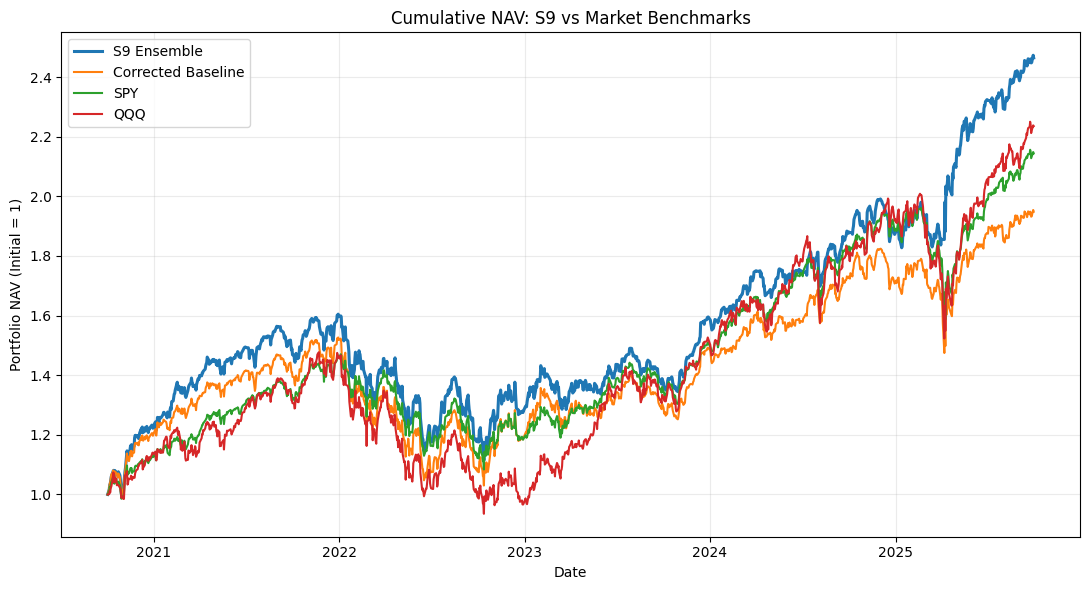

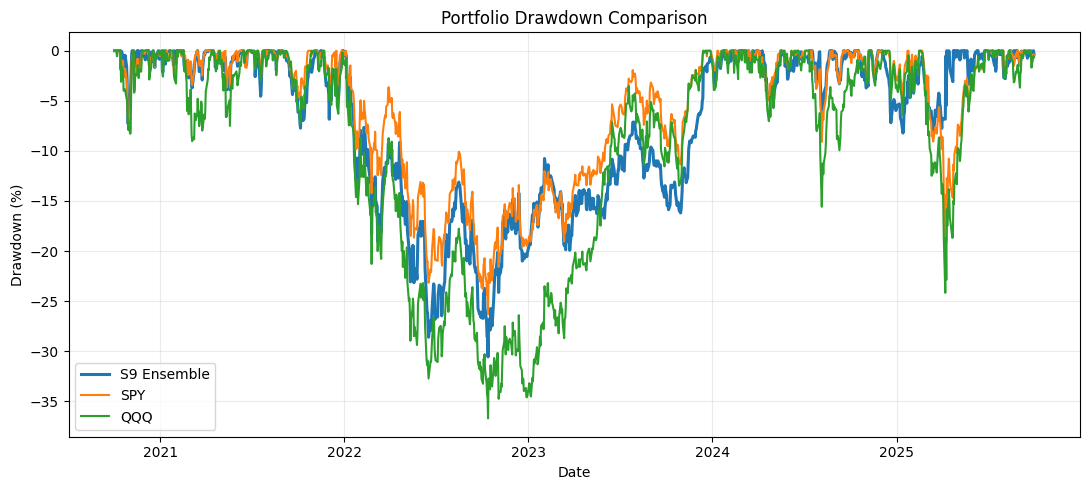


Final Report Performance Table:


,Period,Strategy,Final NAV,Cumulative Return,CAGR,Annual Volatility,Sharpe,Max Drawdown
0,Development,S9 Ensemble,1.5953,0.5953,0.1551,0.2044,0.8089,-0.3056
1,Development,Corrected Baseline,1.4917,0.4917,0.1314,0.2082,0.6980,-0.3254
2,Development,SPY,1.5082,0.5082,0.1353,0.1752,0.8128,-0.2629
3,Development,QQQ,1.5214,0.5214,0.1383,0.2352,0.6694,-0.3669
4,Validation,S9 Ensemble,1.1831,0.1831,0.1838,0.1209,1.4573,-0.0719
5,Validation,Corrected Baseline,1.1539,0.1539,0.1545,0.1262,1.2029,-0.0747
6,Validation,SPY,1.2654,0.2654,0.2664,0.1263,1.9351,-0.0910
7,Validation,QQQ,1.2812,0.2812,0.2823,0.1778,1.4894,-0.1558
8,Final Test 2025,S9 Ensemble,1.3087,0.3087,0.4370,0.1978,1.9509,-0.0758
9,Final Test 2025,Corrected Baseline,1.1343,0.1343,0.1851,0.2193,0.8910,-0.1765



Files saved to: results/strategy/ensemble_models/final_audit
Final NAV S9: 2.4642
Final NAV SPY: 2.1438
Final NAV QQQ: 2.2353

Final visualization and performance analysis completed.


In [ ]:

# Final S9 performance tables and visualizations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

audit_dir = ensemble_dir / "final_audit"
audit_dir.mkdir(parents=True, exist_ok=True)

# 1. Prepare aligned daily returns
bt = s9_full_backtest.reset_index(drop=True).copy()
baseline_bt = corrected_backtest.reset_index(drop=True).copy()
bench = aligned_comparison.reset_index(drop=True).copy()

assert len(bt) == len(baseline_bt) == len(bench)

assert np.array_equal(
    pd.to_datetime(bt["datadate"]).to_numpy(),
    pd.to_datetime(baseline_bt["datadate"]).to_numpy()
)

assert np.array_equal(
    pd.to_datetime(bt["datadate"]).to_numpy(),
    pd.to_datetime(bench["datadate"]).to_numpy()
)

returns = pd.DataFrame({
    "datadate": pd.to_datetime(bt["datadate"]),
    "next_trading_day": pd.to_datetime(bt["next_trading_day"]),
    "S9 Ensemble": bt["net_return"].to_numpy(),
    "Corrected Baseline": baseline_bt["net_return"].to_numpy(),
    "SPY": bench["SPY_return"].to_numpy(),
    "QQQ": bench["QQQ_return"].to_numpy()
})

strategies = [
    "S9 Ensemble",
    "Corrected Baseline",
    "SPY",
    "QQQ"
]

assert np.isfinite(returns[strategies].to_numpy()).all()


# 2. Calculate cumulative NAV

nav_dates = pd.DatetimeIndex(
    [returns["datadate"].iloc[0]]
    + returns["next_trading_day"].tolist()
)

nav_curves = pd.DataFrame({"Date": nav_dates})

for name in strategies:
    nav_curves[name] = np.r_[
        1.0,
        (1 + returns[name]).cumprod().to_numpy()
    ]

# Check against previously calculated final results
previous_final = final_comparison[
    final_comparison["Period"] == "Full Period"
].set_index("Strategy")["Final NAV"]

for name in strategies:
    assert np.isclose(
        nav_curves[name].iloc[-1],
        previous_final[name],
        rtol=1e-8,
        atol=1e-8
    )


# 3. Plot cumulative NAV

plt.figure(figsize=(11, 6))

for name in strategies:
    plt.plot(
        nav_curves["Date"],
        nav_curves[name],
        label=name,
        linewidth=2.2 if name == "S9 Ensemble" else 1.5
    )

plt.title("Cumulative NAV: S9 vs Market Benchmarks")
plt.xlabel("Date")
plt.ylabel("Portfolio NAV (Initial = 1)")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.savefig(
    audit_dir / "final_nav_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# 4. Calculate and plot drawdowns

drawdown_curves = pd.DataFrame({
    "Date": nav_dates
})

for name in strategies:
    nav = nav_curves[name].to_numpy()

    drawdown_curves[name] = (
        nav / np.maximum.accumulate(nav) - 1
    )

plt.figure(figsize=(11, 5))

for name in ["S9 Ensemble", "SPY", "QQQ"]:
    plt.plot(
        drawdown_curves["Date"],
        100 * drawdown_curves[name],
        label=name,
        linewidth=2.2 if name == "S9 Ensemble" else 1.5
    )

plt.title("Portfolio Drawdown Comparison")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.savefig(
    audit_dir / "final_drawdown_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()



# 5. Calculate within-year returns

# Exclude return intervals crossing calendar-year boundaries
annual_sample = returns[
    returns["datadate"].dt.year ==
    returns["next_trading_day"].dt.year
].copy()

annual_sample["Year"] = annual_sample["datadate"].dt.year

annual_rows = []

for year, group in annual_sample.groupby("Year"):
    row = {
        "Year": year,
        "Trading Intervals": len(group)
    }

    for name in strategies:
        row[name + " (%)"] = (
            (1 + group[name]).prod() - 1
        ) * 100

    annual_rows.append(row)

annual_returns = pd.DataFrame(annual_rows)

print("\nWithin-Year Returns (%):")
print("Cross-year intervals are excluded.")
print("2020 and 2025 are partial years.")
display(annual_returns.round(2))


# 6. Calculate performance for all research periods

report_periods = {
    "Development": ("2020-10-02", "2023-12-31"),
    "Validation": ("2024-01-01", "2024-12-31"),
    "Final Test 2025": ("2025-01-01", "2025-09-30"),
    "Full Period": ("2020-10-02", "2025-09-30")
}

report_rows = []

for period, (start, end) in report_periods.items():

    sample = returns[
        (returns["datadate"] >= pd.Timestamp(start))
        & (returns["next_trading_day"] <= pd.Timestamp(end))
    ].copy()

    assert not sample.empty

    years = (
        sample["next_trading_day"].iloc[-1]
        - sample["datadate"].iloc[0]
    ).days / 365.25

    for name in strategies:

        r = sample[name]
        nav = (1 + r).cumprod()
        nav_path = np.r_[1.0, nav.to_numpy()]

        volatility = r.std() * np.sqrt(252)

        report_rows.append({
            "Period": period,
            "Strategy": name,
            "Final NAV": nav.iloc[-1],
            "Cumulative Return": nav.iloc[-1] - 1,
            "CAGR": nav.iloc[-1] ** (1 / years) - 1,
            "Annual Volatility": volatility,
            "Sharpe": (
                r.mean() / r.std() * np.sqrt(252)
                if r.std() > 0 else np.nan
            ),
            "Max Drawdown": (
                nav_path / np.maximum.accumulate(nav_path) - 1
            ).min()
        })

final_report_metrics = pd.DataFrame(report_rows)

print("\nFinal Report Performance Table:")
display(final_report_metrics.round(4))


# 7. Save all figures and tables

nav_curves.to_csv(
    audit_dir / "final_nav_curves.csv",
    index=False
)

drawdown_curves.to_csv(
    audit_dir / "final_drawdown_curves.csv",
    index=False
)

annual_returns.to_csv(
    audit_dir / "annual_returns.csv",
    index=False
)

final_report_metrics.to_csv(
    audit_dir / "final_report_metrics.csv",
    index=False
)

print("\nFiles saved to:", audit_dir)
print("Final NAV S9:", round(nav_curves["S9 Ensemble"].iloc[-1], 4))
print("Final NAV SPY:", round(nav_curves["SPY"].iloc[-1], 4))
print("Final NAV QQQ:", round(nav_curves["QQQ"].iloc[-1], 4))

print("\nFinal visualization and performance analysis completed.")



### S9 Feature Importance Analysis

I use permutation importance to examine the contribution of financial features to the S9 ensemble. I select the Information Technology sector (Sector 45) and the rolling model window for 2024-09-30 as an illustrative example.

I train Random Forest, XGBoost, and LightGBM using the existing point-in-time training split. I average their predictions and measure feature importance by the decrease in mean validation Rank IC after permuting each feature within each validation quarter.

This analysis explains one representative model window. It does not represent feature importance across all sectors or the full backtest period.


In [ ]:

# S9: Ensemble feature importance using validation Rank IC

from scipy.stats import spearmanr
import matplotlib.pyplot as plt

fi_sector = 45
fi_quarter = pd.Timestamp("2024-09-30")
fi_decision_date = fi_quarter + pd.Timedelta(days=1)

fi_dir = strategy_path / "ensemble_models" / "feature_importance"
fi_dir.mkdir(parents=True, exist_ok=True)

# Use the same PIT split and model parameters as S9
fi_df = pit_model_data[
    pit_model_data["gsector"] == fi_sector
].copy()

fi_train, fi_val, _ = prepare_pit_split(
    fi_df, fi_quarter, fi_decision_date
)

fi_val = fi_val.reset_index(drop=True)

assert not fi_train.empty and not fi_val.empty
assert (fi_train["label_available_date"] < fi_decision_date).all()
assert (fi_val["label_available_date"] < fi_decision_date).all()

fi_X_train = fi_train[feature_cols]
fi_y_train = fi_train["y_return"]

fi_X_val = fi_val[feature_cols].copy()
fi_y_val = fi_val["y_return"].to_numpy()

# Train the three models from the S9 ensemble
fi_models = make_pit_models()

for model in fi_models.values():
    model.fit(fi_X_train, fi_y_train)

def fi_predict(X):
    return np.mean(
        np.column_stack([
            model.predict(X)
            for model in fi_models.values()
        ]),
        axis=1
    )

# Evaluate Rank IC within each validation quarter
fi_groups = [
    group.index.to_numpy()
    for _, group in fi_val.groupby("date")
    if len(group) >= 8
    and group["y_return"].nunique() > 1
]

assert len(fi_groups) >= 2, (
    "Insufficient validation quarters for Rank IC."
)

def fi_mean_rank_ic(predictions):
    values = [
        spearmanr(
            fi_y_val[idx],
            predictions[idx]
        ).statistic
        for idx in fi_groups
    ]
    values = np.asarray(values, dtype=float)
    return np.nanmean(values)

fi_base_ic = fi_mean_rank_ic(fi_predict(fi_X_val))

# Permute each feature within validation quarters
fi_rng = np.random.default_rng(42)
fi_rows = []
fi_repeats = 3

for col in feature_cols:
    ic_drops = []

    for _ in range(fi_repeats):
        X_perm = fi_X_val.copy()

        for idx in fi_groups:
            X_perm.loc[idx, col] = fi_rng.permutation(
                X_perm.loc[idx, col].to_numpy()
            )

        permuted_ic = fi_mean_rank_ic(fi_predict(X_perm))
        ic_drops.append(fi_base_ic - permuted_ic)

    fi_rows.append({
        "Feature": col,
        "Importance": np.mean(ic_drops),
        "Std": np.std(ic_drops),
    })

fi_importance = (
    pd.DataFrame(fi_rows)
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

# Display the 15 highest-importance features
fi_top15 = fi_importance.head(15)

print("Sector:", fi_sector)
print("Prediction quarter:", fi_quarter.date())
print("Training observations:", len(fi_train))
print("Validation observations:", len(fi_val))
print("Validation quarters:", len(fi_groups))
print("Baseline mean Rank IC:", round(fi_base_ic, 4))

print("\nTop 15 Features:")
display(fi_top15.round(4))

# Plot feature importance
plt.figure(figsize=(9, 6))

plt.barh(
    fi_top15["Feature"][::-1],
    fi_top15["Importance"][::-1]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Mean Decrease in Validation Rank IC")
plt.title("S9 Ensemble Feature Importance (Sector 45)")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

plt.savefig(
    fi_dir / "s9_feature_importance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Save the full ranking
fi_importance.to_csv(
    fi_dir / "s9_feature_importance.csv",
    index=False
)

print("\nFeature importance analysis completed.")



### Feature Importance Results

I use permutation importance to evaluate the S9 ensemble in Sector 45 (Information Technology) for the 2024-09-30 prediction window.

BPS has the highest importance (0.0258), followed by fixed_asset_turnover (0.0203) and ocf_to_sales (0.0189). This suggests that book value, asset efficiency, and operating cash flow contribute to the model's stock ranking.

However, the baseline validation Rank IC is -0.0523, indicating weak ranking performance in this window. The analysis uses only three validation quarters, and some importance estimates have relatively large standard deviations.

Overall, these results show which features influence the ensemble's predictions, but they do not establish strong predictive performance across all sectors or time periods.



## Final Findings and Limitations

I tested nine strategy modifications after reproducing and diagnosing the original baseline. The equal-weight ensemble of Random Forest, XGBoost, and LightGBM (S9) gave the strongest overall exploratory results.

From October 2020 to September 2025, S9 achieved a net final NAV of 2.4642, a CAGR of 19.79%, and a Sharpe ratio of 1.0525. It outperformed SPY and QQQ over the full backtest period, although it underperformed SPY during the 2024 validation period.

The final result was robust to excluding the identified filing-date exceptions. However, incomplete historical price coverage, uncertain filing timestamps, possible selection bias, and repeated validation use remain limitations. Further point-in-time data verification is needed before drawing stronger conclusions.
